# Preparations

Installing required packages

In [4]:
# Remove hashtags if installation is needed
# %pip install python-calamine
# %pip install fiona==1.9.5 --quiet  
# %pip install contextily  
# %pip install jupyterlab_theme_solarized_dark
# !pip install cartopy
# !pip install curvenote
# !pip install pandoc
# %pip install calamine seaborn 
# %pip install geopandas
# %pip install rasterio
# %pip install fiona
# %pip install contextily
# %pip install cartopy
  
print("✓ Installed – restart the kernel if this is the first time.") 

✓ Installed – restart the kernel if this is the first time.


Importing packages

In [60]:
import pandas as pd  
import seaborn as sns  
import matplotlib.pyplot as plt  
import matplotlib as mpl  
from matplotlib.ticker import FuncFormatter  
import warnings  
import os, ast, hashlib  
import pathlib
import winreg  
import geopandas as gpd  
import rasterio  
from shapely.geometry import Point
import numpy as np  
from collections import Counter  
from IPython.display import display  
from collections import Counter, defaultdict
from shapely.ops import unary_union  
from shapely import make_valid
from shapely.validation import make_valid  
import pyproj  
from shapely.ops import transform  
import functools 
import IPython.display as disp  
from tqdm import tqdm  
from shapely.geometry import shape, Point, Polygon, MultiPolygon  
from shapely.geometry import Point, MultiPolygon, LineString  
import shapely, fiona, glob, pathlib, warnings  
import contextily as ctx     
import warnings, re
import matplotlib.patches as patches
from math import radians, sin, cos, sqrt, atan2  
import plotly.graph_objects as go
import plotly.io as pio
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.path as mpath

In [2]:
warnings.filterwarnings('ignore', category=UserWarning, module='openpyxl')
mpl.rcParams['font.family'] = 'DejaVu Sans'      # use a glyph-complete font  
mpl.rcParams['axes.unicode_minus'] = False       # render minus / hyphen cleanly  

warnings.filterwarnings("ignore")  

Setting the correct working directory

In [3]:
pwd

'C:\\Users\\hamod4691\\OneDrive - UiT Office 365\\JupyterLab\\Data paper'

In [4]:
os.chdir ('C:\\Users\\hamod4691\\OneDrive - UiT Office 365\\JupyterLab\\Data paper')

In [5]:
pwd

'C:\\Users\\hamod4691\\OneDrive - UiT Office 365\\JupyterLab\\Data paper'

Adding additional path

In [6]:
def add_to_user_path(new_path):  
    # Open the user environment variables key  
    with winreg.OpenKey(winreg.HKEY_CURRENT_USER, r'Environment', 0, winreg.KEY_ALL_ACCESS) as key:  
        try:  
            current_path, _ = winreg.QueryValueEx(key, 'PATH')  
        except FileNotFoundError:  
            current_path = ''  
        if new_path not in current_path:  
            new_path_value = current_path + os.pathsep + new_path if current_path else new_path  
            winreg.SetValueEx(key, 'PATH', 0, winreg.REG_EXPAND_SZ, new_path_value)  
            print('Added to user PATH. You must restart JupyterLab or your computer for this to take effect.')  
        else:  
            print('Path already present in user PATH.')  
  
# Usage  
add_to_user_path(r'C:\Users\hamod4691\AppData\Roaming\Python\Python312\Scripts')  

Path already present in user PATH.


In [7]:
pwd

'C:\\Users\\hamod4691\\OneDrive - UiT Office 365\\JupyterLab\\Data paper'

Set global font sizes

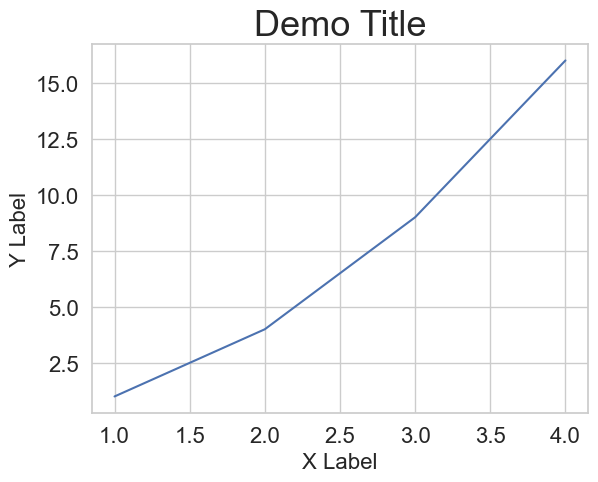

In [8]:
GLOBAL_FONT_SIZE = 16
mpl.rcParams.update({
    'font.size': GLOBAL_FONT_SIZE,
    'axes.titlesize': GLOBAL_FONT_SIZE + 10,
    'axes.labelsize': GLOBAL_FONT_SIZE,
    'xtick.labelsize': GLOBAL_FONT_SIZE,
    'ytick.labelsize': GLOBAL_FONT_SIZE,
    'legend.fontsize': GLOBAL_FONT_SIZE
})

sns.set_theme(context='notebook', style='whitegrid')
sns.set_context('notebook', rc={
    'font.size': GLOBAL_FONT_SIZE,
    'axes.titlesize': GLOBAL_FONT_SIZE + 10,
    'axes.labelsize': GLOBAL_FONT_SIZE,
    'xtick.labelsize': GLOBAL_FONT_SIZE,
    'ytick.labelsize': GLOBAL_FONT_SIZE,
    'legend.fontsize': GLOBAL_FONT_SIZE
})

# Optional quick demo
ax = sns.lineplot(x=[1,2,3,4], y=[1,4,9,16])
ax.set_title('Demo Title')
ax.set_xlabel('X Label')
ax.set_ylabel('Y Label')
plt.show()

Set global font template

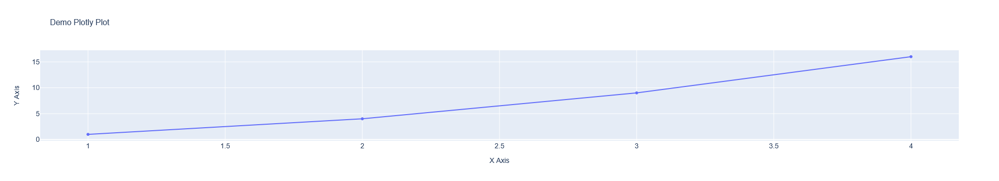

In [10]:
custom_template = go.layout.Template()
custom_template.layout = go.Layout(
    font=dict(family='Arial, sans-serif', size=14),
    title=dict(font=dict(size=16)),
    xaxis=dict(title=dict(font=dict(size=14))),
    yaxis=dict(title=dict(font=dict(size=14)))
)

pio.templates['custom_font'] = custom_template
pio.templates.default = 'plotly+custom_font'

# Optional quick demo
fig = go.Figure(data=go.Scatter(x=[1,2,3,4], y=[1,4,9,16], mode='lines+markers'))
fig.update_layout(title='Demo Plotly Plot', xaxis_title='X Axis', yaxis_title='Y Axis')
fig.show()

### Checking original file

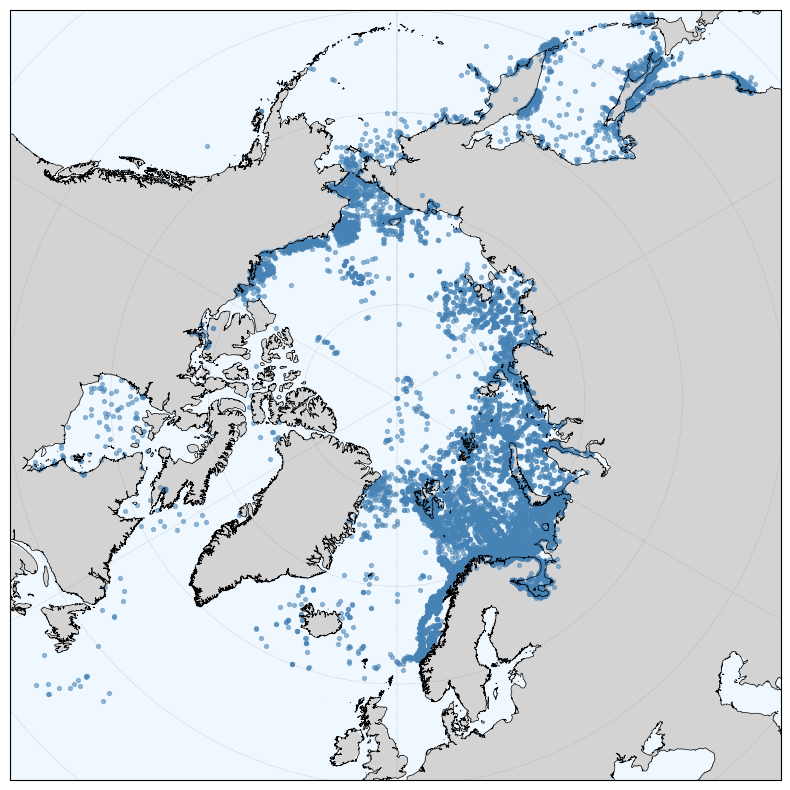

Plotted 12570 stations


In [2]:
# Load the data
FILEPATH = 'original.xlsx'
df_station = pd.read_excel(FILEPATH, sheet_name='Station')

# Choose coordinates: prefer LatStart/LonStart, else LatEnd/LonEnd, else LatTarget/LonTarget
lat = df_station['LatStart'].copy()
lon = df_station['LonStart'].copy()
lat = lat.fillna(df_station['LatEnd'])
lon = lon.fillna(df_station['LonEnd'])
lat = lat.fillna(df_station['LatTarget'])
lon = lon.fillna(df_station['LonTarget'])

# Create coordinates dataframe
coords = pd.DataFrame({
    'lat': pd.to_numeric(lat, errors='coerce'),
    'lon': pd.to_numeric(lon, errors='coerce')
})
coords = coords.dropna()

# Filter to plausible lat/lon ranges
coords = coords[(coords['lat'] >= -90) & (coords['lat'] <= 90) &
                (coords['lon'] >= -180) & (coords['lon'] <= 180)]

# Create the plot
plt.figure(figsize=(10, 10))
proj = ccrs.NorthPolarStereo()
ax = plt.axes(projection=proj)
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor='lightgray')
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')
ax.coastlines(resolution='10m', linewidth=0.5, color='black')
ax.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')

# Plot the station points
ax.scatter(coords['lon'].values, coords['lat'].values,
           s=8, color='steelblue', alpha=0.5, transform=ccrs.PlateCarree())
plt.savefig("map_stations.png", dpi=300, bbox_inches="tight", facecolor="white") 
plt.show()

print(f'Plotted {len(coords)} stations')

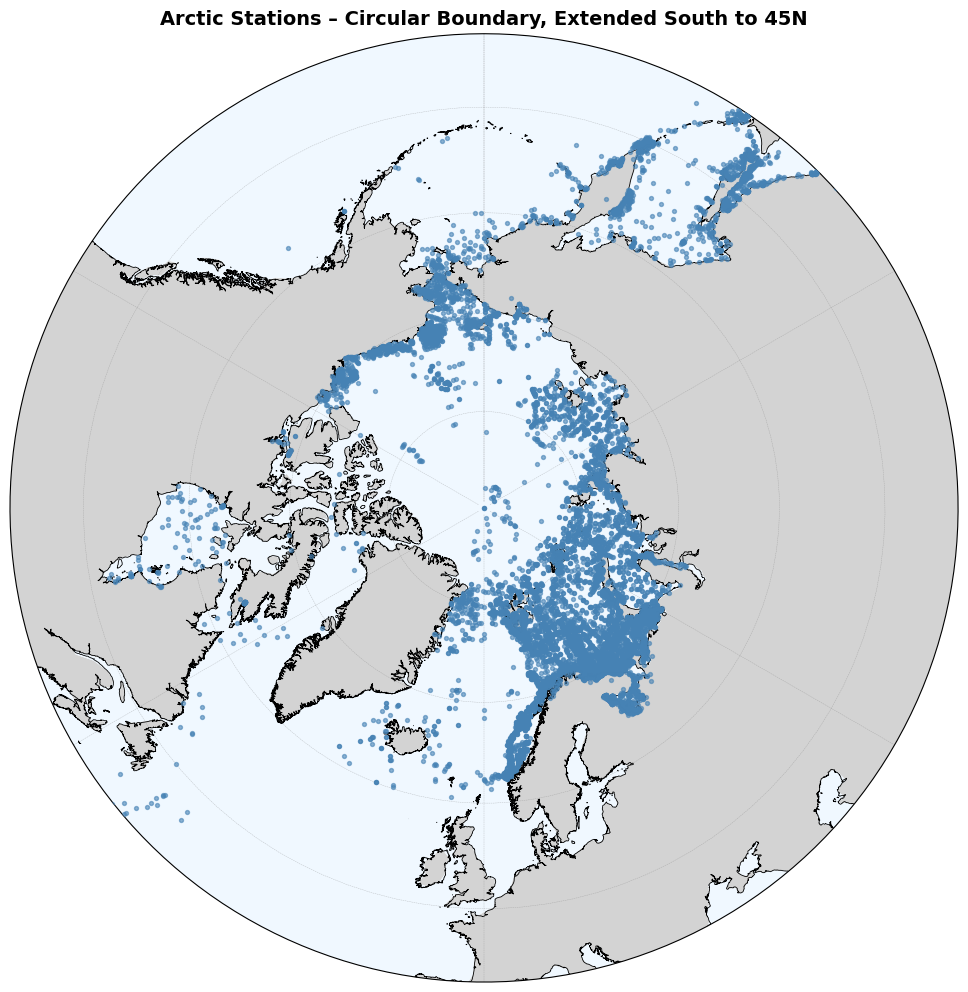

Plotted circular map with extended extent and larger circular boundary


In [16]:
fig = plt.figure(figsize=(10, 10))
proj = ccrs.NorthPolarStereo()
ax = plt.axes(projection=proj)

# Extend a bit further south to avoid clipping lower-lat stations
ax.set_extent([-180, 180, 45, 90], crs=ccrs.PlateCarree())

ax.add_feature(cfeature.LAND, facecolor='lightgray')
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')
ax.coastlines(resolution='10m', linewidth=0.6, color='black')
ax.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')

# Plot stations
ax.scatter(coords['lon'].values, coords['lat'].values,
           s=8, color='steelblue', alpha=0.6, transform=ccrs.PlateCarree(), zorder=3)

# Slightly larger circular boundary to minimize clipping
theta = np.linspace(0, 2*np.pi, 200)
center = [0.5, 0.5]
radius = 0.52  # a touch larger than 0.5
verts = np.vstack([np.sin(theta), np.cos(theta)]).T
circle = mpath.Path(verts * radius + center)
ax.set_boundary(circle, transform=ax.transAxes)

plt.title('Arctic Stations – Circular Boundary, Extended South to 45N', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()
print('Plotted circular map with extended extent and larger circular boundary')

In [9]:
file_path = 'original.xlsx'
dataframes = pd.read_excel(file_path, sheet_name=None)  
print("Available sheets:")  
for sheet in dataframes:  
    print("-", sheet)  

Available sheets:
- Cruise
- Station
- Device
- Sample
- SubSample
- Subset
- Biota
- IndividualMeasure.meio
- Dataset
- Gear
- Taxon
- Ship
- Person
- TaxCover
- Lifestage
- Country
- CRS
- PosSys
- Glossary


Nr of entries per sheet

In [10]:
xlsx  = 'original.xlsx'  
sheets = ['Cruise', 'Station', 'Device', 'Sample',  
          'SubSample', 'Subset', 'Biota', 'Dataset']  
  
for sh in sheets:  
    n = len(pd.read_excel(xlsx, sheet_name=sh))  
    print(f'{sh}: {n}')  

Cruise: 1212
Station: 12570
Device: 13689
Sample: 14287
SubSample: 14954
Subset: 14982
Biota: 249141
Dataset: 57


### Checking whether to use StationID or DeviceID for spatial compilations

StationID: 

In [11]:
# --- 1. Load data ------------------------------------------------  
xlsx_file = 'original.xlsx'          
sheet     = 'Subset'  
  
subset = pd.read_excel(xlsx_file, sheet_name=sheet)  
subset.columns = [c.strip() for c in subset.columns]   # remove leading/trailing blanks  
  
# --- 2. Identify stations with >1 device ------------------------  
dev_counts   = subset.groupby('StationID')['DeviceID'].nunique()  
multi_dev_ID = dev_counts[dev_counts > 1].index  
rows_multi_dev = subset[subset['StationID'].isin(multi_dev_ID)]  
  
# --- 3. Identify stations with >1 taxonomic coverage ------------  
tax_counts   = subset.groupby('StationID')['TaxonomicCoverage'].nunique()  
multi_tax_ID = tax_counts[tax_counts > 1].index  
rows_multi_tax = subset[subset['StationID'].isin(multi_tax_ID)]  
  
# --- 4. Export filtered lists -----------------------------------  
rows_multi_dev.to_excel('rows_multiple_devices.xlsx', index=False)  
rows_multi_tax.to_excel('rows_multiple_taxcov.xlsx', index=False)  
  
print('Saved: rows_multiple_devices.xlsx  |  rows_multiple_taxcov.xlsx')  
# --- 7. Quick glimpse of exported tables ------------------------  
print('First 5 rows – multiple devices:')  
display(rows_multi_dev.head())  
  
print('\nFirst 5 rows – multiple taxonomic coverage:')  
display(rows_multi_tax.head())  

Saved: rows_multiple_devices.xlsx  |  rows_multiple_taxcov.xlsx
First 5 rows – multiple devices:


,CruiseID,StationID,DeviceID,SampleID,SubSampleID,SubsetID,Cruise,Station,Device,Sample,SubSample,Subset,Project,TaxonomicResolution,TaxonomicCoverage
946,1395,16667,22325,22968,23049,23314,AMK54,4994,AMK54_4994_grab,1,1,1,Vedenin et al 2015,species,all
947,1395,16667,22325,22969,23050,23315,AMK54,4994,AMK54_4994_grab,2,1,1,Vedenin et al 2015,species,all
948,1395,16667,22325,22970,23051,23316,AMK54,4994,AMK54_4994_grab,3,1,1,Vedenin et al 2015,species,all
949,1395,16667,22333,23054,23135,23400,AMK54,4994,AMK54_4994_trawl,1,1,1,Vedenin et al 2015,species,all
950,1395,16668,22326,22971,23052,23317,AMK54,4995,AMK54_4995_grab,1,1,1,Vedenin et al 2015,species,all



First 5 rows – multiple taxonomic coverage:


,CruiseID,StationID,DeviceID,SampleID,SubSampleID,SubsetID,Cruise,Station,Device,Sample,SubSample,Subset,Project,TaxonomicResolution,TaxonomicCoverage
1207,1383,16500,22239,22623,22700,22965,M85/3,983-1,EBS,1,1,1,Uhlir et al 2021 Cumacea,species,Cumacea
1208,1383,16500,22143,22527,22604,22869,M85/3,983-1,RP Sledge,1,1,1,Brix et al 2019 Isopoda,species,Isopoda
1212,1383,16481,22254,22638,22715,22980,M85/3,1010-1,EBS,1,1,1,Uhlir et al 2021 Cumacea,species,Cumacea
1213,1383,16481,22124,22508,22585,22850,M85/3,1010-1,RP Sledge,1,1,1,Brix et al 2019 Isopoda,species,Isopoda
1223,1383,16511,22247,22631,22708,22973,M85/3,1057-1,EBS,1,1,1,Uhlir et al 2021 Cumacea,species,Cumacea


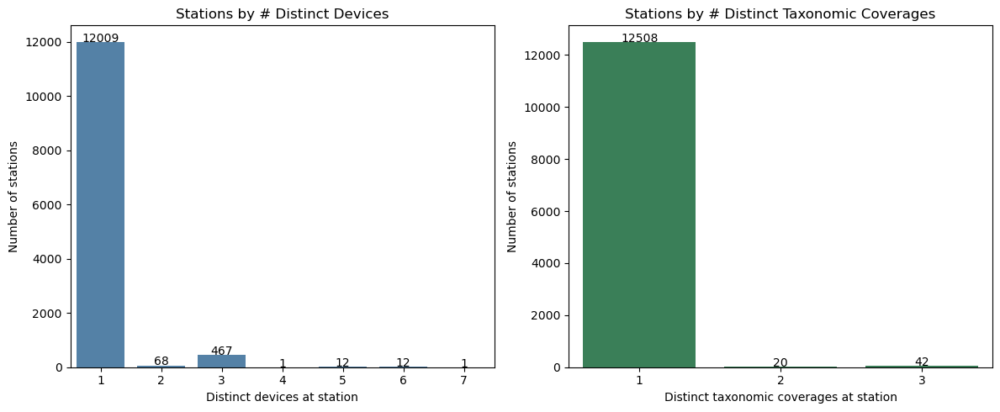

In [12]:
# --- 5. Prep data for summary plots -----------------------------  
dev_summary  = dev_counts.value_counts().sort_index()  
tax_summary  = tax_counts.value_counts().sort_index()  
  
# --- 6. Plot -----------------------------------------------------  
plt.figure(figsize=(12, 5))  
  
# left subplot: devices  
plt.subplot(1, 2, 1)  
sns.barplot(x=dev_summary.index, y=dev_summary.values, color='steelblue')  
plt.title('Stations by # Distinct Devices')  
plt.xlabel('Distinct devices at station')  
plt.ylabel('Number of stations')  
for i, v in enumerate(dev_summary.values):  
    plt.text(i, v + 1, str(v), ha='center')  
  
# right subplot: taxonomy  
plt.subplot(1, 2, 2)  
sns.barplot(x=tax_summary.index, y=tax_summary.values, color='seagreen')  
plt.title('Stations by # Distinct Taxonomic Coverages')  
plt.xlabel('Distinct taxonomic coverages at station')  
plt.ylabel('Number of stations')  
for i, v in enumerate(tax_summary.values):  
    plt.text(i, v + 1, str(v), ha='center')  
  
plt.tight_layout()  
plt.show()  

DeviceID: 

In [13]:
# 1) Load the Subset sheet  
xlsx   = 'original.xlsx'                       
subset = pd.read_excel(xlsx, sheet_name='Subset')  
subset.columns = [c.strip() for c in subset.columns]   # tidy headers  
  
# 2) Find DeviceIDs with multiple coverages  
cov_counts  = subset.groupby('DeviceID')['TaxonomicCoverage'].nunique()  
multi_cov_ids = cov_counts[cov_counts > 1].index           
  
# 3) Slice rows for those devices  
rows_multi_cov = subset[subset['DeviceID'].isin(multi_cov_ids)]  
  
# 4) Display the distinct DeviceID-Coverage pairs  
display(  
    rows_multi_cov[['DeviceID', 'TaxonomicCoverage']]  
    .drop_duplicates()  
    .sort_values(['DeviceID', 'TaxonomicCoverage'])  
    .reset_index(drop=True)  
)  
  
print('Devices with more than one coverage:', len(multi_cov_ids))  

,DeviceID,TaxonomicCoverage
0,22741,Meiofauna
1,22741,Nematoda
2,22742,Meiofauna
3,22742,Nematoda
4,22743,Meiofauna
5,22743,Nematoda
6,22744,Meiofauna
7,22744,Nematoda
8,22745,Meiofauna
9,22745,Nematoda


Devices with more than one coverage: 7


Nematoda and meiofauna can be merged in the same category

### --> Choosing DeviceID for spatial compilations

### Adding Realm, Title, Keywords, DateStart, LatStart and LonStart to Subset

In [14]:
# ---------- 1. Load all sheets from original.xlsx ----------  
xlsx = 'original.xlsx'                 
  
subset  = pd.read_excel(xlsx, sheet_name='Subset')  
dataset = pd.read_excel(xlsx, sheet_name='Dataset')  
station = pd.read_excel(xlsx, sheet_name='Station')  
  
# ---------- 2. Clean column names (strip whitespace) --------  
subset.columns  = [c.strip() for c in subset.columns]  
dataset.columns = [c.strip() for c in dataset.columns]  
station.columns = [c.strip() for c in station.columns]  
  
# ---------- 3. Merge Dataset info into Subset ---------------  
# Dataset.Name corresponds to Subset.Project  
dataset_slice = dataset[['Name', 'Realm', 'Title', 'Keywords']].drop_duplicates()  
dataset_slice = dataset_slice.rename(columns={'Name': 'Project'})     # align key names  
  
subset_dataset = subset.merge(dataset_slice, on='Project', how='left')  
  
# ---------- 4. Merge Station coordinates into result --------  
station_slice = station[['StationID', 'DateStart', 'LatStart', 'LonStart']].drop_duplicates()  
  
full_merged = subset_dataset.merge(station_slice, on='StationID', how='left')  
  
# ---------- 5. Save to Excel --------------------------------  
outfile = 'subset.xlsx'  
full_merged.to_excel(outfile, index=False)  
print('✓  Merges complete — saved to', outfile)  
  
# ---------- 6. Quick preview --------------------------------  
display(full_merged.head())  

✓  Merges complete — saved to subset.xlsx


,CruiseID,StationID,DeviceID,SampleID,SubSampleID,SubsetID,Cruise,Station,Device,Sample,...,Subset,Project,TaxonomicResolution,TaxonomicCoverage,Realm,Title,Keywords,DateStart,LatStart,LonStart
0,823,7368,7561,7562,7562,7827,C-3,1696,1,1,...,1,Benthos ArcOD Sirenko (a),species,Megabenthos (no polychaetes),Arctic,Occurrences of macro- and megabenthic organism...,Arctic; Arctic seas; megabenthos; macrobenthos...,1948-07-12,73.70,27.32
1,823,7369,7562,7563,7563,7828,C-3,1697,1,1,...,1,Benthos ArcOD Sirenko (a),species,Megabenthos (no polychaetes),Arctic,Occurrences of macro- and megabenthic organism...,Arctic; Arctic seas; megabenthos; macrobenthos...,1948-07-12,74.03,27.25
2,823,7370,7563,7564,7564,7829,C-3,1698,1,1,...,1,Benthos ArcOD Sirenko (a),species,Megabenthos (no polychaetes),Arctic,Occurrences of macro- and megabenthic organism...,Arctic; Arctic seas; megabenthos; macrobenthos...,1948-07-13,76.07,27.02
3,823,7371,7564,7565,7565,7830,C-3,1699,1,1,...,1,Benthos ArcOD Sirenko (a),species,Megabenthos (no polychaetes),Arctic,Occurrences of macro- and megabenthic organism...,Arctic; Arctic seas; megabenthos; macrobenthos...,1948-07-14,76.40,31.05
4,823,7372,7565,7566,7566,7831,C-3,1700,1,1,...,1,Benthos ArcOD Sirenko (a),species,Megabenthos (no polychaetes),Arctic,Occurrences of macro- and megabenthic organism...,Arctic; Arctic seas; megabenthos; macrobenthos...,1948-07-15,74.97,31.57


# Cleaning

### Extract bathymetry to stations 

In [15]:
# Load subset metadata  
subset_df = pd.read_excel('subset.xlsx', sheet_name='Sheet1')  
print("Preview of subset metadata:")  
print(subset_df[['LatStart', 'LonStart']].head())  

Preview of subset metadata:
   LatStart  LonStart
0     73.70     27.32
1     74.03     27.25
2     76.07     27.02
3     76.40     31.05
4     74.97     31.57


In [16]:
# Load rasters and check their CRS  
ibcao_path = 'Bathymetry/IBCAO/ibcao_v5_2024_100m_ice.tiff'  
elevation_path = 'Bathymetry/GEBCO/elevation_Layer.tif'  # The GEBCO raster
  
with rasterio.open(ibcao_path) as src_ibcao:  
    ibcao_crs = src_ibcao.crs  
    print("IBCAO raster CRS:", ibcao_crs)  
  
with rasterio.open(elevation_path) as src_elev:  
    elev_crs = src_elev.crs  
    print("Elevation raster CRS:", elev_crs)  

IBCAO raster CRS: EPSG:3996
Elevation raster CRS: EPSG:4326


In [17]:
# Transform subset coordinates to IBCAO raster CRS  
gdf = gpd.GeoDataFrame(  
    subset_df,  
    geometry=gpd.points_from_xy(subset_df['LonStart'], subset_df['LatStart']),  
    crs='EPSG:4326'  
)  
gdf_3996 = gdf.to_crs('EPSG:3996')  
print("Transformed coordinates (EPSG:3996):")  
print(gdf_3996[['LatStart', 'LonStart', 'geometry']].head())  

Transformed coordinates (EPSG:3996):
   LatStart  LonStart                         geometry
0     73.70     27.32  POINT (826715.631 -1600361.286)
1     74.03     27.25  POINT (807850.476 -1568538.624)
2     76.07     27.02   POINT (698110.97 -1368938.404)
3     76.40     31.05  POINT (773643.232 -1285017.121)
4     74.97     31.57  POINT (868715.789 -1413735.447)


In [18]:
# Extract IBCAO bathymetry values at subset locations  
coords_3996 = [(geom.x, geom.y) for geom in gdf_3996.geometry]  
with rasterio.open(ibcao_path) as src_ibcao:  
    ibcao_values = list(src_ibcao.sample(coords_3996))  
    ibcao_values = np.array(ibcao_values).flatten()  
gdf_3996['ibcao_bathy'] = ibcao_values  
print("IBCAO bathymetry values at subsets:")  
print(gdf_3996[['LatStart', 'LonStart', 'ibcao_bathy']].head())  

IBCAO bathymetry values at subsets:
   LatStart  LonStart  ibcao_bathy
0     73.70     27.32  -405.844971
1     74.03     27.25  -413.303802
2     76.07     27.02  -208.454987
3     76.40     31.05  -307.636139
4     74.97     31.57  -329.218658


In [19]:
# Extract elevation raster values at original WGS84 coordinates  
coords_4326 = [(row['LonStart'], row['LatStart']) for idx, row in subset_df.iterrows()]  
with rasterio.open(elevation_path) as src_elev:  
    elev_values = list(src_elev.sample(coords_4326))  
    elev_values = np.array(elev_values).flatten()  
gdf_3996['elevation_bathy'] = elev_values  
print("Elevation raster values at subsets:")  
print(gdf_3996[['LatStart', 'LonStart', 'elevation_bathy']].head())  

Elevation raster values at subsets:
   LatStart  LonStart  elevation_bathy
0     73.70     27.32             -405
1     74.03     27.25             -413
2     76.07     27.02             -208
3     76.40     31.05             -308
4     74.97     31.57             -330


In [20]:
# Merge bathymetry values using the specified logic  
def strict_merge_bathy(ibcao, elev):  
    if ibcao == 0:  
        if elev == 0:  
            return 0  
        else:  
            return elev  
    return ibcao  
  
gdf_3996['bathy'] = [strict_merge_bathy(i, e) for i, e in zip(gdf_3996['ibcao_bathy'], gdf_3996['elevation_bathy'])]  
print("Merged bathymetry (priority IBCAO, preserve zeros only if both are zero):")  
print(gdf_3996[['LatStart', 'LonStart', 'ibcao_bathy', 'elevation_bathy', 'bathy']].head())  

Merged bathymetry (priority IBCAO, preserve zeros only if both are zero):
   LatStart  LonStart  ibcao_bathy  elevation_bathy       bathy
0     73.70     27.32  -405.844971             -405 -405.844971
1     74.03     27.25  -413.303802             -413 -413.303802
2     76.07     27.02  -208.454987             -208 -208.454987
3     76.40     31.05  -307.636139             -308 -307.636139
4     74.97     31.57  -329.218658             -330 -329.218658


In [21]:
# Calculate discrepancy column  
gdf_3996['bathy_discrepancy'] = gdf_3996['ibcao_bathy'] - gdf_3996['elevation_bathy']  
print("Preview with discrepancy column:")  
print(gdf_3996[['LatStart', 'LonStart', 'ibcao_bathy', 'elevation_bathy', 'bathy', 'bathy_discrepancy']].head())  

Preview with discrepancy column:
   LatStart  LonStart  ibcao_bathy  elevation_bathy       bathy  \
0     73.70     27.32  -405.844971             -405 -405.844971   
1     74.03     27.25  -413.303802             -413 -413.303802   
2     76.07     27.02  -208.454987             -208 -208.454987   
3     76.40     31.05  -307.636139             -308 -307.636139   
4     74.97     31.57  -329.218658             -330 -329.218658   

   bathy_discrepancy  
0          -0.844971  
1          -0.303802  
2          -0.454987  
3           0.363861  
4           0.781342  


In [22]:
# Save the final dataframe to Excel  
output_df = gdf_3996.drop(columns=['geometry'])  
output_df.to_excel('subset_bathy.xlsx', index=False)  
print("subset_bathy.xlsx saved with merged bathymetry and discrepancy columns.")  

subset_bathy.xlsx saved with merged bathymetry and discrepancy columns.


### Change the raster value of two stations manually 
Two of the stations are exactly in-between raster cells, leading to strange values in the bathymetry column. I have chosen to manually give them the mean value of the surrounding raster cells, after inspection in ArcGIS Pro. This is done for StationID 6689 and 6690. 

Raster values of surrounding cells:  
6689: -91, -92  
6690: -87, -82, -83, -85  

Mean values:  
6689: -91.5  
6690: -84.25

In [23]:
# 1. Load the file  
df = pd.read_excel('subset_bathy.xlsx', sheet_name='Sheet1', engine='calamine')  
  
# 2. Update the bathy values  
df.loc[df['StationID'] == 6689, 'bathy'] = -91.5  
df.loc[df['StationID'] == 6690, 'bathy'] = -84.25  
  
# 3. (Optional) verify  
print(df.loc[df['StationID'].isin([6689, 6690]), ['StationID', 'bathy']])  
  
# 4. Save the updated file  
df.to_excel('subset_bathy.xlsx', index=False)  
  
print('Saved as subset_bathy.xlsx')  

       StationID  bathy
13477       6689 -91.50
13478       6690 -84.25
Saved as subset_bathy.xlsx


### Split dataset in three

In [24]:
# Load extracted dataset
df = pd.read_excel('subset_bathy.xlsx')

# Define bathy column name
bathy_col = 'bathy'

# Split ranges
above_twenty = df[df[bathy_col] > 20]
water_surface = df[(df[bathy_col] >= 0) & (df[bathy_col] <= 20)]
below_zero = df[df[bathy_col] < 0]

# Export subsets
above_twenty.to_excel('subsets_above20.xlsx', index=False)
water_surface.to_excel('subsets_0_20.xlsx', index=False)
below_zero.to_excel('subsets_below0.xlsx', index=False)

# Summaries
print('Above 20 count:', len(above_twenty))
print('0–20 count:', len(water_surface))
print('Below 0 count:', len(below_zero))

Above 20 count: 699
0–20 count: 790
Below 0 count: 13493


### Split dataset in two (remove all records >20 m)

In [25]:
# Load extracted dataset  
df = pd.read_excel('subset_bathy.xlsx')  
  
# Split based on zero threshold  
above_twenty = df[df['bathy'] > 20]  
below_equal_twenty = df[df['bathy'] <= 20]  
  
# Export split datasets  
above_twenty.to_excel('subsets_land.xlsx', index=False)  
below_equal_twenty.to_excel('subsets_water.xlsx', index=False)  
  
# Summary  
print(f"Split complete:")  
print(f"Above ten: {len(above_twenty)} records")  
print(f"Below or equal to ten: {len(below_equal_twenty)} records")  

Split complete:
Above ten: 699 records
Below or equal to ten: 14283 records


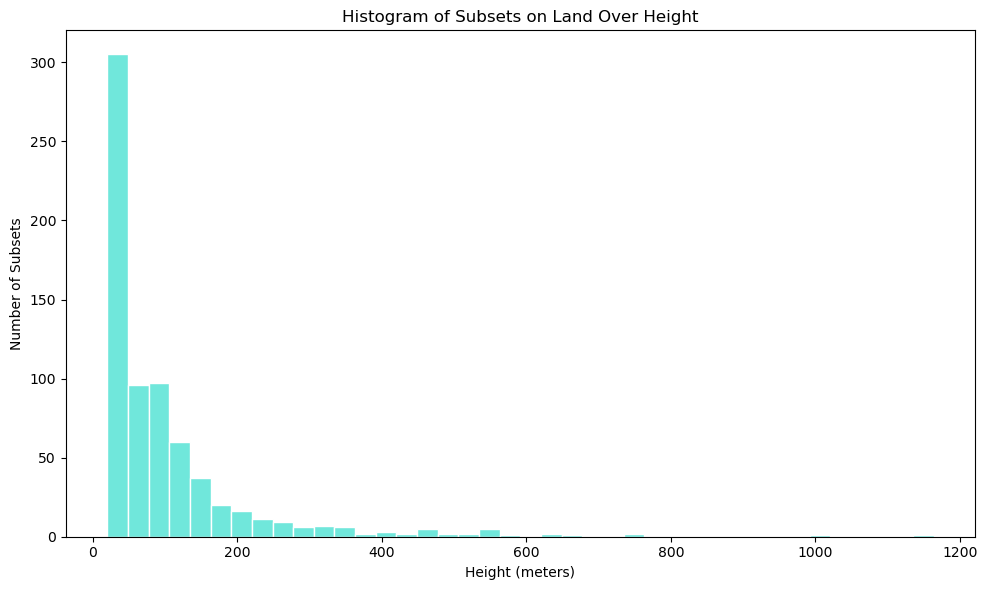

count     699.000000
mean      100.985755
std       121.713538
min        20.102852
25%        30.000000
50%        64.039497
75%       122.326790
max      1163.489502
Name: bathy, dtype: float64


In [26]:
# Read the Excel file  
land_df = pd.read_excel('subsets_land.xlsx')  
  
# Drop rows with missing or invalid bathy values  
hist_land_df = land_df[['SubsetID', 'bathy']].dropna()  
  
# Plot the histogram  
plt.figure(figsize=(10, 6))  
sns.histplot(hist_land_df['bathy'], bins=40, kde=False, color='turquoise', edgecolor='white')  
plt.xlabel('Height (meters)')  
plt.ylabel('Number of Subsets')  
plt.title('Histogram of Subsets on Land Over Height')  
plt.grid(False)  
plt.tight_layout()  
plt.show()  
  
# Show a quick summary of the bathy column  
print(hist_land_df['bathy'].describe())  

Percentage of stations at less than 20 m above sea level: 

In [27]:
df = pd.read_excel('subsets_land.xlsx')  
  
# Make sure bathy is numeric  
df['bathy'] = pd.to_numeric(df['bathy'], errors='coerce')  
  
total      = len(df)  
below_20   = (df['bathy'] < 20).sum()  
percentage = (below_20 / total) * 100  
  
print('Total subsets              :', total)  
print('Subsets with bathy 10-20    :', below_20)  
print('Percentage (bathy 10-20) (%) :', percentage)  

Total subsets              : 699
Subsets with bathy 10-20    : 0
Percentage (bathy 10-20) (%) : 0.0


Total nr of subsets in original file: 

In [28]:
xlsx  = 'original.xlsx'  
sheets = ['Subset']  
  
for sh in sheets:  
    n = len(pd.read_excel(xlsx, sheet_name=sh))  
    print(f'{sh}: {n}')  

Subset: 14982


### Inspect in ArcGIS to check whether bad coordinates can be corrected 

### Filter out the deleted subsets from the biota sheet

In [29]:
# ------------------------------------------------------------  
# 1. Load the necessary sheets  
# ------------------------------------------------------------  
water_df   = pd.read_excel('subsets_water.xlsx', engine='calamine')                 # subsets_water  
subset_df = pd.read_excel('original.xlsx', sheet_name='Subset', engine='calamine') # Subset sheet  
biota_df   = pd.read_excel('original.xlsx', sheet_name='Biota', engine='calamine')   # Biota sheet  
  
# ------------------------------------------------------------  
# 2. Identify StationIDs missing in subsets_water.xlsx  
# ------------------------------------------------------------  
water_ids   = set(water_df['SubsetID'].dropna().astype(int))  
subset_ids = set(subset_df['SubsetID'].dropna().astype(int))  
missing_ids = subset_ids - water_ids  
  
print('\nTotal SubsetIDs missing in water file:', len(missing_ids))  
  
# ------------------------------------------------------------  
# 3. Remove those SubsetIDs from the Biota sheet  
# ------------------------------------------------------------  
before = len(biota_df)  
biota_filtered = biota_df[~biota_df['SubsetID'].astype(int).isin(missing_ids)]  
after = len(biota_filtered)  
deleted = before - after  
  
print('\nBiota sheet records BEFORE deletion :', before)  
print('Biota sheet records AFTER deletion  :', after)  
print('Total records deleted               :', deleted)  
  
# ------------------------------------------------------------  
# 4. Save the filtered Biota sheet to a new workbook  
# ------------------------------------------------------------  
biota_filtered.to_excel('biota_water.xlsx', index=False)  
print('\nSaved cleaned sheet as biota_water.xlsx')  


Total SubsetIDs missing in water file: 699

Biota sheet records BEFORE deletion : 249141
Biota sheet records AFTER deletion  : 247300
Total records deleted               : 1841

Saved cleaned sheet as biota_water.xlsx


### Creating trimmed versions of biota and device 

In [28]:
# Make a minimalistic biota file

# Load data
biota_orig = pd.read_excel('biota_water.xlsx')

# Columns to drop
cols_to_drop = [
    'CruiseID', 'StationID', 'Cruise', 'Station', 'Device', 'Sample', 'Subsample', 'Subset', 'Biota', 'AphiaId',
    'ScientificName', 'Taxon Status', 'ScientificName (User)', 'Count', 'Abundance', 'PresenceAbsence', 'SumWet',
    'SumDry', 'SumAFDW', 'Stage', 'SieveFraction', 'SubTotalFactor', 'Specification', 'Remark'
]

# Map lowercase for robust matching
lower_map = {col.lower(): col for col in biota_orig.columns}
drop_actual = [lower_map[c.lower()] for c in cols_to_drop if c.lower() in lower_map]

# Drop columns
biota_mini = biota_orig.drop(columns=drop_actual, errors='ignore')

# Save mini file
mini_file = 'biota_water_mini.xlsx'
biota_mini.to_excel(mini_file, index=False)

# Display info to user
print('Columns dropped:', len(drop_actual))
print('Remaining columns:', list(biota_mini.columns)[:15])
print(biota_mini.head())
print('Saved as', mini_file)

Columns dropped: 24
Remaining columns: ['DeviceID', 'SampleID', 'SubSampleID', 'SubsetID', 'BiotaID', 'AphiaId (Accepted)', 'ScientificName (Accepted)']
   DeviceID  SampleID  SubSampleID  SubsetID  BiotaID  AphiaId (Accepted)  \
0      1000      1001         1001      1266    33334            123815.0   
1     10000     10001        10001     10266    77009            110470.0   
2     10000     10001        10001     10266    77008            110524.0   
3     10001     10002        10002     10267    77010            110478.0   
4     10001     10002        10002     10267    77011            139015.0   

           ScientificName (Accepted)  
0                  Urasterias lincki  
1             Brachydiastylis resima  
2               Eudorella emarginata  
3                   Diastylis glabra  
4  Serripes (Serripes) groenlandicus  
Saved as biota_water_mini.xlsx


In [29]:
# Make a minimalistic Device file

# Read original file (use calamine engine for speed)
df_device = pd.read_excel('device_water.xlsx', engine='calamine')

# Select desired columns
mini_df = df_device[['DeviceID', 'LatStart', 'LonStart']]

# Save to new Excel file
mini_filename = 'device_water_mini.xlsx'
mini_df.to_excel(mini_filename, index=False)

# Print acknowledgment
print('Created file: ' + mini_filename)
print(mini_df.head())

Created file: device_water_mini.xlsx
   DeviceID  LatStart  LonStart
0       633     65.68   -168.30
1       634     66.00   -169.62
2       635     66.93   -170.99
3       636     67.43   -169.64
4       637     67.87   -168.32


# Basic descriptives 

### Nr of unique AcceptedAphiaId per device 

Create taxa_per_device file

In [30]:
# 1) Load  
biota_df = pd.read_excel('biota_water.xlsx')  
  
# 2) Count unique AphiaId (Accepted) for each device  
taxa_per_device = (  
    biota_df  
      .groupby('DeviceID')['AphiaId (Accepted)']  
      .nunique()  
      .reset_index(name='Unique_AphiaIds')  
)  
  
# Save to Excel
output_filename = 'taxa_per_device.xlsx'
taxa_per_device.to_excel(output_filename, index=False)

print('Saved file:', output_filename)
print(taxa_per_device.head())

xlsx  = 'taxa_per_device.xlsx'  
sheets = ['Sheet1']  
  
for sh in sheets:  
    n = len(pd.read_excel(xlsx, sheet_name=sh))  
    print(f'{sh}: {n}')  

Saved file: taxa_per_device.xlsx
   DeviceID  Unique_AphiaIds
0       633               29
1       634               24
2       635               21
3       636               17
4       637               21
Sheet1: 12990


Extract rows where the same DeviceID appears multiple times in subsets_water, to see if these rows can be merged

In [31]:
# 1. Load the water subsets file  
file_water = 'subsets_water.xlsx'  
water = pd.read_excel(file_water)  
water.columns = [c.strip() for c in water.columns]   # clean headers  
  
# 2. Identify DeviceIDs with >1 record  
multi_ids = (  
    water['DeviceID']  
    .value_counts()  
    .loc[lambda s: s > 1]       # keep counts > 1  
    .index  
)  
  
# 3. Slice the dataframe for those DeviceIDs  
rows_multi_dev = water[water['DeviceID'].isin(multi_ids)]  
  
# 4. Save to a new file  
out_name = 'same_deviceID_multiple_rows.xlsx'  
rows_multi_dev.to_excel(out_name, index=False)  
print('✓ saved', out_name)  
  
# 5. Quick preview and summary  
display(rows_multi_dev.head())  
print('Total rows with repeated DeviceID:', len(rows_multi_dev))  

✓ saved same_deviceID_multiple_rows.xlsx


,CruiseID,StationID,DeviceID,SampleID,SubSampleID,SubsetID,Cruise,Station,Device,Sample,...,Realm,Title,Keywords,DateStart,LatStart,LonStart,ibcao_bathy,elevation_bathy,bathy,bathy_discrepancy
174,1422,17084,22879,23765,23969,24262,PS57,178,MUC,178-1_A,...,Arctic Ocean; Fram Strait,Data on nematode genus abundance and counts at...,Arctic; Benthos; Deep-sea; Fram Strait; long-t...,2000-08-05,79.068,4.187,-2405.610107,-2405,-2405.610107,-0.610107
175,1422,17084,22879,23765,23970,24263,PS57,178,MUC,178-1_A,...,Arctic Ocean; Fram Strait,Data on nematode genus abundance and counts at...,Arctic; Benthos; Deep-sea; Fram Strait; long-t...,2000-08-05,79.068,4.187,-2405.610107,-2405,-2405.610107,-0.610107
176,1422,17084,22879,23765,23971,24264,PS57,178,MUC,178-1_A,...,Arctic Ocean; Fram Strait,Data on nematode genus abundance and counts at...,Arctic; Benthos; Deep-sea; Fram Strait; long-t...,2000-08-05,79.068,4.187,-2405.610107,-2405,-2405.610107,-0.610107
177,1422,17084,22879,23765,23972,24265,PS57,178,MUC,178-1_A,...,Arctic Ocean; Fram Strait,Data on nematode genus abundance and counts at...,Arctic; Benthos; Deep-sea; Fram Strait; long-t...,2000-08-05,79.068,4.187,-2405.610107,-2405,-2405.610107,-0.610107
178,1422,17084,22879,23765,23973,24266,PS57,178,MUC,178-1_A,...,Arctic Ocean; Fram Strait,Data on nematode genus abundance and counts at...,Arctic; Benthos; Deep-sea; Fram Strait; long-t...,2000-08-05,79.068,4.187,-2405.610107,-2405,-2405.610107,-0.610107


Total rows with repeated DeviceID: 1541


Does collapsing by DeviceID lose information?  
– Lists every column that varies within a DeviceID group  

In [32]:
# 1. Load the file  
file_water = 'subsets_water.xlsx'           
water = pd.read_excel(file_water)  
water.columns = [c.strip() for c in water.columns]  
  
# 2. For each column, count how many DeviceIDs have >1 distinct value  
varying = {}  
for col in water.columns:  
    # True/False for each DeviceID: does this column show >1 unique value?  
    mask = water.groupby('DeviceID')[col].nunique().gt(1)  
    count = mask.sum()             # number of DeviceIDs where that’s true  
    if count > 0:  
        varying[col] = count  
  
vary_df = (  
    pd.DataFrame(varying.items(), columns=['Column', 'DeviceIDs_with_multiple_values'])  
      .sort_values('DeviceIDs_with_multiple_values', ascending=False)  
      .reset_index(drop=True)  
)  
  
# 3. Display the result  
display(vary_df)  
  
print('Total columns with variation inside DeviceID groups:', len(vary_df))  

,Column,DeviceIDs_with_multiple_values
0,SubSampleID,248
1,SubsetID,248
2,SampleID,197
3,Sample,197
4,SubSample,111
5,Subset,7
6,TaxonomicResolution,7
7,TaxonomicCoverage,7


Total columns with variation inside DeviceID groups: 8


Variation in TaxonomicCoverage could potentially be problematic, so I look closer at the variation in this column

In [33]:
water = pd.read_excel('subsets_water.xlsx')
water.columns = [c.strip() for c in water.columns]

# Identify DeviceIDs with multiple taxonomic coverages
multi_cov_ids = (
    water.groupby('DeviceID')['TaxonomicCoverage']
    .nunique()
    .loc[lambda x: x > 1]
    .index
)
rows_multi_cov = water[water['DeviceID'].isin(multi_cov_ids)]

# Display a concise list of DeviceID x TaxonomicCoverage first
summary = (
    rows_multi_cov[['DeviceID', 'TaxonomicCoverage']]
    .drop_duplicates()
    .sort_values(['DeviceID', 'TaxonomicCoverage'])
    .reset_index(drop=True)
)

print(summary)
print('\
Total DeviceIDs with >1 coverage:', len(multi_cov_ids))

    DeviceID TaxonomicCoverage
0      22741         Meiofauna
1      22741          Nematoda
2      22742         Meiofauna
3      22742          Nematoda
4      22743         Meiofauna
5      22743          Nematoda
6      22744         Meiofauna
7      22744          Nematoda
8      22745         Meiofauna
9      22745          Nematoda
10     22746         Meiofauna
11     22746          Nematoda
12     22747         Meiofauna
13     22747          Nematoda
Total DeviceIDs with >1 coverage: 7


Merging these rows should not cause any issue, so I proceed with the merge: 

In [34]:
# 1. Load file  
water = pd.read_excel('subsets_water.xlsx')  
water.columns = [c.strip() for c in water.columns]  
  
# 2. Find DeviceIDs that have both Meiofauna and Nematoda  
cov_set = (  
    water.groupby('DeviceID')['TaxonomicCoverage']  
         .apply(set)  
)  
both_ids = cov_set[cov_set.apply(lambda s: {'Meiofauna', 'Nematoda'}.issubset(s))].index  
  
# 3. Keep only Meiofauna rows when both coverages exist  
keep_mask = (  
    ~water['DeviceID'].isin(both_ids) |  
    ((water['DeviceID'].isin(both_ids)) & (water['TaxonomicCoverage'] == 'Meiofauna'))  
)  
water = water[keep_mask]  
  
# 4. Drop sample-level columns  
drop_cols = ['SampleID', 'SubSampleID', 'SubsetID',  
             'Sample', 'SubSample', 'Subset']  
water = water.drop(columns=drop_cols)  
  
# 5. Collapse to one row per DeviceID (take the first after sort)  
device_water = (  
    water.sort_values('DeviceID')  
         .drop_duplicates(subset='DeviceID', keep='first')  
)  
  
# 6. Save and preview  
out_file = 'device_water.xlsx'  
device_water.to_excel(out_file, index=False)  
print('✓ saved', out_file)  
display(device_water.head())  
print('Rows in final file:', len(device_water))

✓ saved device_water.xlsx


,CruiseID,StationID,DeviceID,Cruise,Station,Device,Project,TaxonomicResolution,TaxonomicCoverage,Realm,Title,Keywords,DateStart,LatStart,LonStart,ibcao_bathy,elevation_bathy,bathy,bathy_discrepancy
6042,22,532,633,rusalca_2004,R6,1,Megabenthos Bluhm and Iken,species,Megabenthos,Arctic,Biomass of megabenthic organisms collected fro...,Arctic; Chukchi Sea; Bering Sea; megabenthos; ...,2004-08-09,65.68,-168.30,-47.609608,-47,-47.609608,-0.609608
6043,22,533,634,rusalca_2004,R10,1,Megabenthos Bluhm and Iken,species,Megabenthos,Arctic,Biomass of megabenthic organisms collected fro...,Arctic; Chukchi Sea; Bering Sea; megabenthos; ...,2004-08-11,66.00,-169.62,-48.926838,-47,-48.926838,-1.926838
6044,22,534,635,rusalca_2004,R11,1,Megabenthos Bluhm and Iken,species,Megabenthos,Arctic,Biomass of megabenthic organisms collected fro...,Arctic; Chukchi Sea; Bering Sea; megabenthos; ...,2004-08-11,66.93,-170.99,-39.880211,-39,-39.880211,-0.880211
6045,22,535,636,rusalca_2004,R13,1,Megabenthos Bluhm and Iken,species,Megabenthos,Arctic,Biomass of megabenthic organisms collected fro...,Arctic; Chukchi Sea; Bering Sea; megabenthos; ...,2004-08-11,67.43,-169.64,-49.570526,-49,-49.570526,-0.570526
6046,22,536,637,rusalca_2004,R15,1,Megabenthos Bluhm and Iken,species,Megabenthos,Arctic,Biomass of megabenthic organisms collected fro...,Arctic; Chukchi Sea; Bering Sea; megabenthos; ...,2004-08-12,67.87,-168.32,-56.681194,-57,-56.681194,0.318806


Rows in final file: 12990


### Nr of records per unit

Nr of stations

In [35]:
# Load 
df_device = pd.read_excel('device_water.xlsx', sheet_name='Sheet1')  
  
# Count the number of unique StationID values  
unique_device_count = df_device['DeviceID'].nunique()  
  
# Print the result  
print('Number of unique DeviceID values:', unique_device_count)  

Number of unique DeviceID values: 12990


Nr of datasets

In [36]:
# Load 
df_dataset = pd.read_excel('subsets_water.xlsx', sheet_name='Sheet1')

# Count the number of unique entries in the 'Project' column
unique_name_count = df_dataset['Project'].nunique()

# Print the result
print('Number of unique entries in the Project column:', unique_name_count)

Number of unique entries in the Project column: 57


Nr of records

In [37]:
# Load 
biota_df = pd.read_excel('biota_water.xlsx', sheet_name='Sheet1')

# Count the number of unique BiotaID values
unique_biotaid_count = biota_df['BiotaID'].nunique()

# Print the result
print('Number of unique BiotaID values:', unique_biotaid_count)

Number of unique BiotaID values: 247300


Nr of unique AcceptedAphiaId

In [38]:
# Load 
df_biota = pd.read_excel('biota_water.xlsx', sheet_name='Sheet1')  
  
# Count the number of unique entries in the 'AphiaId (Accepted)' column  
unique_aphiaid_accepted = df_biota['AphiaId (Accepted)'].nunique()  
  
# Print the result  
print('Number of unique entries in the AphiaId (Accepted) column:', unique_aphiaid_accepted)  

Number of unique entries in the AphiaId (Accepted) column: 4116


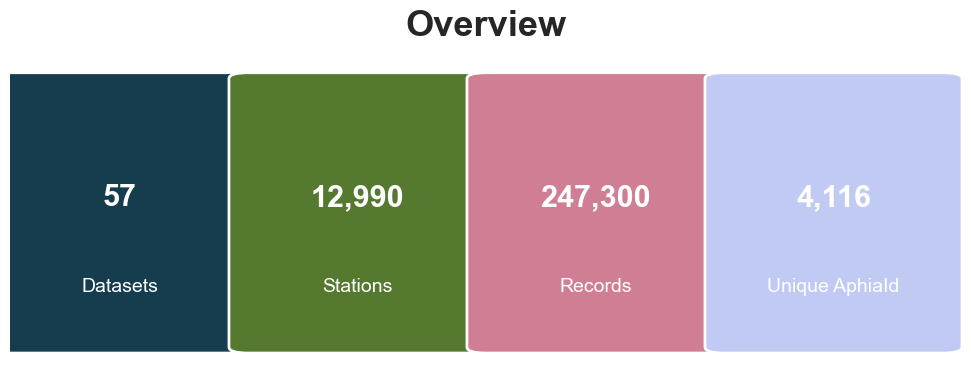

In [39]:
# Summary data
metrics = ['Datasets', 'Stations', 'Records', 'Unique AphiaId']
values = [unique_name_count, unique_device_count, unique_biotaid_count, unique_aphiaid_accepted]
colors = sns.color_palette('cubehelix', len(metrics))

plt.figure(figsize=(10,4))
ax = plt.gca()
ax.axis('off')

# Draw colored boxes with text
for i, (metric, val) in enumerate(zip(metrics, values)):
    x0 = i * 0.25
    rect = patches.FancyBboxPatch((x0, 0.05), 0.23, 0.9,
                                   boxstyle="round,pad=0.02", fc=colors[i], ec='white', lw=2)
    ax.add_patch(rect)
    ax.text(x0 + 0.115, 0.55, '{:,}'.format(val), ha='center', va='center', fontsize=22, color='white', weight='bold')
    ax.text(x0 + 0.115, 0.25, metric, ha='center', va='center', fontsize=14, color='white')

plt.title('Overview', fontsize=26, weight='bold', pad=20)
plt.tight_layout()
plt.savefig("numerical_overview", dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

### Biomass data

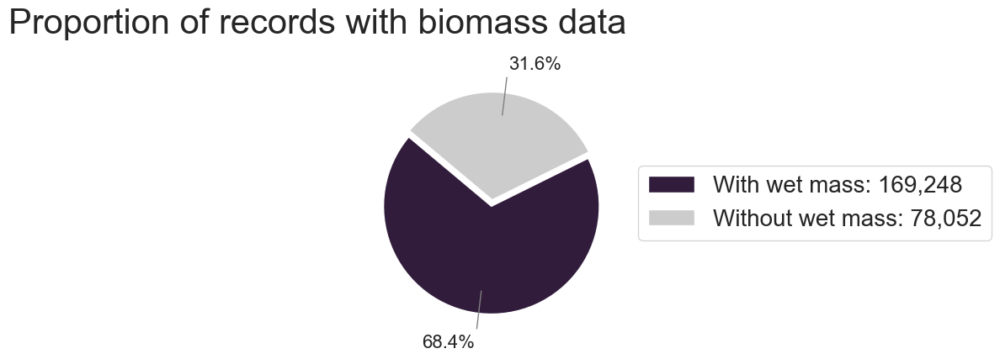

In [40]:
biota_df = pd.read_excel('biota_water.xlsx')

total = len(biota_df)
with_wet = biota_df['SumWet'].notna().sum()
without_wet = total - with_wet

labels = ['With wet mass', 'Without wet mass']
counts_cat = [with_wet, without_wet]
explode = [0.03]*len(counts_cat)

# Capture blue color from previous metrics palette
metrics_palette = sns.cubehelix_palette(start=.5, rot=-.5, n_colors=3)[::-1]
blue_color = metrics_palette[0]  # blue-like color used for Abundance slice previously
# Build new colors list: use blue for With wet mass, light grey for without
colors = [blue_color, '#cccccc']

plt.figure(figsize=(8,8))
wedges, _ = plt.pie(counts_cat, labels=["" for _ in counts_cat], startangle=140,
                    colors=colors, explode=explode,
                    wedgeprops={'linewidth':1, 'edgecolor':'white'})

total_n = sum(counts_cat)
for i, w in enumerate(wedges):
    angle = (w.theta2 + w.theta1)/2
    x = np.cos(np.deg2rad(angle))
    y = np.sin(np.deg2rad(angle))
    ha = 'left' if x>0 else 'right'
    pct = counts_cat[i]/total_n*100
    plt.annotate(f"{pct:.1f}%", xy=(x*0.8, y*0.8), xytext=(x*1.3, y*1.3),
                 ha=ha, va='center',
                 arrowprops=dict(arrowstyle='-', color='gray',
                                 connectionstyle=f"angle,angleA=0,angleB={angle}"))

plt.title('Proportion of records with biomass data', loc='right', pad=30, fontsize=30)
legend_labels = [f"{label}: {val}" for label, val in zip(labels, counts_cat)], 
plt.legend(  
    wedges,  
    [f"{lab}: {val:,}" for lab, val in zip(labels, counts_cat)],  # add commas here  
    loc="center left",  
    bbox_to_anchor=(1, 0.5), 
    fontsize=20
) 
plt.tight_layout()
plt.savefig("wet_mass_pie.png", dpi=150, bbox_inches="tight", facecolor="white") 
plt.show()

Preparing data for visualization in ArcGIS

In [41]:
# Are there DeviceID with partial coverage in the SumWet column? 

# Analyze biota_water.xlsx for DeviceID groups where some but not all BiotaID entries have SumWet values
df = pd.read_excel('biota_water.xlsx', engine='calamine')

# Ensure SumWet numeric and detect non-null
has_sumwet = df.groupby('DeviceID')['SumWet'].apply(lambda x: x.notna())

# Aggregate per DeviceID: count entries, count non-null
agg = df.groupby('DeviceID')['SumWet'].agg(['size', lambda x: x.notna().sum()])
agg.columns = ['total_entries', 'non_null_sumwet']
agg['partial_sumwet'] = (agg['non_null_sumwet'] > 0) & (agg['non_null_sumwet'] < agg['total_entries'])

partial_devices = agg[agg['partial_sumwet']].index.tolist()

print('Number of DeviceID with partial SumWet entries:')
print(len(partial_devices))
print('Example DeviceIDs (up to 10):')
print(partial_devices[:10])

Number of DeviceID with partial SumWet entries:
575
Example DeviceIDs (up to 10):
[7030, 7032, 7035, 7037, 7091, 7092, 7093, 7094, 7095, 7096]


Same check for SubsetID: 

In [42]:
# Check SubsetID groups where some but not all BiotaID rows have SumWet entries
df = pd.read_excel('biota_water.xlsx', engine='calamine')

agg_subset = df.groupby('SubsetID')['SumWet'].agg(['size', lambda x: x.notna().sum()])
agg_subset.columns = ['total_entries', 'non_null_sumwet']
agg_subset['partial_sumwet'] = (agg_subset['non_null_sumwet'] > 0) & (agg_subset['non_null_sumwet'] < agg_subset['total_entries'])

partial_subset = agg_subset[agg_subset['partial_sumwet']]

print('Number of SubsetID with partial SumWet entries:')
print(partial_subset.shape[0])
print('Example SubsetIDs (up to 10):')
print(partial_subset.index.tolist()[:10])

Number of SubsetID with partial SumWet entries:
709
Example SubsetIDs (up to 10):
[7296, 7298, 7301, 7303, 7357, 7358, 7359, 7360, 7361, 7362]


Make list of DeviceID with full or partial biomass coverage: 

In [44]:
# 1. Load the workbook  
df = pd.read_excel('biota_water.xlsx', engine='calamine')  
  
# 2. Aggregate SumWet coverage by DeviceID  
agg = df.groupby('DeviceID')['SumWet'].agg(['size', lambda x: x.notna().sum()])  
agg.columns = ['total_entries', 'non_null']  
  
def classify(row):  
    if row['non_null'] == row['total_entries']:  
        return 'full'  
    elif row['non_null'] > 0:  
        return 'partial'  
    else:  
        return 'none'  
  
agg['Biomass coverage'] = agg.apply(classify, axis=1)  
  
# 3. Keep only full or partial coverage  
coverage_df = agg[agg['Biomass coverage'].isin(['full', 'partial'])].reset_index()[['DeviceID', 'Biomass coverage']]  
  
# 4. Save to CSV  
coverage_df.to_csv('unique_device_biomass.csv', index=False)  
  
print('Done – file saved as unique_device_biomass.csv with', len(coverage_df), 'rows.')  
coverage_df.head()  

Done – file saved as unique_device_biomass.csv with 3675 rows.


,DeviceID,Biomass coverage
0,633,full
1,634,full
2,635,full
3,636,full
4,637,full


Add Biomass coverage column to device_water_mini

In [45]:
# Load device_water_mini
mini_df = pd.read_excel('device_water_mini.xlsx', engine='calamine')

# Merge on DeviceID
merged_df = mini_df.merge(coverage_df, on='DeviceID', how='left')

# Save to new file
output_file = 'device_water_with_biomass.xlsx'
merged_df.to_excel(output_file, index=False)

print('Merged dataframe preview:')
print(merged_df.head())
print('File saved as', output_file)

Merged dataframe preview:
   DeviceID  LatStart  LonStart Biomass coverage
0       633     65.68   -168.30             full
1       634     66.00   -169.62             full
2       635     66.93   -170.99             full
3       636     67.43   -169.64             full
4       637     67.87   -168.32             full
File saved as device_water_with_biomass.xlsx


Visualize in ArcGIS

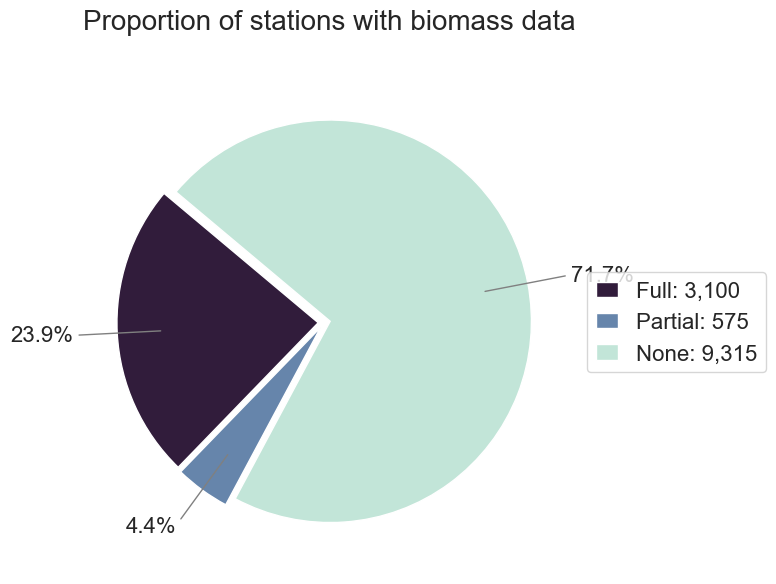

In [46]:
# ── Load data and count categories ──────────────────────────────────────────────  
df = pd.read_excel("device_water_with_biomass.xlsx", engine="calamine")  
counts = (  
    df["Biomass coverage"]  
    .str.lower()  
    .fillna("none")  
    .value_counts()  
    .reindex(["full", "partial", "none"])  
    .fillna(0)  
    .astype(int)  
)  
labels  = counts.index.str.capitalize()  
values  = counts.values  
  
# ── Colour palette, explode offsets ─────────────────────────────────────────────  
base_colors = sns.cubehelix_palette(start=.5, rot=-.5, n_colors=len(values))  
colors      = base_colors[::-1]          # darkest for “none”, lightest for “full”  
explode     = [0.03] * len(values)  
  
# ── Draw pie ────────────────────────────────────────────────────────────────────  
plt.figure(figsize=(8, 8))  
wedges, _ = plt.pie(  
    values,  
    labels=[""] * len(values),            # suppress default labels  
    startangle=140,  
    colors=colors,  
    explode=explode,  
    wedgeprops=dict(linewidth=1, edgecolor="white")  
)  
  
# ── Attach % labels with leader lines ───────────────────────────────────────────  
total_n = values.sum()  
for i, w in enumerate(wedges):  
    mid_ang = (w.theta2 + w.theta1) / 2                # mid-angle in degrees  
    x, y    = np.cos(np.deg2rad(mid_ang)), np.sin(np.deg2rad(mid_ang))  
    ha      = "left" if x > 0 else "right"  
    pct     = values[i] / total_n * 100  
  
    # text slightly outside the wedge, pointer a bit inside  
    plt.annotate(  
        f"{pct:.1f}%",  
        xy=(x * 0.8,  y * 0.8),  
        xytext=(x * 1.25, y * 1.25),  
        ha=ha, va="center",  
        arrowprops=dict(  
            arrowstyle="-",  
            color="gray",  
            connectionstyle=f"angle,angleA=0,angleB={mid_ang}"  
        )  
    )  
  
# ── Title, legend, save, show ──────────────────────────────────────────────────  
plt.title("Proportion of stations with biomass data",  
          loc="right", pad=30, fontsize=20)  
  
plt.legend(  
    wedges,  
    [f"{lab}: {val:,}" for lab, val in zip(labels, values)],  
    loc="center left",  
    bbox_to_anchor=(1, 0.5),  
    handlelength=1  
)  
  
plt.tight_layout()  
plt.savefig("stations_biomass.png", dpi=150, bbox_inches="tight", facecolor="white")  
plt.show()  

Why are the proportions so different for records and stations? 

In [47]:
# ─────────────────────────────────────────────────────────────────────────────  
# 1. RECORD-LEVEL COVERAGE  (every row counts equally)  
# ─────────────────────────────────────────────────────────────────────────────  
biota_df = pd.read_excel("biota_water.xlsx", engine="calamine")  
  
total_records      = len(biota_df)                       # all rows  
records_with_sumwt = biota_df["SumWet"].notna().sum()    # rows where SumWet is present  
prop_records       = records_with_sumwt / total_records  # proportion  
  
print("RECORD-LEVEL COVERAGE")  
print("- Total rows         :", f"{total_records:,}")  
print("- Rows with SumWet   :", f"{records_with_sumwt:,}")  
print("- Proportion covered :", f"{prop_records:.2%}")  
print()  
  
# ─────────────────────────────────────────────────────────────────────────────  
# 2. DEVICE-LEVEL COVERAGE  (collapse rows by DeviceID first)  
# ─────────────────────────────────────────────────────────────────────────────  
device_summary = (  
    biota_df  
    .groupby("DeviceID")["SumWet"]  
    .agg(total_rows = "size",  
         rows_with  = lambda x: x.notna().sum())  
)  
  
# classify each device  
device_summary["coverage"] = device_summary.apply(  
    lambda r: "full"    if r.rows_with == r.total_rows else  
              "partial" if r.rows_with  > 0           else  
              "none",  
    axis=1  
)  
  
# count devices in each category  
device_counts = (  
    device_summary["coverage"]  
    .value_counts()  
    .reindex(["full", "partial", "none"])  
    .fillna(0)  
    .astype(int)  
)  
  
total_devices      = device_counts.sum()  
devices_with_data  = device_counts["full"] + device_counts["partial"]  
prop_devices       = devices_with_data / total_devices  
  
print("DEVICE-LEVEL COVERAGE")  
print(device_counts)                 # table: how many full / partial / none  
print("- Total devices      :", f"{total_devices:,}")  
print("- Devices with data  :", f"{devices_with_data:,}")  
print("- Proportion covered :", f"{prop_devices:.2%}")  
print()  
  
# ─────────────────────────────────────────────────────────────────────────────  
# 3. EXPLANATION  
# ─────────────────────────────────────────────────────────────────────────────  
print("Why are the proportions so different?")  
print("• Record-level coverage is weighted by how many samples each device has.")  
print("  Devices with many rows (and good SumWet data) dominate the  row count.")  
print("• Device-level coverage gives each DeviceID exactly one vote,")  
print("  so a sparsely sampled device with even a single missing value")  
print("  pushes the whole device to 'partial' or 'none', lowering the percentage.")  

RECORD-LEVEL COVERAGE
- Total rows         : 247,300
- Rows with SumWet   : 169,248
- Proportion covered : 68.44%

DEVICE-LEVEL COVERAGE
coverage
full       3100
partial     575
none       9315
Name: count, dtype: int32
- Total devices      : 12,990
- Devices with data  : 3,675
- Proportion covered : 28.29%

Why are the proportions so different?
• Record-level coverage is weighted by how many samples each device has.
  Devices with many rows (and good SumWet data) dominate the  row count.
• Device-level coverage gives each DeviceID exactly one vote,
  so a sparsely sampled device with even a single missing value
  pushes the whole device to 'partial' or 'none', lowering the percentage.


### Count, abundance, presence/absence

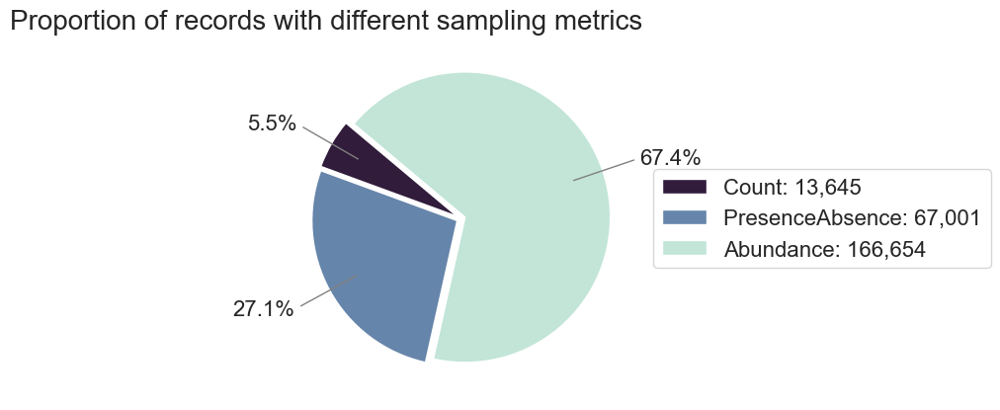

In [48]:
biota_df = pd.read_excel('biota_water.xlsx')

metrics = ['Count','PresenceAbsence','Abundance']
counts = [biota_df[m].notna().sum() for m in metrics]

# Build legend labels with thousand separators
legend_labels = [metric + ': ' + '{:,}'.format(count) for metric, count in zip(metrics, counts)]

base_colors = sns.cubehelix_palette(start=.5, rot=-.5, n_colors=len(metrics))
colors = base_colors[::-1]
explode = [0.03]*len(metrics)

plt.figure(figsize=(8,8))
wedges, _ = plt.pie(counts, labels=["" for _ in metrics], startangle=140,
                    colors=colors, explode=explode,
                    wedgeprops={'linewidth':1, 'edgecolor':'white'})

total_n = sum(counts)
for i, w in enumerate(wedges):
    angle = (w.theta2 + w.theta1)/2
    x = np.cos(np.deg2rad(angle))
    y = np.sin(np.deg2rad(angle))
    ha = 'left' if x>0 else 'right'
    pct = counts[i]/total_n*100
    plt.annotate('{:.1f}%'.format(pct), xy=(x*0.8, y*0.8), xytext=(x*1.3, y*1.3),
                 ha=ha, va='center',
                 arrowprops=dict(arrowstyle='-', color='gray',
                                 connectionstyle='angle,angleA=0,angleB='+str(angle)))

plt.title('Proportion of records with different sampling metrics', loc='right', fontsize=20)
plt.legend(wedges, legend_labels, loc='center left', bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.savefig("samplingmetrics_pie.png", dpi=150, bbox_inches="tight", facecolor="white") 
plt.show()

Do all stations have either PresenceAbsence OR Abundance OR Count or can one station contain a mix between these? 

In [49]:
# Load data
biota_df = pd.read_excel('biota_water.xlsx', engine='calamine')

metrics = ['PresenceAbsence','Count','Abundance']

# For each DeviceID, record whether any non-null present for each metric (bool)
flags = (
    biota_df
    .groupby('DeviceID')[metrics]
    .agg(lambda s: s.notna().any())
)

# Classify rows
def classify_flags(row):
    present = [m for m in metrics if row[m]]
    if len(present) == 1:
        return present[0]  # exclusive metric name
    elif len(present) == 0:
        return 'none'
    else:
        return 'mixed'

flags['metric_type'] = flags.apply(classify_flags, axis=1)

# Reset index for CSV
result_df = flags.reset_index()[['DeviceID','metric_type']]

# Save
outfile = 'device_metric_type.csv'
result_df.to_csv(outfile, index=False)

print('Saved', outfile, 'with', result_df.shape[0], 'rows.')
print(result_df.head())

Saved device_metric_type.csv with 12990 rows.
   DeviceID      metric_type
0       633  PresenceAbsence
1       634  PresenceAbsence
2       635  PresenceAbsence
3       636  PresenceAbsence
4       637  PresenceAbsence


In [50]:
mini_df = pd.read_excel('device_water_mini.xlsx', engine='calamine')
metric_df = pd.read_csv('device_metric_type.csv')
merged = mini_df.merge(metric_df, on='DeviceID', how='left')
merged.to_excel('device_water_with_metric.xlsx', index=False)
print('Merged preview:')
print(merged.head())
print('File saved as device_water_with_metric.xlsx')

Merged preview:
   DeviceID  LatStart  LonStart      metric_type
0       633     65.68   -168.30  PresenceAbsence
1       634     66.00   -169.62  PresenceAbsence
2       635     66.93   -170.99  PresenceAbsence
3       636     67.43   -169.64  PresenceAbsence
4       637     67.87   -168.32  PresenceAbsence
File saved as device_water_with_metric.xlsx


Inspect in ArcGIS

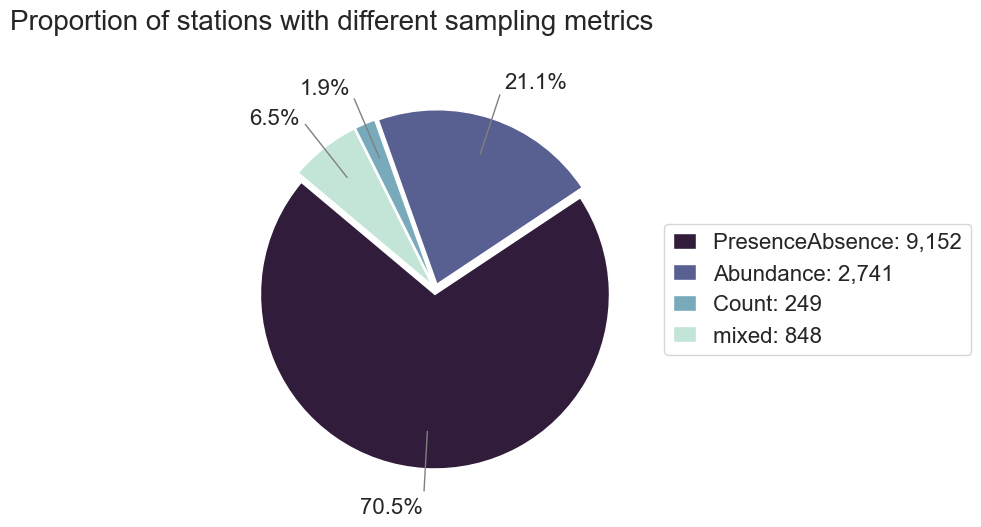

Metric type counts:
metric_type
PresenceAbsence    9152
Abundance          2741
Count               249
mixed               848
Name: count, dtype: int32


In [51]:
# Load metric type classifications
dtypes_df = pd.read_csv('device_metric_type.csv')

# Count categories
counts_series = dtypes_df['metric_type'].value_counts().reindex(['PresenceAbsence','Abundance','Count','mixed']).fillna(0).astype(int)
labels = counts_series.index
values = counts_series.values

# Colour palette and explode
base_colors = sns.cubehelix_palette(start=.5, rot=-.5, n_colors=len(values))
colors = base_colors[::-1]
explode = [0.03]*len(values)

# Plot
plt.figure(figsize=(8,8))
wedges,_ = plt.pie(values, labels=['']*len(values), startangle=140, colors=colors, explode=explode, wedgeprops=dict(linewidth=1, edgecolor='white'))

total_n = values.sum()
for i,w in enumerate(wedges):
    mid = (w.theta2 + w.theta1)/2
    x,y = np.cos(np.deg2rad(mid)), np.sin(np.deg2rad(mid))
    ha = 'left' if x>0 else 'right'
    pct = values[i]/total_n*100
    plt.annotate(f"{pct:.1f}%", xy=(x*0.8,y*0.8), xytext=(x*1.25,y*1.25), ha=ha, va='center',
                 arrowprops=dict(arrowstyle='-', color='gray', connectionstyle='angle,angleA=0,angleB='+str(mid)))

plt.title('Proportion of stations with different sampling metrics', loc='right', pad=30, fontsize=20)
plt.legend(wedges, [lab+': '+format(val, ',') for lab,val in zip(labels,values)], loc='center left', bbox_to_anchor=(1,0.5), handlelength=1)
plt.tight_layout()
plt.savefig('stations_metric.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

print('Metric type counts:')
print(counts_series)

### Taxa richness per station

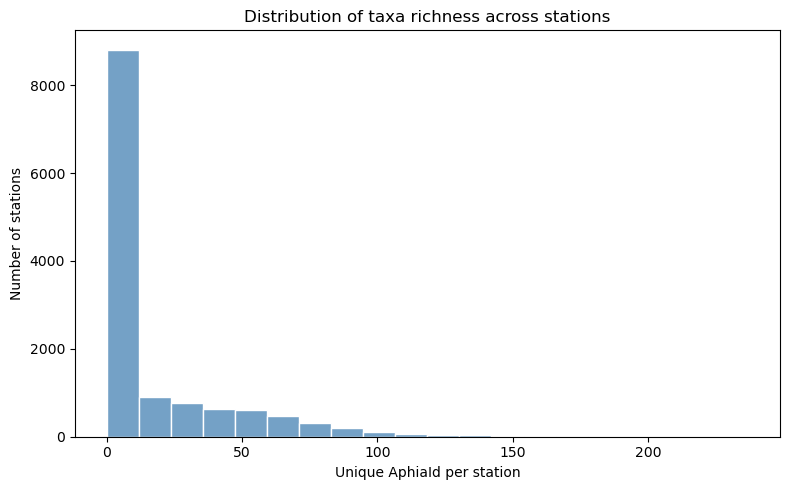

DeviceID
10132    237
10153    232
20871    225
20855    206
20858    206
Name: AphiaId (Accepted), dtype: int64


In [46]:
# Load the mini dataset
mini_df = pd.read_excel('biota_water_mini.xlsx')

# Identify DeviceID and AphiaId (Accepted) columns
possible_device_cols = ['DeviceID', 'deviceid', 'deviceId', 'device_id']
for col in possible_device_cols:
    if col in mini_df.columns:
        device_col = col
        break
else:
    device_col = mini_df.columns[0]

aphia_col = 'AphiaId (Accepted)' if 'AphiaId (Accepted)' in mini_df.columns else mini_df.columns[1]

# Aggregate counts of unique AphiaId per DeviceID
counts_per_device = (mini_df.dropna(subset=[device_col])
                              .groupby(device_col)[aphia_col]
                              .nunique()
                              .sort_values(ascending=False))

# Plot histogram
plt.figure(figsize=(8,5))
sns.histplot(counts_per_device, bins=20, kde=False, color='steelblue', edgecolor='white')
plt.xlabel('Unique AphiaId per station')
plt.ylabel('Number of stations')
plt.title('Distribution of taxa richness across stations')
plt.tight_layout()
plt.savefig("histogram_taxa_stations.png", dpi=150, bbox_inches="tight", facecolor="white") 
plt.show()

# Show quick peek of counts table
a = counts_per_device.head()
print(a)

In [47]:
# Imports and file loading (separate to validate IO quickly)
biota_path = 'biota_water_mini.xlsx'
device_path = 'device_water_mini.xlsx'

# Read specific sheet using a robust engine
biota_df = pd.read_excel(biota_path, sheet_name='Sheet1', engine='calamine')
device_df = pd.read_excel(device_path, sheet_name='Sheet1', engine='calamine')

# Quick preview to verify structure
print(biota_df.head())
print(device_df.head())

   DeviceID  SampleID  SubSampleID  SubsetID  BiotaID  AphiaId (Accepted)  \
0      1000      1001         1001      1266    33334            123815.0   
1     10000     10001        10001     10266    77009            110470.0   
2     10000     10001        10001     10266    77008            110524.0   
3     10001     10002        10002     10267    77010            110478.0   
4     10001     10002        10002     10267    77011            139015.0   

           ScientificName (Accepted)  
0                  Urasterias lincki  
1             Brachydiastylis resima  
2               Eudorella emarginata  
3                   Diastylis glabra  
4  Serripes (Serripes) groenlandicus  
   DeviceID  LatStart  LonStart
0       633     65.68   -168.30
1       634     66.00   -169.62
2       635     66.93   -170.99
3       636     67.43   -169.64
4       637     67.87   -168.32


In [48]:
# Compute unique AphiaId (Accepted) per DeviceID and merge into device_df

# Standardize column names to avoid whitespace issues
biota_df.columns = [c.strip() for c in biota_df.columns]

# Find the AphiaId (Accepted) column robustly
aphia_candidates = [c for c in biota_df.columns if c.lower().startswith('aphiaid')]
aphia_col = aphia_candidates[0]

# Unique count per DeviceID
richness = biota_df.groupby('DeviceID')[aphia_col].nunique(dropna=True).reset_index()
richness = richness.rename(columns={aphia_col: 'unique_aphia_per_device'})

# Merge into device df
device_aug = device_df.merge(richness, on='DeviceID', how='left')

# Fill missing with 0 for devices without biota rows
device_aug['unique_aphia_per_device'] = device_aug['unique_aphia_per_device'].fillna(0).astype(int)

# Preview
print(device_aug.head())

# Save augmented file
out_name = 'device_water_with_taxa.xlsx'
device_aug.to_excel(out_name, index=False)
print(out_name)

   DeviceID  LatStart  LonStart  unique_aphia_per_device
0       633     65.68   -168.30                       29
1       634     66.00   -169.62                       24
2       635     66.93   -170.99                       21
3       636     67.43   -169.64                       17
4       637     67.87   -168.32                       21
device_water_with_taxa.xlsx


## Nr of records per station

In [50]:
biota_df = pd.read_excel('biota_water_mini.xlsx', sheet_name='Sheet1', engine='calamine')
device_df = pd.read_excel('device_water_mini.xlsx', sheet_name='Sheet1', engine='calamine')

# Tidy column names
biota_df.columns = [c.strip() for c in biota_df.columns]
device_df.columns = [c.strip() for c in device_df.columns]

In [51]:
# Count rows in biota per DeviceID and merge into device_df
records_per_device = biota_df.groupby('DeviceID').size().reset_index(name='records_per_device')
device_with_counts = device_df.merge(records_per_device, on='DeviceID', how='left')
device_with_counts['records_per_device'] = device_with_counts['records_per_device'].fillna(0).astype(int)

# Show a quick preview
print(device_with_counts.head())

# Optional: save to a new file
out_name = 'device_water_with_records.xlsx'
device_with_counts.to_excel(out_name, index=False)
print(out_name)

   DeviceID  LatStart  LonStart  records_per_device
0       633     65.68   -168.30                  29
1       634     66.00   -169.62                  24
2       635     66.93   -170.99                  21
3       636     67.43   -169.64                  17
4       637     67.87   -168.32                  21
device_water_with_records.xlsx


# Depth, latitude, time

Add coordinates, date and depth to taxa_per_device

In [53]:
# Load 
taxa_df = pd.read_excel('taxa_per_device.xlsx')  

# Pull coordinate & environmental data from device_water  
cols_needed = ['DeviceID', 'LatStart', 'LonStart', 'DateStart', 'bathy']  
device_df = pd.read_excel('device_water.xlsx', usecols=cols_needed)  
  
# Merge on StationID  
merged_df = taxa_df.merge(device_df, on='DeviceID', how='left')  
  
# Order columns for clarity  
merged_df = merged_df[['DeviceID', 'LatStart', 'LonStart',  
                       'DateStart', 'bathy', 'Unique_AphiaIds']]  
  
# Save to Excel  
merged_df.to_excel('taxa_per_device.xlsx', index=False)  
  
# Quick verification  
print('Saved to taxa_per_device.xlsx')  
print(merged_df.head())  

xlsx  = 'taxa_per_device.xlsx'  
sheets = ['Sheet1']  
  
for sh in sheets:  
    n = len(pd.read_excel(xlsx, sheet_name=sh))  
    print(f'{sh}: {n}')  

Saved to taxa_per_device.xlsx
   DeviceID  LatStart  LonStart   DateStart      bathy  Unique_AphiaIds
0       633     65.68   -168.30  2004-08-09 -47.609608               29
1       634     66.00   -169.62  2004-08-11 -48.926838               24
2       635     66.93   -170.99  2004-08-11 -39.880211               21
3       636     67.43   -169.64  2004-08-11 -49.570526               17
4       637     67.87   -168.32  2004-08-12 -56.681194               21
Sheet1: 12990


Visualize taxa_per_device in ArcGIS

### Depth

Adding bathy column to biota_water file

In [7]:
# Merge bathy into biota on StationID; keep biota rows
device_df = pd.read_excel('device_water.xlsx')  
biota_df = pd.read_excel('biota_water.xlsx')  

merge_df = device_df[['StationID', 'bathy']].drop_duplicates(subset=['StationID'])
biota_merged = pd.merge(biota_df, merge_df, on='StationID', how='left')

print(biota_merged.head())
print(biota_df.shape)
print(biota_merged.shape)
print('Merged bathy into biota_merged on StationID')

   CruiseID  StationID  DeviceID  SampleID  SubSampleID  SubsetID  BiotaID  \
0        96        879      1000      1001         1001      1266    33334   
1      1051       9807     10000     10001        10001     10266    77009   
2      1051       9807     10000     10001        10001     10266    77008   
3      1051       9808     10001     10002        10002     10267    77010   
4      1051       9808     10001     10002        10002     10267    77011   

                        Cruise Station Device  ... PresenceAbsence SumWet  \
0                zin_sp22_1980    5600   5600  ...             1.0    NaN   
1  Hydrographic Expeditionffff     903      1  ...             1.0    NaN   
2  Hydrographic Expeditionffff     903      1  ...             1.0    NaN   
3  Hydrographic Expeditionffff     904      1  ...             1.0    NaN   
4  Hydrographic Expeditionffff     904      1  ...             1.0    NaN   

  SumDry  SumAFDW  Stage SieveFraction SubTotalFactor  Specification

In [8]:
# Basic checks for alignment and missingness
rows_before = len(biota_df)
rows_after = len(biota_merged)
null_bathy_share = biota_merged['bathy'].isna().mean()
unique_station_biota = biota_df['StationID'].nunique()
unique_station_device = device_df['StationID'].nunique()
matched_share = biota_merged['StationID'].isin(device_df['StationID']).mean()

print(rows_before)
print(rows_after)
print(null_bathy_share)
print(unique_station_biota)
print(unique_station_device)
print(matched_share)
print('Validation metrics computed')

247300
247300
0.0
11871
11871
1.0
Validation metrics computed


In [10]:
# Save the merged file and verify by reloading
output_filename = 'biota_water_depth.xlsx'
biota_merged.to_excel(output_filename, index=False)

reloaded = pd.read_excel(output_filename, sheet_name=0, engine='calamine')
print(output_filename)
print(biota_merged.shape)
print(reloaded.shape)
print('Saved file and verified by reload')

biota_water_depth.xlsx
(247300, 32)
(247300, 32)
Saved file and verified by reload


Barplot with records over depth

In [13]:
# Load bathy from Excel and use absolute depths; drop NAs
df_src = pd.read_excel('biota_water_depth.xlsx', engine='calamine')
bathy_abs = df_src['bathy'].dropna().abs()

print(bathy_abs.head())
print('Loaded bathy and computed absolute depths')

0    68.070030
1    66.131844
2    66.131844
3    63.168449
4    63.168449
Name: bathy, dtype: float64
Loaded bathy and computed absolute depths


In [18]:
# Create 0-based 100 m bins and aggregate counts
bin_width = 100
max_abs = int(np.ceil(bathy_abs.max()))
edges_100 = np.arange(0, max_abs + bin_width, bin_width)

labels_100 = [str(i) + ' to ' + str(i + bin_width) + ' m' for i in range(0, max_abs, bin_width)]
binned_100 = pd.cut(bathy_abs, bins=edges_100, right=True, include_lowest=True, labels=labels_100)

counts_100 = binned_100.value_counts(sort=False).reset_index()
counts_100.columns = ['bin_label', 'records']
counts_100['bin_start'] = counts_100['bin_label'].apply(lambda s: int(s.split(' to ')[0]))
counts_100 = counts_100.sort_values('bin_start').reset_index(drop=True)

print(counts_100.head())
print('Prepared 0-based 100 m bins and counts')

      bin_label  records bin_start
0    0 to 100 m   115129         0
1  100 to 200 m    28883       100
2  200 to 300 m    40722       200
3  300 to 400 m    22161       300
4  400 to 500 m     7657       400
Prepared 0-based 100 m bins and counts


<module 'matplotlib.pyplot' from 'C:\\ProgramData\\anaconda3\\Lib\\site-packages\\matplotlib\\pyplot.py'>

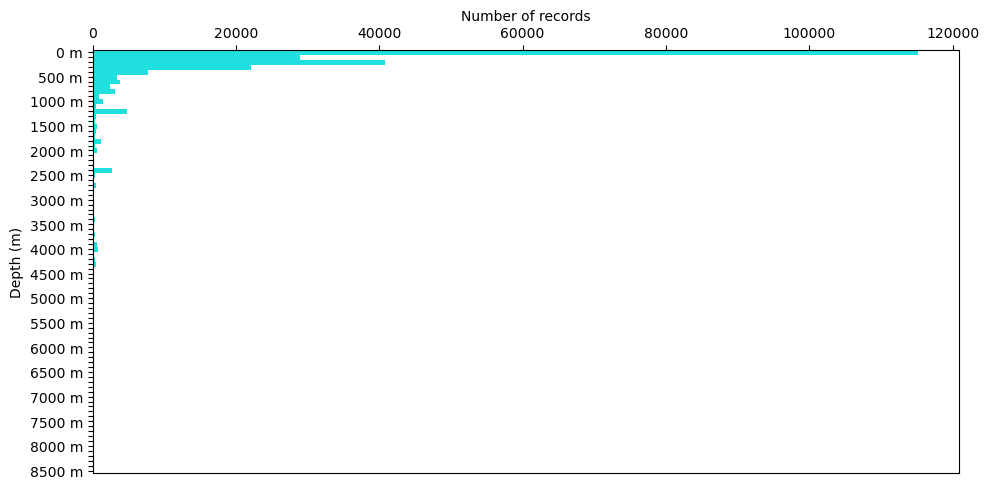

In [30]:
# Plot with compact styling: thinner bars, no gaps, shorter figure
# Y labels show only bin start every 500 m. X-axis at top.
ytick_labels = []
for _, row in counts_100.iterrows():
    start = row['bin_start']
    if start % 500 == 0:
        ytick_labels.append(str(start) + ' m')
    else:
        ytick_labels.append('')
plt.figure(figsize=(10, 5))  
ax = sns.barplot(
    data=counts_100,
    y='bin_label',
    x='records',
    color='aqua',
    orient='h',
    errorbar=None  
)
# Remove gaps by removing bar edges and adjusting bar height
bar_width = 1  # Set bar width to 1 to remove gaps
for patch in ax.patches:
    patch.set_linewidth(0) 
    patch.set_height(bar_width)  
# Set y-ticks and labels explicitly
ax.set_yticks(range(len(ytick_labels)))  # Set tick positions
ax.set_yticklabels(ytick_labels)  # Set tick labels
ax.xaxis.set_label_position('top')
ax.xaxis.tick_top()
plt.xlabel('Number of records')
plt.ylabel('Depth (m)')
plt.tight_layout()
png_file = 'records_by_depth.png'
plt

C:\Users\hamod4691\AppData\Local\Temp\ipykernel_12128\1872248339.py:31: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  ax = sns.barplot(data=df_counts, y='bin_label', x='records_sqrt', color='#4C78A8', orient='h', ci=None)
C:\Users\hamod4691\AppData\Local\Temp\ipykernel_12128\1872248339.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ytick_labels)


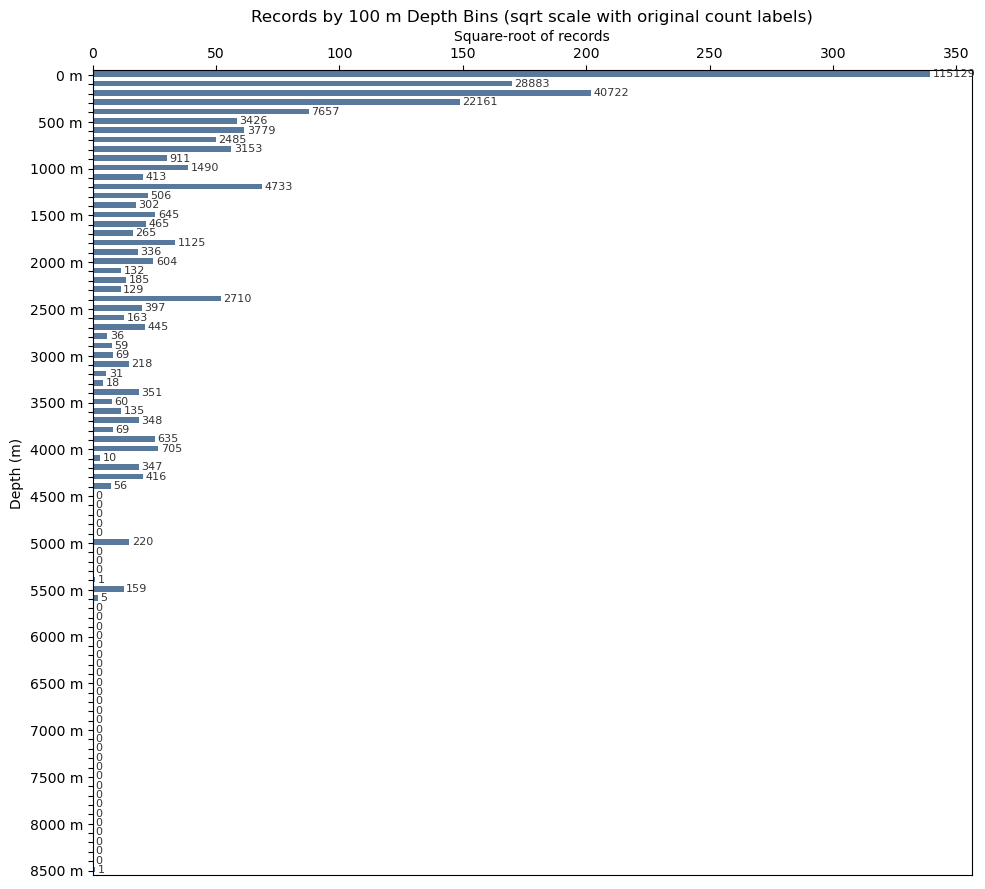

In [29]:
# Load or reuse counts_100, compute sqrt transform, and plot with annotations; save PNG/CSV
# If counts_100 doesn't exist in memory, it will be built from device_water.xlsx.

# Prepare counts_100 if not already in memory
try:
    df_counts = counts_100.copy()
except NameError:
    df_src = pd.read_excel('device_water.xlsx', engine='calamine')
    bathy_abs = pd.to_numeric(df_src['bathy'], errors='coerce').dropna().abs()
    bin_width = 100
    max_abs = int(np.ceil(bathy_abs.max()))
    edges = np.arange(0, max_abs + bin_width, bin_width)
    labels = [str(i) + ' to ' + str(i + bin_width) + ' m' for i in edges[:-1]]
    binned = pd.cut(bathy_abs, bins=edges, right=True, include_lowest=True, labels=labels)
    df_counts = binned.value_counts(sort=False).reset_index()
    df_counts.columns = ['bin_label', 'records']
    df_counts['bin_start'] = df_counts['bin_label'].apply(lambda s: int(s.split(' to ')[0]))
    df_counts = df_counts.sort_values('bin_start').reset_index(drop=True)

# Square-root transform
df_counts['records_sqrt'] = np.sqrt(df_counts['records'].clip(lower=0))

# Y labels every 500 m
ytick_labels = []
for _, row in df_counts.iterrows():
    v = row['bin_start']
    ytick_labels.append(str(v) + ' m' if v % 500 == 0 else '')

# Plot
plt.figure(figsize=(10, 9))
ax = sns.barplot(data=df_counts, y='bin_label', x='records_sqrt', color='#4C78A8', orient='h', ci=None)
for p in ax.patches:
    p.set_linewidth(0)
    p.set_height(0.6)

# Annotate original counts at end of each bar
for i, p in enumerate(ax.patches):
    width = p.get_width()
    y = p.get_y() + p.get_height() / 2.0
    val = int(df_counts.iloc[i]['records'])
    ax.text(width + 1.0, y, str(val), va='center', ha='left', fontsize=8, color='#333333')

ax.set_yticklabels(ytick_labels)
ax.xaxis.set_label_position('top')
ax.xaxis.tick_top()
plt.xlabel('Square-root of records')
plt.ylabel('Depth (m)')
plt.title('Records by 100 m Depth Bins (sqrt scale with original count labels)')
plt.tight_layout()

png_file = 'records_by_depth_bins_100m_sqrt_annotated.png'
plt.savefig(png_file, dpi=300)
plt.show()

Histogram of DeviceID over depth

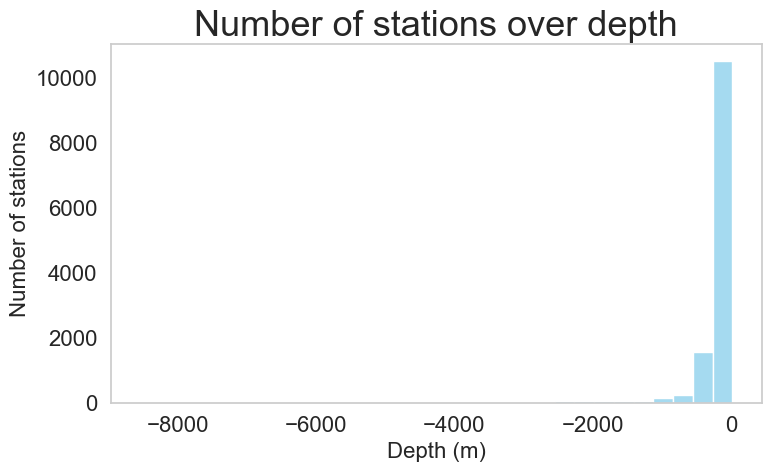

count    12990.000000
mean      -225.584489
std        497.743560
min      -8541.000000
25%       -221.502460
50%        -79.000000
75%        -38.997196
max         20.000000
Name: bathy, dtype: float64


In [54]:
# Load the spreadsheet 
water_df = pd.read_excel('device_water.xlsx')  
  
# Plot: 30 bins gives ~2–4 m resolution across common bathy ranges  
plt.figure(figsize=(8, 5))  
sns.histplot(water_df['bathy'],  
             bins=30,  
             color='skyblue',  
             edgecolor='white')  
plt.title('Number of stations over depth')  
plt.xlabel('Depth (m)')  
plt.ylabel('Number of stations')  
plt.grid(False)  
plt.tight_layout()  
plt.savefig("stations_depth.png", dpi=150, bbox_inches="tight", facecolor="white") 
plt.show()  

# Show a quick summary of the bathy column  
print(water_df['bathy'].describe())  

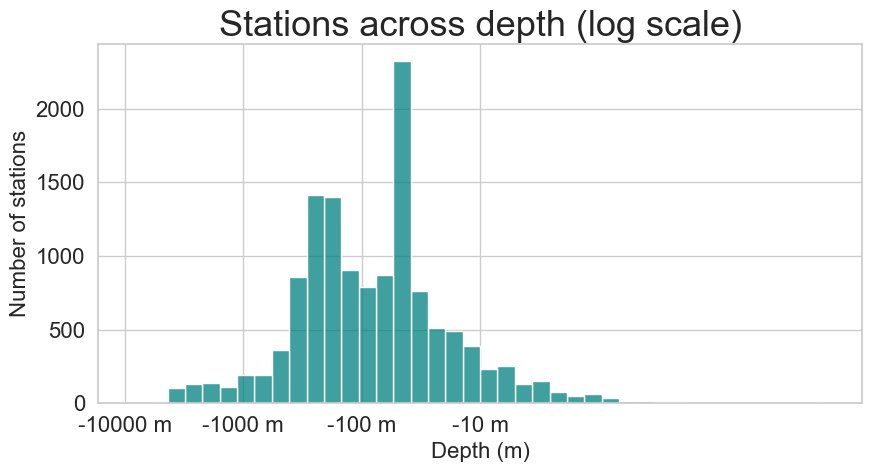

In [55]:
# Load data
df = pd.read_excel('device_water.xlsx')

bathy_col = [c for c in ['bathy'] if c in df.columns][0]

# Absolute depth and log10 transform
abs_depth = df[bathy_col].dropna().abs()
log_depth = np.log10(abs_depth[abs_depth>0])

plt.figure(figsize=(9,5))
sns.histplot(log_depth, bins=40, color='teal', edgecolor='white')
plt.gca().invert_xaxis()  # reverse so deepest (largest log) on left

# custom ticks
xticks = [1,2,3,4]
plt.xticks(xticks, ['-'+str(int(10**x))+' m' for x in xticks])
plt.xlabel('Depth (m)')
plt.ylabel('Number of stations')
plt.title('Stations across depth (log scale)')
plt.savefig("stations_depth_log.png", dpi=150, bbox_inches="tight", facecolor="white") 
plt.tight_layout()
plt.show()

C:\Users\hamod4691\AppData\Local\Temp\ipykernel_13256\3849948713.py:26: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  stations_per_depth.groupby('DepthBinLarge', dropna=False)['StationID']


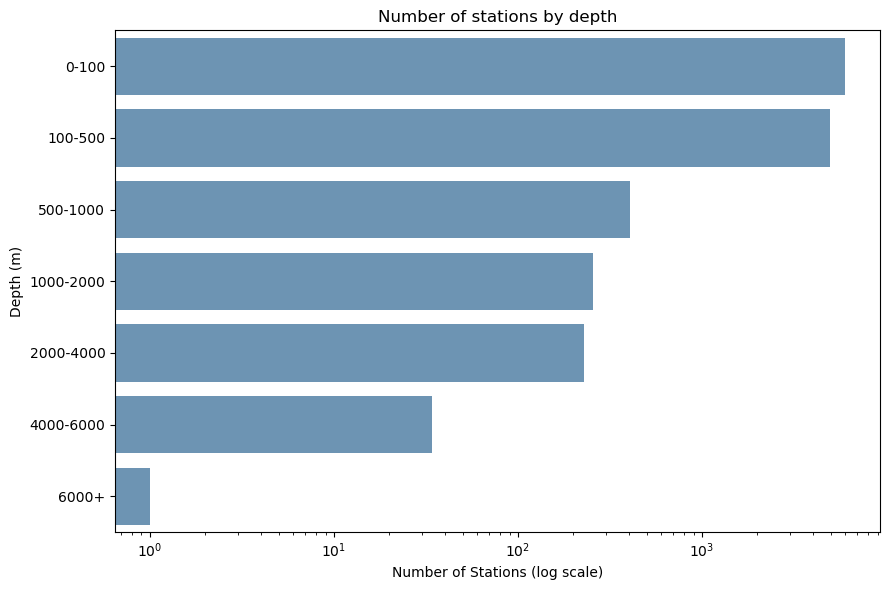

<Figure size 640x480 with 0 Axes>

In [4]:
# WRONG DEPTH COLUMN
# Load
device_df = pd.read_excel('device_water.xlsx')

# Convert bathy (negative depths) to positive meters
device_df['Depth_m'] = device_df['bathy'].abs()

# Collapse to one depth per station (median is robust)
stations_per_depth = (
    device_df.groupby('StationID')['Depth_m']
    .median()
    .reset_index()
)

# Define fewer, larger bins
bin_edges = [0, 100, 500, 1000, 2000, 4000, 6000, np.inf]
bin_labels = ['0-100','100-500','500-1000','1000-2000','2000-4000','4000-6000','6000+']

stations_per_depth['DepthBinLarge'] = pd.cut(
    stations_per_depth['Depth_m'], bins=bin_edges,
    labels=bin_labels, include_lowest=True, right=False
)

# Count unique stations per bin
large_summary_dev = (
    stations_per_depth.groupby('DepthBinLarge', dropna=False)['StationID']
    .nunique()
    .reset_index()
    .rename(columns={'StationID':'Number_of_Stations'})
)

# Plot: horizontal bars, shallowest at top, log x-axis
plt.figure(figsize=(9, 6))
y_order = ['0-100','100-500','500-1000','1000-2000','2000-4000','4000-6000','6000+']
ax = sns.barplot(
    data=large_summary_dev,
    y='DepthBinLarge',
    x='Number_of_Stations',
    order=y_order,
    color='steelblue',
    alpha=0.85
)
ax.set_xscale('log')
ax.set_xlabel('Number of Stations (log scale)')
ax.set_ylabel('Depth (m)')
ax.set_title('Number of stations by depth')
plt.tight_layout()
plt.show()

# Save outputs
csv_path = 'device_water_stations_by_depth.csv'
png_path = 'device_water_stations_by_depth.png'
large_summary_dev.to_csv(csv_path, index=False)
plt.gcf().savefig(png_path, dpi=200, bbox_inches='tight')

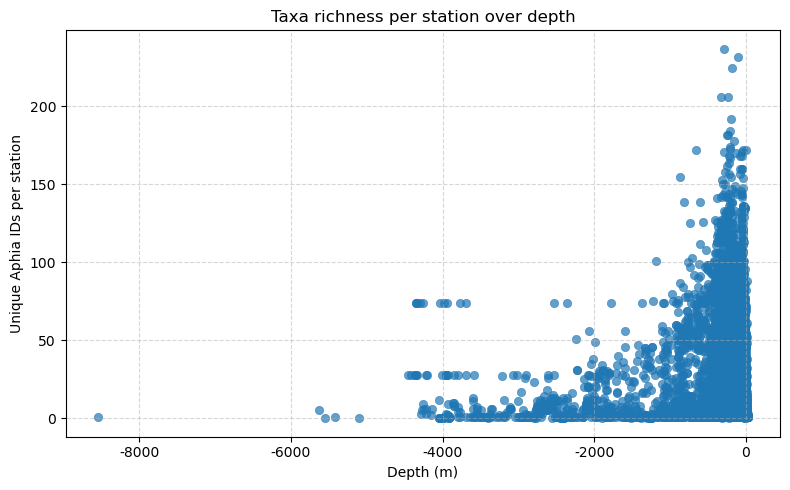

In [48]:
# Scatter plot Unique_AphiaIds vs bathy

# Load enriched dataset 
enriched_df = pd.read_excel('taxa_per_device.xlsx')

plt.figure(figsize=(8,5))
sns.scatterplot(data=enriched_df, x='bathy', y='Unique_AphiaIds', alpha=0.7, edgecolor=None)
plt.title('Taxa richness per station over depth')
plt.xlabel('Depth (m)')
plt.ylabel('Unique Aphia IDs per station')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("taxa_depth.png", dpi=150, bbox_inches="tight", facecolor="white") 
plt.show()

Histogram of unique AphiaId over depth

### Latitude

Histogram of stations over latitude

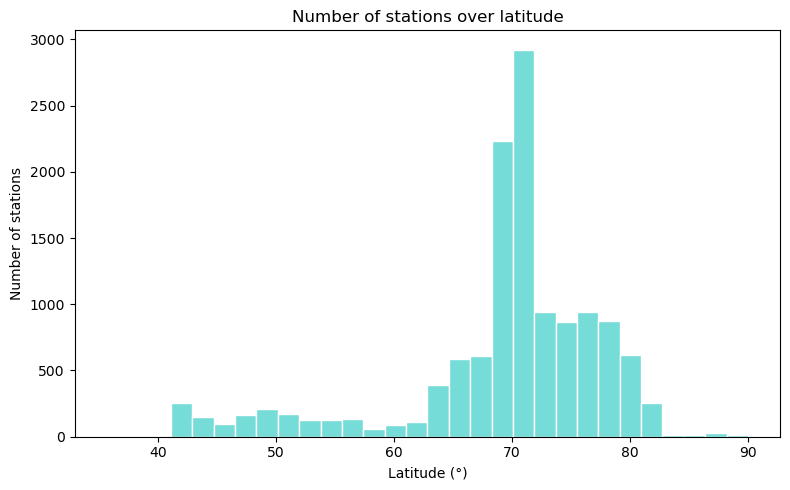

In [49]:
# Histogram of latitude (LatStart) in stations_water.xlsx
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
lat_df = pd.read_excel('device_water.xlsx')

# Plot histogram
plt.figure(figsize=(8,5))
sns.histplot(lat_df['LatStart'], bins=30, color='mediumturquoise', edgecolor='white')
plt.title('Number of stations over latitude')
plt.xlabel('Latitude (°)')
plt.ylabel('Number of stations')
plt.grid(False)
plt.tight_layout()
plt.savefig("stations_latitude.png", dpi=150, bbox_inches="tight", facecolor="white") 
plt.show()

Scatterplot of unique AphiaId over latitude

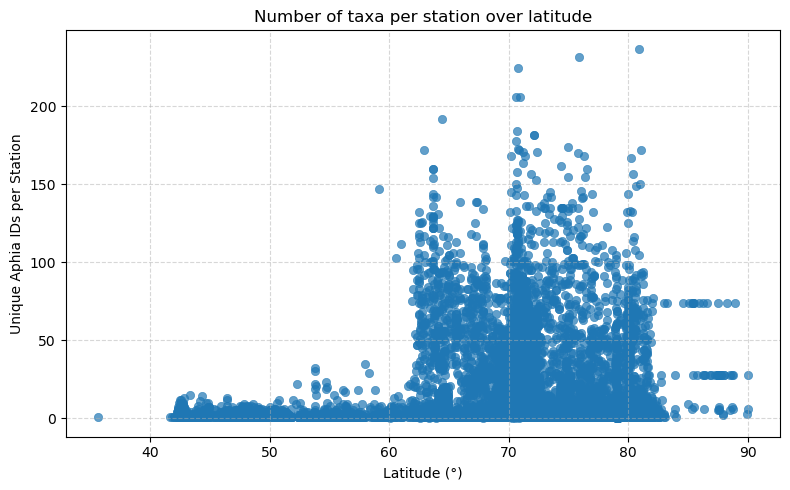

In [50]:
# Scatter plot Unique_AphiaIds vs LatStart

# Load enriched dataset 
enriched_df = pd.read_excel('taxa_per_device.xlsx')

plt.figure(figsize=(8,5))
sns.scatterplot(data=enriched_df, x='LatStart', y='Unique_AphiaIds', alpha=0.7, edgecolor=None)
plt.title('Number of taxa per station over latitude')
plt.xlabel('Latitude (°)')
plt.ylabel('Unique Aphia IDs per Station')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("taxa_latitude.png", dpi=150, bbox_inches="tight", facecolor="white") 
plt.show()

#### Checking strange patterns in Taxa richness per station vs latitude plot

Many stations seem to have AphiaID counts of 28, 72 or 74. Looking into this below.  

What you’ll see after running Cell 1

A compact DataFrame telling you, for each of the three list sizes:  
How many distinct species-lists exist (“Distinct Taxa Sets”).  
The largest number of devices that share any single list (“Max DeviceIDs Sharing One List”).  
A histogram (in dict form) that says, e.g., {1: 68, 29: 1} meaning 68 unique lists occur only once and one list is reused by 29 devices.  

In [51]:
xlsx  = 'original.xlsx'           
biota = pd.read_excel(xlsx, sheet_name='Biota')  
biota.columns = [c.strip() for c in biota.columns]  
  
# Build a frozenset of species names for every DeviceID  
taxa_by_dev = (  
    biota.groupby('DeviceID')['AphiaId (Accepted)']  
         .apply(lambda names: frozenset(names))  
)  
size_by_dev = taxa_by_dev.apply(len)  
  
# Helper to summarise one target size  
def summarise(target_size):  
    subset = taxa_by_dev[size_by_dev == target_size]  
    counter = Counter(subset.values)          # identical taxa_set ➜ count of DeviceIDs  
    if not counter:  
        return dict(unique_lists = 0, most_shared = 0, freq_table = {})  
    freqs = Counter(counter.values())         # how many identical-list groups of size k  
    return dict(unique_lists = len(counter),  
                most_shared  = max(counter.values()),  
                freq_table   = dict(freqs))  
  
summary = {n: summarise(n) for n in (28, 72, 74)}  
  
# Show a neat summary table  
summary_df = (pd.DataFrame(summary).T  
                .rename_axis('Taxa_Count')  
                .rename(columns={  
                    'unique_lists':'Distinct Taxa Sets',  
                    'most_shared':'Max DeviceIDs Sharing One List',  
                    'freq_table':'Histogram of (Group-size:HowMany)'  
                }))  
  
display(summary_df)  

,Distinct Taxa Sets,Max DeviceIDs Sharing One List,Histogram of (Group-size:HowMany)
Taxa_Count,,,
28,68,30,"{1: 67, 30: 1}"
72,30,3,"{1: 23, 3: 7}"
74,23,3,"{1: 20, 3: 3}"


Display the species composition of the one 28-taxa list that all 30 DeviceID share: 

In [52]:
xlsx = 'original.xlsx'
biota = pd.read_excel(xlsx, sheet_name='Biota')  
biota.columns = [c.strip() for c in biota.columns]  
  
# 1) Build a frozenset of accepted AphiaIds for every DeviceID  
taxa_by_dev = (  
    biota.groupby('DeviceID')['AphiaId (Accepted)']  
         .apply(lambda ids: frozenset(ids.dropna()))  
)  
sizes = taxa_by_dev.apply(len)  
  
# 2) Focus on devices with exactly 28 taxa  
subset_28 = taxa_by_dev[sizes == 28]  
counter_28 = Counter(subset_28.values)     # identical taxa-set ➜ count of DeviceIDs  
  
# 3) Extract the 28-taxa set reused by 30 devices  
shared_set = next(tset for tset, c in counter_28.items() if c == 30)  
  
# 4) Translate AphiaIds back to accepted scientific names  
species_table = (  
    biota[['AphiaId (Accepted)', 'ScientificName (Accepted)']]  
      .drop_duplicates()  
      .set_index('AphiaId (Accepted)')  
      .loc[list(shared_set)]  
      .reset_index()  
      .rename(columns={'AphiaId (Accepted)': 'AphiaId',  
                       'ScientificName (Accepted)': 'ScientificName'})  
      .sort_values('ScientificName')  
      .reset_index(drop=True)  
)  
  
# 5) List the 30 DeviceIDs that share this taxa set  
devices_shared = [did for did, tset in subset_28.items() if tset == shared_set]  
  
# 6) Show results  
display(species_table)  
print('DeviceIDs sharing this list (n =', len(devices_shared), '):')  
print(devices_shared)  

,AphiaId,ScientificName
0,129240.0,Aphelochaeta
1,135249.0,Atorella
2,117420.0,Candelabrum phrygium
3,110481.0,Diastylis laevis
4,124726.0,Elpidia glacialis
5,146950.0,Galathowenia oculata
6,254643.0,Geodia phlegraei
7,136021.0,Golfingia
8,101447.0,Haploops
9,325818.0,Hemipodia


DeviceIDs sharing this list (n = 30 ):
[7091, 7092, 7093, 7094, 7095, 7098, 7099, 7100, 7101, 7102, 7103, 7104, 7105, 7106, 7107, 7108, 7109, 7110, 7118, 7119, 7120, 7121, 7122, 7123, 7124, 7125, 7126, 7127, 7128, 7129]


Linking the taxa counts of 28, 72 and 74 to project names: 

In [53]:
# 1. Load sheets from original.xlsx  
file_path = 'original.xlsx'             
biota   = pd.read_excel(file_path, sheet_name='Biota')  
subset  = pd.read_excel(file_path, sheet_name='Subset')  
  
# 2. Clean column names (trim stray spaces)  
biota.columns  = [c.strip() for c in biota.columns]  
subset.columns = [c.strip() for c in subset.columns]  
  
# 3. Taxon count per SubsetID (using ScientificName)  
taxa_counts = (  
    biota.groupby('SubsetID')['ScientificName']  
         .nunique()  
         .reset_index(name='TaxaCount')  
)  
  
# 4. Keep only SubsetIDs with 28, 72, or 74 taxa  
target_counts = [28, 72, 74]  
filtered = taxa_counts[taxa_counts['TaxaCount'].isin(target_counts)]  
  
# 5. Bring in Project names from the Subset sheet  
merged = filtered.merge(  
    subset[['SubsetID', 'Project']],  
    on='SubsetID',  
    how='left'  
)  
  
# 6. Summary table: how many SubsetIDs per Project × TaxaCount  
summary = (  
    merged.groupby(['Project', 'TaxaCount'])  
          .size()  
          .reset_index(name='NumSubsetIDs')  
          .sort_values(['Project', 'TaxaCount'])  
          .reset_index(drop=True)  
)  
  
# 7. Display results  
print('First few matching SubsetIDs:')  
display(merged.head())  
  
print('\nProject • TaxaCount • NumSubsetIDs')  
display(summary)  

First few matching SubsetIDs:


,SubsetID,TaxaCount,Project
0,981,28,Polychaeta Fram Strait ArcOD Schnack
1,2791,28,Benthos ArcOD Sirenko (c)
2,7257,28,Benthos Beaufort Sea 2010 Archambault
3,7259,28,Benthos Beaufort Sea 2010 Archambault
4,7263,28,Benthos Beaufort Sea 2010 Archambault



Project • TaxaCount • NumSubsetIDs


,Project,TaxaCount,NumSubsetIDs
0,AMBON 2015,74,2
1,AMBON 2017,28,3
2,ANIMIDA III Benthos-Fish,28,2
3,BLE-LTER 2024,28,1
4,BOEM 2008,74,1
5,Benthos ArcOD Sirenko (b),28,3
6,Benthos ArcOD Sirenko (b),72,1
7,Benthos ArcOD Sirenko (c),28,1
8,Benthos Barents and Pechora Seas Renaud,28,1
9,Benthos Barents and Pechora Seas Renaud,72,2


Which projects have been involved in multiple sampling of the exact same 28 taxa? 

In [54]:
# Load data
biota = pd.read_excel('original.xlsx', sheet_name='Biota', engine='calamine')
subset = pd.read_excel('original.xlsx', sheet_name='Subset', engine='calamine')
biota.columns = [c.strip() for c in biota.columns]
subset.columns = [c.strip() for c in subset.columns]

# Build taxa set per SubsetID (AphiaId Accepted)
sets_by_subset = biota.groupby('SubsetID')['AphiaId (Accepted)'].apply(lambda x: frozenset(x.dropna()))
richness = sets_by_subset.apply(len)

# Consider only 28-taxa subsets
a28 = sets_by_subset[richness == 28]

# Count identical sets
counter = Counter(a28.values)

# Map taxa set -> list of subsetIDs
set_to_sids = defaultdict(list)
for sid, tset in a28.items():
    set_to_sids[tset].append(sid)

records = []
for tset, sids in set_to_sids.items():
    if len(sids) > 1:  # multiple samplings of exact same set
        projs = subset.loc[subset['SubsetID'].isin(sids), 'Project'].unique()
        records.append({
            'TaxaSetHash': hash(tset),
            'NumSubsetIDs': len(sids),
            'Projects': '; '.join(sorted(projs))
        })

result_df = pd.DataFrame(records).sort_values('NumSubsetIDs', ascending=False).reset_index(drop=True)

print(result_df)

          TaxaSetHash  NumSubsetIDs                                Projects
0 -279698175716658756            30  Benthos European Arctic ArcOD Kroencke


Has the project Benthos Chukchi Sea Blanchard looked at the exact same 28 respectively 72 taxa in 19 respectively 22 of their subsets?

In [58]:
# 1. Load the three spreadsheets once  
subs      = pd.read_excel('subsets_water.xlsx')          # subset metadata  
taxa_dev  = pd.read_excel('taxa_per_device.xlsx')        # unique AphiaIds / device  
biota     = pd.read_excel('biota_water.xlsx')            # raw species records  
print('Files loaded:', subs.shape, taxa_dev.shape, biota.shape)  
  
# 2. Filter to the Blanchard project  
proj = subs.loc[subs['Project'] == 'Benthos Chukchi Sea Blanchard'].copy()  
  
# 3. Add device-level counts, aggregate to SubsetID  
proj = proj.merge(taxa_dev[['DeviceID', 'Unique_AphiaIds']],  
                  on='DeviceID', how='left')  
subset_tot = (proj.groupby('SubsetID', as_index=False)['Unique_AphiaIds']  
              .sum()  
              .rename(columns={'Unique_AphiaIds': 'TaxaCount'}))  
  
# 4. Grab the 28- and 72-taxa SubsetIDs  
subset28 = subset_tot.loc[subset_tot['TaxaCount'] == 28, 'SubsetID'].tolist()  
subset72 = subset_tot.loc[subset_tot['TaxaCount'] == 72, 'SubsetID'].tolist()  
print('# subsets with 28 taxa =', len(subset28))  
print('# subsets with 72 taxa =', len(subset72))  
  
# 5. Helper to build AphiaId sets  
def aphia_sets(ids):  
    return (biota.loc[biota['SubsetID'].isin(ids)]  
            .groupby('SubsetID')['AphiaId (Accepted)']  
            .apply(lambda s: set(s.dropna())))  
  
sets28, sets72 = aphia_sets(subset28), aphia_sets(subset72)  
  
# 6. Quick “identical?” check + diff table for the 28-taxa group  
ref28   = sets28.iloc[0]  
diff28  = (sets28.apply(lambda s: len(s.symmetric_difference(ref28)))  
                  .reset_index()  
                  .rename(columns={'AphiaId (Accepted)': 'DiffSize'}))  
print('\n28-taxa – difference size vs reference (top rows)')  
print(diff28.sort_values('DiffSize', ascending=False).head())   # show a glimpse  

# 6. Quick “identical?” check + diff table for the 72-taxa group  
ref72   = sets72.iloc[0]  
diff72  = (sets72.apply(lambda s: len(s.symmetric_difference(ref72)))  
                  .reset_index()  
                  .rename(columns={'AphiaId (Accepted)': 'DiffSize'}))  
print('\n72-taxa – difference size vs reference (top rows)')  
print(diff72.sort_values('DiffSize', ascending=False).head())   # show a glimpse  

Files loaded: (14283, 25) (12990, 6) (247300, 31)
# subsets with 28 taxa = 19
# subsets with 72 taxa = 22

28-taxa – difference size vs reference (top rows)
    SubsetID  DiffSize
10     11546        56
17     11684        56
5      11359        56
14     11597        56
9      11545        54

72-taxa – difference size vs reference (top rows)
    SubsetID  DiffSize
21     11906        88
9      10916        84
10     10917        84
11     10918        84
13     10928        82


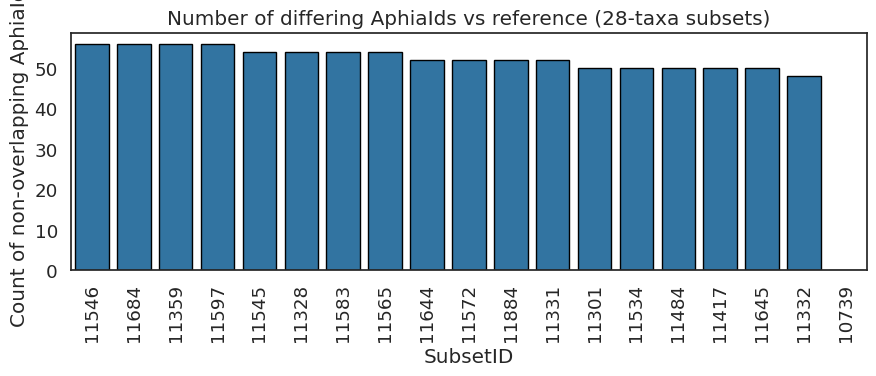

In [127]:
# 7. Plot the differences (28-taxa subsets)
mpl.rcParams['font.family']       = 'DejaVu Sans'  
mpl.rcParams['axes.unicode_minus'] = False  
plot_df = diff28.sort_values('DiffSize', ascending=False)  
plt.figure(figsize=(9, 4))  
sns.barplot(data=plot_df, x='SubsetID', y='DiffSize',  
            color='#1f77b4', edgecolor='black', 
            order  = plot_df['SubsetID'] 
           )  
plt.xticks(rotation=90)  
plt.title('Number of differing AphiaIds vs reference (28-taxa subsets)')  
plt.ylabel('Count of non-overlapping AphiaIds')  
plt.tight_layout()  
plt.savefig("diff_vs_reference_28.png", dpi=150, bbox_inches="tight", facecolor="white") 
plt.show()  

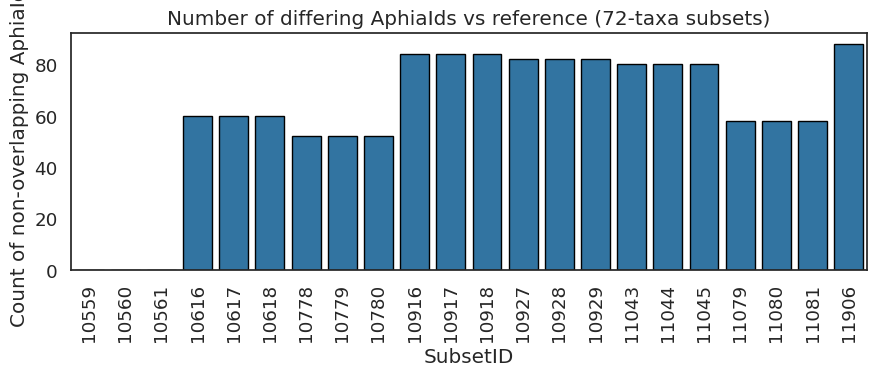

In [124]:
# 8. Plot the differences (72-taxa subsets)  
mpl.rcParams['font.family']       = 'DejaVu Sans'  
mpl.rcParams['axes.unicode_minus'] = False  
plot_df = diff72.sort_values('DiffSize', ascending=False)  
plt.figure(figsize=(9, 4))  
sns.barplot(data=plot_df, x='SubsetID', y='DiffSize',  
            color='#1f77b4', edgecolor='black')  
plt.xticks(rotation=90)  
plt.title('Number of differing AphiaIds vs reference (72-taxa subsets)')  
plt.ylabel('Count of non-overlapping AphiaIds')  
plt.tight_layout()  
plt.savefig("diff_vs_reference_72.png", dpi=150, bbox_inches="tight", facecolor="white") 
plt.show()  

Based on the plots, it seems as though there has been som repeated sampling of the same sets of species within these projects. 

### Time

Histogram of stations over year

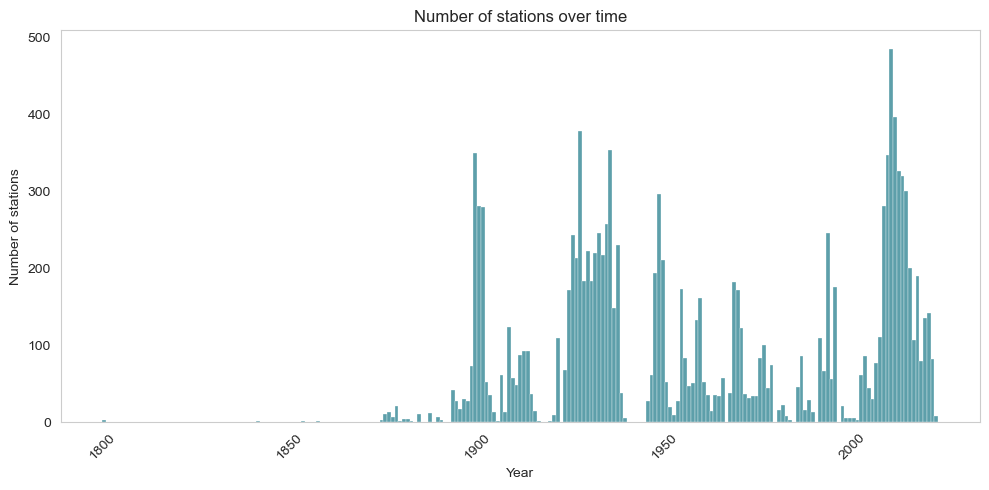

In [61]:
# Load data
device_df = pd.read_excel('device_water.xlsx')

# Convert DateStart to datetime
device_df['DateStart'] = pd.to_datetime(device_df['DateStart'], errors='coerce')

# Drop rows with invalid dates
df_clean = device_df.dropna(subset=['DateStart']).copy()

# Extract year into a new column
df_clean['Year'] = df_clean['DateStart'].dt.year

# Plot histogram
sns.set_style('whitegrid')
plt.figure(figsize=(10,5))

sns.histplot(
    df_clean['Year'],
    bins=range(df_clean['Year'].min(), df_clean['Year'].max()+2),
    color=sns.color_palette('viridis')[2],
    edgecolor=None
)

plt.title('Number of stations over time')
plt.xlabel('Year')
plt.ylabel('Number of stations')
plt.xticks(rotation=45)
plt.grid(False)
plt.tight_layout()
plt.savefig("stations_time.png", dpi=150, bbox_inches="tight", facecolor="white") 
plt.show()

Rows with invalid dates: 

In [62]:
# Count invalid DateStart entries
stations_df2 = pd.read_excel('device_water.xlsx')
stations_df2['DateStart_parsed'] = pd.to_datetime(stations_df2['DateStart'], errors='coerce')

invalid_mask = stations_df2['DateStart_parsed'].isna()
invalid_count = invalid_mask.sum()

print('Invalid DateStart count:', invalid_count)

# Show a few invalid rows if any
if invalid_count > 0:
    print(stations_df2.loc[invalid_mask, ['StationID', 'DateStart']].head())

Invalid DateStart count: 16
       StationID DateStart
12853      17016       NaN
12854      17017       NaN
12855      17018       NaN
12856      17019       NaN
12857      17020       NaN


Histogram of unique AphiaId over year

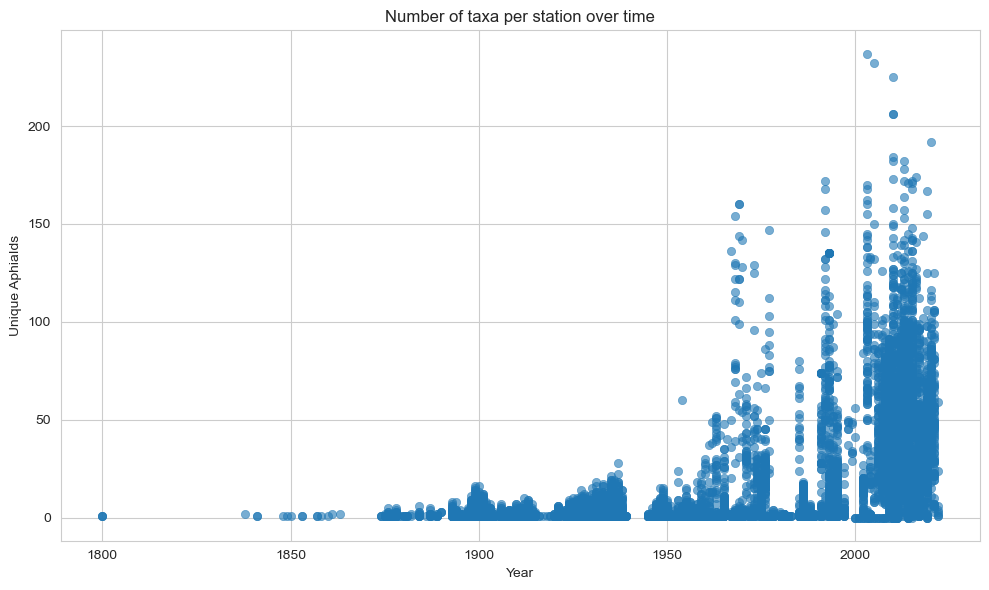

Year range: 1800.0 - 2022.0
Rows with unusual years: 687
     DeviceID    Year   DateStart
160       797  1882.0  1882-08-13
162       799  1881.0  1881-07-12
163       800  1881.0  1881-07-12
164       801  1881.0  1881-07-12
395      1059  1876.0  1876-08-01


In [63]:
# Load
df = pd.read_excel('taxa_per_device.xlsx')
df.columns = [c.strip() for c in df.columns]

df['Year'] = pd.to_datetime(df['DateStart']).dt.year

# Scatterplot
plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Year', y='Unique_AphiaIds', alpha=0.6, edgecolor=None)
plt.title('Number of taxa per station over time')
plt.ylabel('Unique AphiaIds')
plt.xlabel('Year')
plt.tight_layout()
plt.savefig("taxa_time.png", dpi=150, bbox_inches="tight", facecolor="white") 
plt.show()

# Inspect year range
min_year = df['Year'].min()
max_year = df['Year'].max()
print('Year range:', min_year, '-', max_year)

# Identify potentially fishy years (<1900 or > 2025)
unusual = df[(df['Year'] < 1900) | (df['Year'] > 2025)]
print('Rows with unusual years:', len(unusual))
print(unusual[['DeviceID','Year','DateStart']].head())

In [12]:
# 1) Load spreadsheets
biota_df = pd.read_excel('biota_water.xlsx', sheet_name='Sheet1')
device_df = pd.read_excel('device_water.xlsx')

# 2) Normalize column names in device_df (handle capitalization/spacing)
renamed = {}
for c in device_df.columns:
    cl = str(c).strip().lower()
    if cl == 'deviceid' and c != 'DeviceID':
        renamed[c] = 'DeviceID'
    if cl == 'datestart' and c != 'DateStart':
        renamed[c] = 'DateStart'
if renamed:
    device_df = device_df.rename(columns=renamed)

# 3) Merge DateStart into biota using DeviceID as the key
merged_df = biota_df.merge(device_df[['DeviceID', 'DateStart']], on='DeviceID', how='left')

# 4) Quick check
print(merged_df.head())

# 5) Save result
merged_df.to_excel('biota_water_with_datestart.xlsx', index=False)
print('biota_water_with_datestart.xlsx')

   CruiseID  StationID  DeviceID  SampleID  SubSampleID  SubsetID  BiotaID  \
0        96        879      1000      1001         1001      1266    33334   
1      1051       9807     10000     10001        10001     10266    77009   
2      1051       9807     10000     10001        10001     10266    77008   
3      1051       9808     10001     10002        10002     10267    77010   
4      1051       9808     10001     10002        10002     10267    77011   

                        Cruise Station Device  ... PresenceAbsence SumWet  \
0                zin_sp22_1980    5600   5600  ...             1.0    NaN   
1  Hydrographic Expeditionffff     903      1  ...             1.0    NaN   
2  Hydrographic Expeditionffff     903      1  ...             1.0    NaN   
3  Hydrographic Expeditionffff     904      1  ...             1.0    NaN   
4  Hydrographic Expeditionffff     904      1  ...             1.0    NaN   

  SumDry  SumAFDW  Stage SieveFraction SubTotalFactor  Specification

In [13]:
biota_df = biota_df if 'biota_df' in globals() else pd.read_excel('biota_water.xlsx', sheet_name='Sheet1')
if 'DateStart' not in biota_df.columns:
    device_df = pd.read_excel('device_water.xlsx')
    rn = {}
    for c in device_df.columns:
        cl = str(c).strip().lower()
        if cl == 'deviceid' and c != 'DeviceID': rn[c] = 'DeviceID'
        if cl == 'datestart' and c != 'DateStart': rn[c] = 'DateStart'
    if rn: device_df = device_df.rename(columns=rn)
    biota_df = biota_df.merge(device_df[['DeviceID','DateStart']], on='DeviceID', how='left')

biota_df['DateStart_dt'] = pd.to_datetime(biota_df['DateStart'], errors='coerce')
ts_df = biota_df.dropna(subset=['DateStart_dt']).copy()
ts_df['YearMonth'] = ts_df['DateStart_dt'].dt.to_period('M').dt.to_timestamp()
counts = ts_df.groupby('YearMonth').size().reset_index(name='records')

print(counts.head())

   YearMonth  records
0 1800-07-01        3
1 1838-07-01        2
2 1841-07-01        2
3 1848-07-01        1
4 1849-07-01        1


        Year  records
0 1800-01-01        3
1 1838-01-01        2
2 1841-01-01        2
3 1848-01-01        1
4 1849-01-01        1


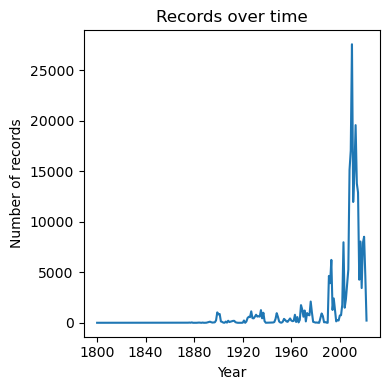

In [14]:
# Yearly aggregation alternative
year_counts = ts_df['DateStart_dt'].dt.to_period('Y').value_counts().sort_index().reset_index()
year_counts.columns = ['Year', 'records']
year_counts['Year'] = year_counts['Year'].dt.to_timestamp()

print(year_counts.head())
plt.figure(figsize=(4,4))
sns.lineplot(data=year_counts, x='Year', y='records', marker='None')
plt.title('Records over time')
plt.xlabel('Year')
plt.ylabel('Number of records')
plt.tight_layout()

plt.gcf().savefig('biota_records_over_time.png', dpi=150, bbox_inches='tight')
plt.show()

# Phyla

### Top 10 phyla

In [64]:
# 1. Load data ---------------------------------------------------------------
orig_file  = 'original.xlsx'
biota_file = 'biota_water.xlsx'

orig_sheets = pd.read_excel(orig_file, sheet_name=None)
taxon_df    = orig_sheets['Taxon'].copy()

biota_df = pd.read_excel(biota_file)

# 2. Clean Taxon sheet -------------------------------------------------------
clean_taxon = taxon_df.dropna(subset=['Phylum']).copy()

# 3. Harmonise key columns ---------------------------------------------------
clean_taxon['AcceptedAphiaId']    = clean_taxon['AcceptedAphiaId'].astype(str)
biota_df['AphiaId (Accepted)']    = biota_df['AphiaId (Accepted)'].astype(str)

# 4. Merge -------------------------------------------------------------------
merged = biota_df.merge(
            clean_taxon[['AcceptedAphiaId', 'Phylum']],
            how='left',
            left_on='AphiaId (Accepted)',
            right_on='AcceptedAphiaId'
        )

# 5. Save outputs ------------------------------------------------------------
merged_out_path = 'biota_water_with_phylum.xlsx'
clean_taxon_out = 'taxon_cleaned.xlsx'

merged.to_excel(merged_out_path, index=False)
clean_taxon.to_excel(clean_taxon_out, index=False)

print('Saved merged dataframe to:', merged_out_path)
print('Saved cleaned Taxon sheet to:', clean_taxon_out)

# 6. Unmatched IDs -----------------------------------------------------------
unmatched_ids = merged[merged['Phylum'].isna()]['AphiaId (Accepted)'].unique()
print('Number of unmatched AphiaIds:')
print(len(unmatched_ids))
print('Unmatched AphiaIds:')
print(unmatched_ids)

# 7. Count unique AphiaIds per Phylum ---------------------------------------
phylum_counts = (merged.dropna(subset=['Phylum'])
                        .groupby('Phylum')['AphiaId (Accepted)']
                        .nunique()
                        .sort_values(ascending=False))

top10 = phylum_counts.head(10)
print('Top 10 phyla counts:')
print(top10)

Saved merged dataframe to: biota_water_with_phylum.xlsx
Saved cleaned Taxon sheet to: taxon_cleaned.xlsx
Number of unmatched AphiaIds:
1
Unmatched AphiaIds:
['2.0']
Top 10 phyla counts:
Phylum
Arthropoda       1289
Annelida         1024
Mollusca          713
Echinodermata     321
Bryozoa           297
Cnidaria          180
Porifera          140
Chordata           90
Nemertea           15
Brachiopoda        11
Name: AphiaId (Accepted), dtype: int64


Unmatched AphiaID 2 is not a problem as 2 = animalia

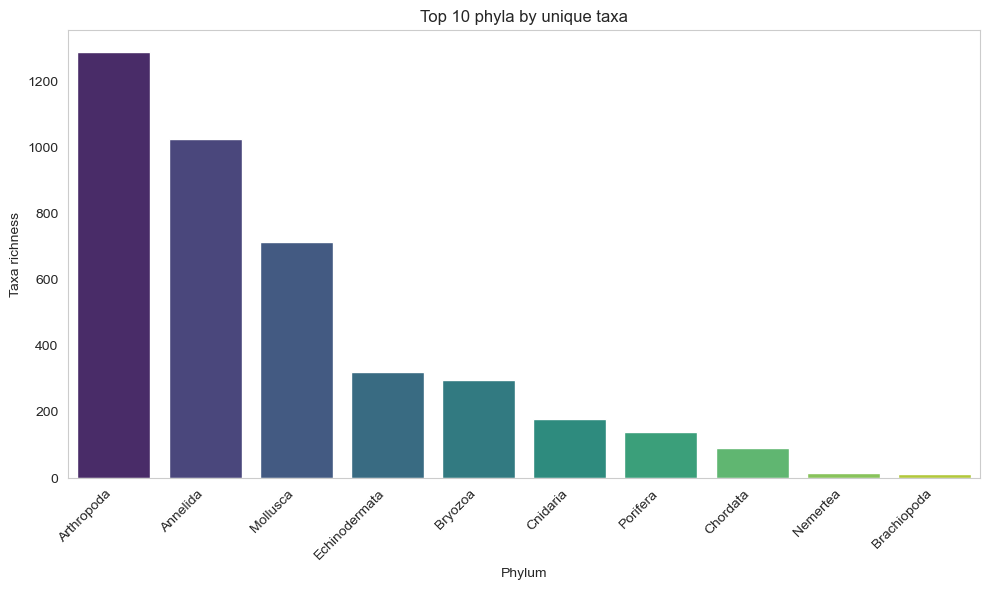

In [65]:
# 8. Plot --------------------------------------------------------------------
plt.figure(figsize=(10,6))
sns.barplot(x=top10.index, y=top10.values, hue=top10.index, palette='viridis', legend=False)
plt.xticks(rotation=45, ha='right')
plt.xlabel('Phylum')
plt.ylabel('Taxa richness')
plt.title('Top 10 phyla by unique taxa')
plt.grid(False)
plt.tight_layout()
plt.savefig("phyla.png", dpi=150, bbox_inches="tight", facecolor="white") 
plt.show()

In [44]:
# Cell 1 — Imports and load the Excel
import pandas as pd
# Load the uploaded file
biota_phylum_df = pd.read_excel('biota_water_with_phylum.xlsx', sheet_name=0)
# Cell 2 — Count records per phylum and prepare top-10 dataframe
# Count records per phylum
counts_by_phylum = biota_phylum_df['Phylum'].fillna('Unknown').value_counts().reset_index()
counts_by_phylum.columns = ['Phylum', 'Records']
# Top 10 phyla by record count
top10_phyla = counts_by_phylum.head(10)

C:\Users\hamod4691\AppData\Local\Temp\ipykernel_12908\990924751.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10_sorted, x='Phylum', y='Records', palette='viridis')  # Swap x and y


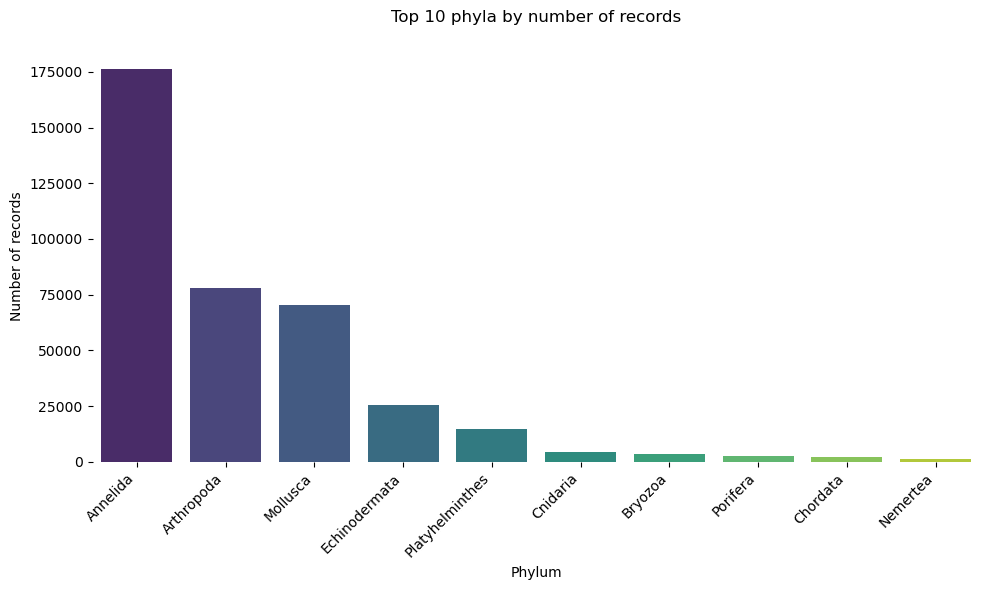

In [45]:
# Cell 3 — Plot vertical barplot of the top 10
import matplotlib.pyplot as plt
import seaborn as sns
# Sort for a nicer vertical plot (largest on the left)
top10_sorted = top10_phyla.sort_values('Records', ascending=False)
plt.figure(figsize=(10, 6))  # Adjust the figure size for a vertical plot
sns.barplot(data=top10_sorted, x='Phylum', y='Records', palette='viridis')  # Swap x and y
plt.title('Top 10 phyla by number of records', pad=20)  # Add padding to the title
plt.xlabel('Phylum')  # Label for the x-axis
plt.ylabel('Number of records')  # Label for the y-axis
plt.xticks(rotation=45, ha='right')  # Rotate x-axis labels for better readability
plt.box(False)  # Remove the surrounding box
plt.tight_layout()
plt.savefig('records_per_phylum.png', dpi=300, bbox_inches='tight')
plt.show()

### Stations with only one phylum

In [81]:
df = pd.read_excel("biota_water_with_phylum.xlsx")  

# 2. How many unique Phyla does each DeviceID contain?  
phylum_counts = df.groupby("DeviceID")["Phylum"].nunique()  
  
# DeviceIDs restricted to a single Phylum  
single_phylum_ids = phylum_counts[phylum_counts == 1]  
print("DeviceIDs with ONE Phylum:", single_phylum_ids.shape[0])  

# 3. Label each DeviceID as single vs multiple  
summary = phylum_counts.apply(  
    lambda x: "Single phylum" if x == 1 else "Multiple phyla"  
).value_counts().reset_index()  
summary.columns = ["Category", "Count"]  
print(summary)  

DeviceIDs with ONE Phylum: 6048
         Category  Count
0  Multiple phyla   6942
1   Single phylum   6048


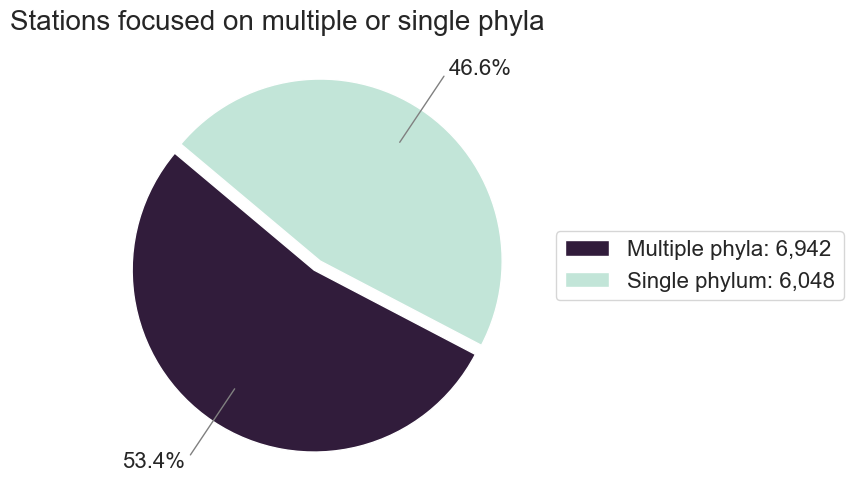

In [82]:
# 4. Styled pie chart  
metrics = summary["Category"]  
counts  = summary["Count"]  
  
# Legend labels with thousand-separators  
legend_labels = [  
    metric + ": " + "{:,}".format(count)  
    for metric, count in zip(metrics, counts)  
]  
  
base_colors = sns.cubehelix_palette(  
    start=.5, rot=-.5, n_colors=len(metrics)  
)  
colors  = base_colors[::-1]          # reverse order  
explode = [0.03] * len(metrics)      # small separation  
  
plt.figure(figsize=(8, 8))  
wedges, _ = plt.pie(  
    counts,  
    labels=["" for _ in metrics],    # invisible labels (legend handles them)  
    startangle=140,  
    colors=colors,  
    explode=explode,  
    wedgeprops={"linewidth": 1, "edgecolor": "white"}  
)  
  
# Annotate percentage outside each wedge  
total_n = sum(counts)  
for i, w in enumerate(wedges):  
    angle = (w.theta2 + w.theta1) / 2  
    x, y  = np.cos(np.deg2rad(angle)), np.sin(np.deg2rad(angle))  
    ha    = "left" if x > 0 else "right"  
    pct   = counts[i] / total_n * 100  
    plt.annotate(  
        "{:.1f}%".format(pct),  
        xy=(x * 0.8, y * 0.8),  
        xytext=(x * 1.3, y * 1.3),  
        ha=ha,  
        va="center",  
        arrowprops=dict(  
            arrowstyle="-",  
            color="gray",  
            connectionstyle="angle,angleA=0,angleB=" + str(angle)  
        )  
    )  
  
plt.title(  
    "Stations focused on multiple or single phyla",  
    loc="right",  
    fontsize=20  
)  
plt.legend(  
    wedges, legend_labels,  
    loc="center left",  
    bbox_to_anchor=(1, 0.5)  
)  
plt.tight_layout()  
plt.savefig("station_one_phylum.png", dpi=150, bbox_inches="tight", facecolor="white") 
plt.show()  

In [83]:
# Read file
file_path = 'biota_water_with_phylum.xlsx'
df_biota = pd.read_excel(file_path)

# Extract DeviceIDs that are linked to only one Phylum and record which Phylum
single_phylum_df = df_biota.groupby('DeviceID')['Phylum'].nunique()
mask_single = single_phylum_df == 1

device_single_phylum = df_biota[df_biota['DeviceID'].isin(single_phylum_df[mask_single].index)]

# For each DeviceID, get the unique Phylum (there will be exactly one)
result_df = device_single_phylum.groupby('DeviceID')['Phylum'].first().reset_index()

print(result_df.head())
print('Total rows:', len(result_df))

# Save to CSV for download
file_name = 'device_single_phylum.csv'
result_df.to_csv(file_name, index=False)
print('Saved CSV file:', file_name)

   DeviceID    Phylum
0       663  Annelida
1       665  Annelida
2       666  Annelida
3       667  Annelida
4       671  Annelida
Total rows: 6048
Saved CSV file: device_single_phylum.csv


Phylum_Class  Year  Multiple  Single  Total  Prop_Single
0             1800         0       3      3          1.0
1             1838         0       1      1          1.0
2             1841         0       2      2          1.0
3             1848         0       1      1          1.0
4             1849         0       1      1          1.0


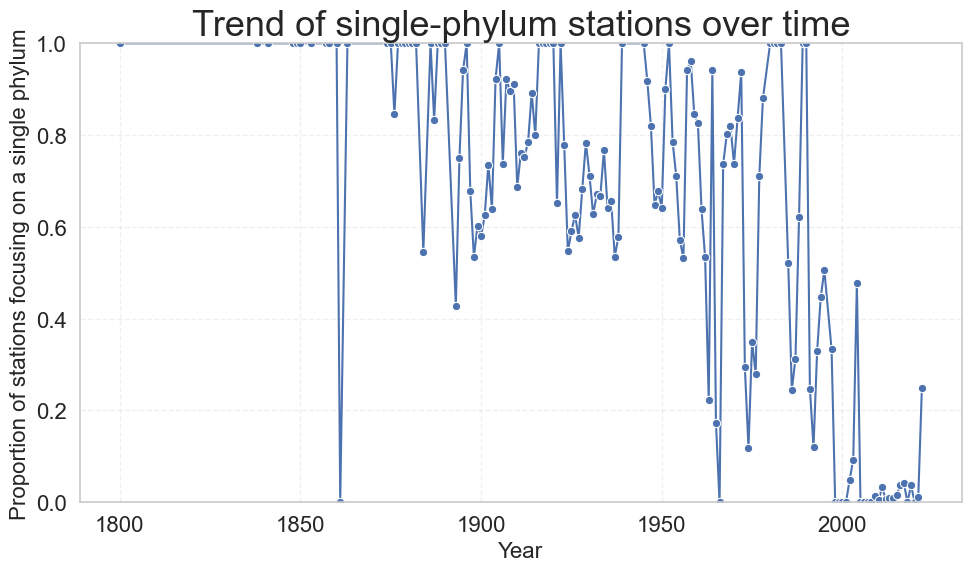

In [87]:
# Load datasets
biota_file = 'biota_water_with_phylum.xlsx'
device_file = 'device_water.xlsx'

df_biota = pd.read_excel(biota_file)
df_device = pd.read_excel(device_file)

# Determine Single vs Multiple Phylum classification for each DeviceID
phylum_counts = df_biota.groupby('DeviceID')['Phylum'].nunique()
class_map = phylum_counts.apply(lambda x: 'Single' if x == 1 else 'Multiple')
class_map = class_map.rename('Phylum_Class').reset_index()

# Merge with device data
merged = pd.merge(df_device, class_map, on='DeviceID', how='inner')

# Ensure DateStart is datetime and extract year
merged['DateStart'] = pd.to_datetime(merged['DateStart'], errors='coerce')
merged = merged.dropna(subset=['DateStart'])
merged['Year'] = merged['DateStart'].dt.year

# Aggregate counts per year
summary_year = (merged.groupby(['Year', 'Phylum_Class'])
                .size()
                .unstack(fill_value=0)
                .reset_index())

# Calculate proportion of single
summary_year['Total'] = summary_year['Single'] + summary_year['Multiple']
summary_year['Prop_Single'] = summary_year['Single'] / summary_year['Total']

print(summary_year.head())

# Plot proportion of single-phylum DeviceIDs over time
plt.figure(figsize=(10,6))
ax = sns.lineplot(data=summary_year, x='Year', y='Prop_Single', marker='o', color='#4c72b0')
plt.ylabel('Proportion of stations focusing on a single phylum')
plt.title('Trend of single-phylum stations over time')
plt.ylim(0,1)
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig("single_phylum_time.png", dpi=150, bbox_inches="tight", facecolor="white") 
plt.show()

          Phylum  Count
0  Echinodermata   2164
1     Arthropoda   2003
2       Mollusca   1727
3       Annelida    142
4       Porifera      4


C:\Users\hamod4691\AppData\Local\Temp\ipykernel_28752\3638966408.py:22: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




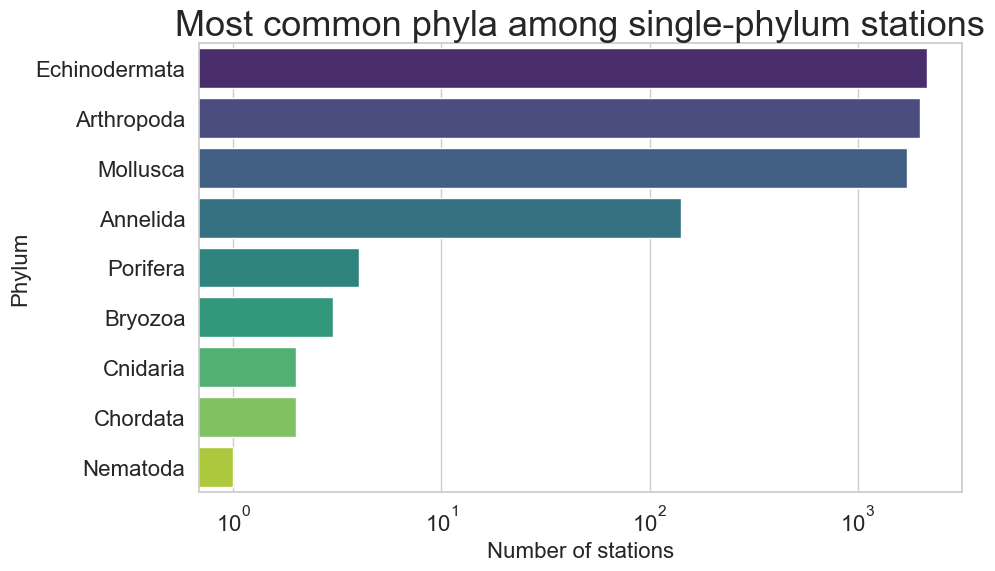

In [86]:
# Ensure single_phylum_list exists (DeviceID, Phylum)
try:
    single_phylum_list
except NameError:
    # Recompute if needed
    df_biota = pd.read_excel('biota_water_with_phylum.xlsx')
    phylum_counts = df_biota.groupby('DeviceID')['Phylum'].nunique()
    ids_single = phylum_counts[phylum_counts == 1].index
    single_phylum_list = (df_biota[df_biota['DeviceID'].isin(ids_single)]
                          .groupby('DeviceID')['Phylum']
                          .first()
                          .reset_index())

# Frequency of each phylum
phylum_freq = single_phylum_list['Phylum'].value_counts().reset_index()
phylum_freq.columns = ['Phylum', 'Count']

print(phylum_freq.head())

# Plot bar chart of top phyla
plt.figure(figsize=(10,6))
ax = sns.barplot(data=phylum_freq, x='Count', y='Phylum', palette='viridis')
plt.title('Most common phyla among single-phylum stations')
plt.xlabel('Number of stations')
plt.ylabel('Phylum')
plt.xscale('log')
plt.tight_layout()
plt.savefig("most_common_phylum.png", dpi=150, bbox_inches="tight", facecolor="white") 
plt.show()

# Taxonomic resolution

Nr of records at different levels of taxonomic resolution

In [57]:
# Load Excel sheets and preview relevant data
biota_path = 'biota_water.xlsx'
original_path = 'original.xlsx'

biota_df = pd.read_excel(biota_path, sheet_name='Sheet1', engine='calamine')
taxon_df = pd.read_excel(original_path, sheet_name='Taxon', engine='calamine')

print(biota_df.head())
print(taxon_df[['AphiaId','Rank']].head())
print('Loaded dataframes and previewed heads')

   CruiseID  StationID  DeviceID  SampleID  SubSampleID  SubsetID  BiotaID  \
0        96        879      1000      1001         1001      1266    33334   
1      1051       9807     10000     10001        10001     10266    77009   
2      1051       9807     10000     10001        10001     10266    77008   
3      1051       9808     10001     10002        10002     10267    77010   
4      1051       9808     10001     10002        10002     10267    77011   

                        Cruise Station Device  ... Abundance PresenceAbsence  \
0                zin_sp22_1980    5600   5600  ...       NaN             1.0   
1  Hydrographic Expeditionffff     903      1  ...       NaN             1.0   
2  Hydrographic Expeditionffff     903      1  ...       NaN             1.0   
3  Hydrographic Expeditionffff     904      1  ...       NaN             1.0   
4  Hydrographic Expeditionffff     904      1  ...       NaN             1.0   

  SumWet  SumDry  SumAFDW Stage SieveFraction  Sub

In [58]:
# Merge Rank from Taxon onto biota using AphiaId (Accepted) -> AphiaId
merged_tmp = biota_df.merge(
    taxon_df[['AphiaId', 'Rank']],
    left_on='AphiaId (Accepted)',
    right_on='AphiaId',
    how='left'
)

print(merged_tmp.head())
print('Performed left merge to add Rank')

   CruiseID  StationID  DeviceID  SampleID  SubSampleID  SubsetID  BiotaID  \
0        96        879      1000      1001         1001      1266    33334   
1      1051       9807     10000     10001        10001     10266    77009   
2      1051       9807     10000     10001        10001     10266    77008   
3      1051       9808     10001     10002        10002     10267    77010   
4      1051       9808     10001     10002        10002     10267    77011   

                        Cruise Station Device  ... SumWet SumDry SumAFDW  \
0                zin_sp22_1980    5600   5600  ...    NaN    NaN     NaN   
1  Hydrographic Expeditionffff     903      1  ...    NaN    NaN     NaN   
2  Hydrographic Expeditionffff     903      1  ...    NaN    NaN     NaN   
3  Hydrographic Expeditionffff     904      1  ...    NaN    NaN     NaN   
4  Hydrographic Expeditionffff     904      1  ...    NaN    NaN     NaN   

   Stage  SieveFraction SubTotalFactor Specification  Remark AphiaId_y  \


In [60]:
# Drop merge helper and tidy columns; save to new Excel
biota_with_rank = merged_tmp.copy()
if 'AphiaId_y' in biota_with_rank.columns:
    biota_with_rank = biota_with_rank.drop(columns=['AphiaId_y'])
if 'AphiaId_x' in biota_with_rank.columns:
    biota_with_rank = biota_with_rank.rename(columns={'AphiaId_x': 'AphiaId'})

output_file = 'biota_water_with_rank.xlsx'
biota_with_rank.to_excel(output_file, index=False)

# Quick verify
verify_df = pd.read_excel(output_file, engine='calamine')
print(verify_df.head())
print('Saved file as ' + output_file)

   CruiseID  StationID  DeviceID  SampleID  SubSampleID  SubsetID  BiotaID  \
0        96        879      1000      1001         1001      1266    33334   
1      1051       9807     10000     10001        10001     10266    77009   
2      1051       9807     10000     10001        10001     10266    77008   
3      1051       9808     10001     10002        10002     10267    77010   
4      1051       9808     10001     10002        10002     10267    77011   

                        Cruise Station Device  ... PresenceAbsence SumWet  \
0                zin_sp22_1980    5600   5600  ...             1.0    NaN   
1  Hydrographic Expeditionffff     903      1  ...             1.0    NaN   
2  Hydrographic Expeditionffff     903      1  ...             1.0    NaN   
3  Hydrographic Expeditionffff     904      1  ...             1.0    NaN   
4  Hydrographic Expeditionffff     904      1  ...             1.0    NaN   

  SumDry  SumAFDW  Stage SieveFraction SubTotalFactor  Specification

In [64]:
# Load the merged Excel file
import pandas as pd

merged_path = 'biota_water_with_rank.xlsx'
df_merged = pd.read_excel(merged_path, engine='calamine')

print(df_merged.head())
print('Loaded merged file')

   CruiseID  StationID  DeviceID  SampleID  SubSampleID  SubsetID  BiotaID  \
0        96        879      1000      1001         1001      1266    33334   
1      1051       9807     10000     10001        10001     10266    77009   
2      1051       9807     10000     10001        10001     10266    77008   
3      1051       9808     10001     10002        10002     10267    77010   
4      1051       9808     10001     10002        10002     10267    77011   

                        Cruise Station Device  ... PresenceAbsence SumWet  \
0                zin_sp22_1980    5600   5600  ...             1.0    NaN   
1  Hydrographic Expeditionffff     903      1  ...             1.0    NaN   
2  Hydrographic Expeditionffff     903      1  ...             1.0    NaN   
3  Hydrographic Expeditionffff     904      1  ...             1.0    NaN   
4  Hydrographic Expeditionffff     904      1  ...             1.0    NaN   

  SumDry  SumAFDW  Stage SieveFraction SubTotalFactor  Specification

In [65]:
# Count records per taxonomic rank
rank_counts = df_merged['Rank'].fillna('Unknown').value_counts().reset_index()
rank_counts.columns = ['Rank', 'Count']

print(rank_counts)
print('Computed counts per Rank')

           Rank   Count
0       Species  173539
1         Genus   36097
2       Unknown   16250
3        Family    6126
4         Class    4692
5        Phylum    3499
6         Order    2693
7    Subspecies    1997
8    Infraorder     493
9     Subphylum     468
10  Superfamily     366
11    Subfamily     324
12     Subclass     273
13     Suborder     220
14   Superclass     116
15   Infraclass     110
16      Kingdom      13
17     Subgenus       8
18        Tribe       8
19   Superorder       3
20      Variety       3
21    Parvorder       2
Computed counts per Rank


### Full

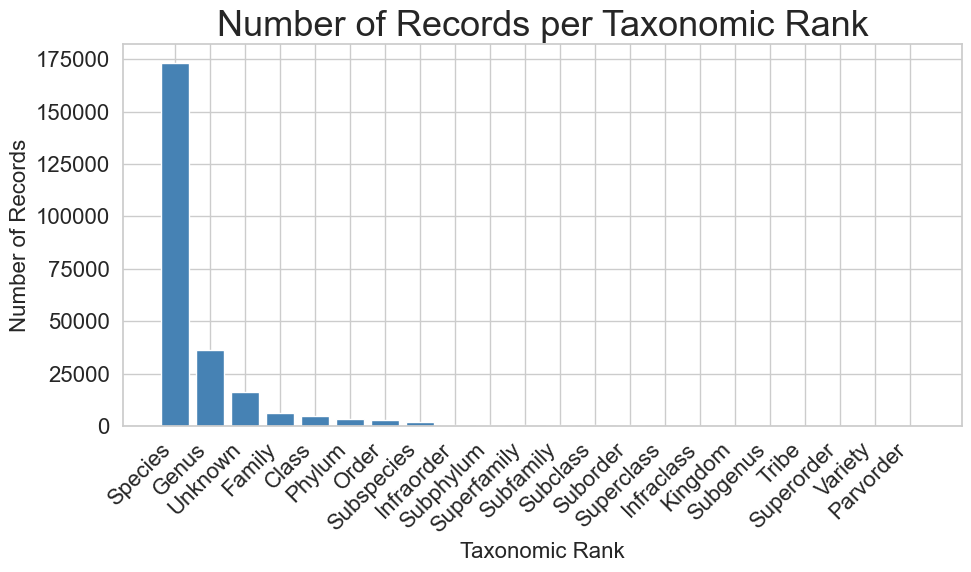

<Figure size 640x480 with 0 Axes>

In [68]:
# Create bar plot of records per taxonomic rank
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.bar(rank_counts['Rank'], rank_counts['Count'], color='steelblue')
plt.xlabel('Taxonomic Rank')
plt.ylabel('Number of Records')
plt.title('Number of Records per Taxonomic Rank')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()
plt.savefig('records_per_rank.png', dpi=300, bbox_inches='tight')

### Partial

In [69]:
# Compute counts for the specified ranks in the given order
target_order = ['Phylum','Class','Order','Family','Genus','Species','Subspecies']

rank_series = df_merged['Rank'].astype(str).str.strip().str.title()
rank_counts = rank_series.value_counts().reindex(target_order).fillna(0).astype(int).reset_index()
rank_counts.columns = ['Rank', 'Count']

print(rank_counts)
print('Computed counts for target ranks')

         Rank   Count
0      Phylum    3499
1       Class    4692
2       Order    2693
3      Family    6126
4       Genus   36097
5     Species  173539
6  Subspecies    1997
Computed counts for target ranks


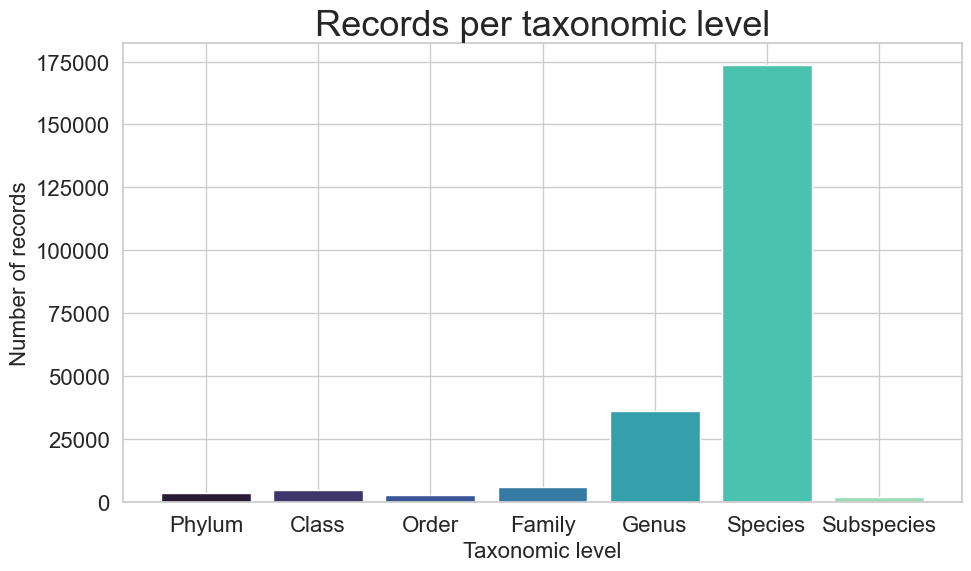

Displayed plot for selected ranks


<Figure size 640x480 with 0 Axes>

In [117]:
# Plot counts using distinct colours for each rank
colors = sns.color_palette("mako", n_colors=7)

plt.figure(figsize=(10, 6))
plt.bar(rank_counts['Rank'], rank_counts['Count'], color=colors)
plt.xlabel('Taxonomic level')
plt.ylabel('Number of records')
plt.title('Records per taxonomic level')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
plt.savefig('records_per_rank_selected.png', dpi=300, bbox_inches='tight')
print('Displayed plot for selected ranks')

# LME 

### Spatial join with LMEs

   Id                LME  ET_ID  \
0   1  Fareo Plateau LME      0   
1   2        Iceland LME      1   
2   3  Greenland Sea LME      2   
3   4  Norwegain Sea LME      3   
4   5    Barents Sea LME      4   

                                             Report  \
0  Large Marine Ecosystem (LMEs) of the Arctic area   
1  Large Marine Ecosystem (LMEs) of the Arctic area   
2  Large Marine Ecosystem (LMEs) of the Arctic area   
3  Large Marine Ecosystem (LMEs) of the Arctic area   
4  Large Marine Ecosystem (LMEs) of the Arctic area   

                                          Report_URL  \
0  http://pame.is/index.php/projects/ecosystem-ap...   
1  http://pame.is/index.php/projects/ecosystem-ap...   
2  http://pame.is/index.php/projects/ecosystem-ap...   
3  http://pame.is/index.php/projects/ecosystem-ap...   
4  http://pame.is/index.php/projects/ecosystem-ap...   

                                        Source  \
0  Arctic Council - http://arctic-council.org/   
1  Arctic Council - h

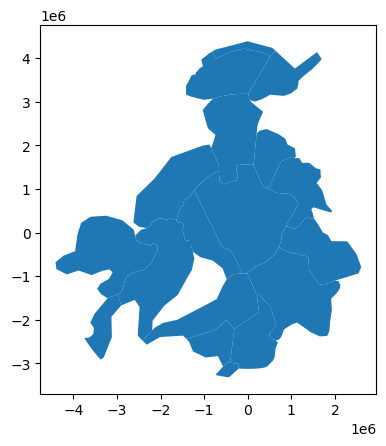

In [64]:
import geopandas as gpd
# Load the shapefile
gdf_lme = gpd.read_file("LME_boundaries_2014/LME_2013_polygon.shp")
# Print the first few rows to inspect the data
print(gdf_lme.head())
# Check the geometry type
print(gdf_lme.geom_type.unique())  # Should return ['Polygon', 'MultiPolygon']
# Check the CRS
print(gdf_lme.crs)  # Should return EPSG:4326 (or something similar)
# Plot the shapefile using GeoPandas to ensure it contains valid geometries
gdf_lme.plot()
plt.show()

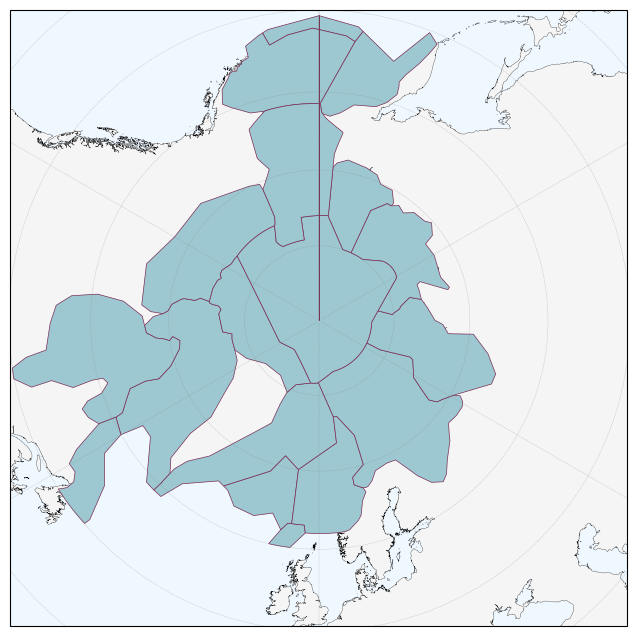

In [70]:
import os
import geopandas as gpd
import matplotlib.pyplot as plt
from cartopy.io.shapereader import Reader
import cartopy.crs as ccrs
import cartopy.feature as cfeature
# Ensure shapefile can be read even if .shx is missing
os.environ['SHAPE_RESTORE_SHX'] = 'YES'
# Load shapefile as GeoDataFrame
gdf_lme = gpd.read_file("LME_boundaries_2014/LME_2013_polygon_projected.shp")
# Ensure CRS is EPSG:4326
if gdf_lme.crs != "EPSG:4326":
    gdf_lme = gdf_lme.to_crs(epsg=4326)
# Validate and fix geometries
gdf_lme = gdf_lme[gdf_lme.is_valid]
gdf_lme['geometry'] = gdf_lme['geometry'].buffer(0)
# Create the plot with smaller figure size
plt.figure(figsize=(8, 8))
proj = ccrs.NorthPolarStereo()
ax = plt.axes(projection=proj)
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor='whitesmoke')
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')
ax.coastlines(resolution='10m', linewidth=0.2, color='black')
ax.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')
# Add shapefile polygons with fill color
shape_reader = Reader("LME_boundaries_2014/LME_2013_polygon_projected.shp")
polygon_feature = cfeature.ShapelyFeature(
    list(shape_reader.geometries()),
    ccrs.PlateCarree(),
    edgecolor='#792D54',  # Boundary color
    facecolor='#9DC8D2'  # Fill color for the polygons
)
ax.add_feature(polygon_feature, linewidth=0.5)
plt.show()

In [72]:
# Load device data
df_device = pd.read_excel('device_water.xlsx', sheet_name='Sheet1', engine='calamine')

# Load LME polygons
gdf_lme = gpd.read_file('LME_boundaries_2014/LME_2013_polygon_projected.shp')

# Quick previews
print(df_device.head())
print(gdf_lme[['Id', 'LME']].head())
print(gdf_lme.crs)

   CruiseID  StationID  DeviceID        Cruise Station Device  \
0        22        532       633  rusalca_2004      R6      1   
1        22        533       634  rusalca_2004     R10      1   
2        22        534       635  rusalca_2004     R11      1   
3        22        535       636  rusalca_2004     R13      1   
4        22        536       637  rusalca_2004     R15      1   

                      Project TaxonomicResolution TaxonomicCoverage   Realm  \
0  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   
1  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   
2  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   
3  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   
4  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   

                                               Title  \
0  Biomass of megabenthic organisms collected fro...   
1  Biomass of megabent

In [73]:
# Create point GeoDataFrame from device lat/lon

from shapely.geometry import Point

gdf_device = gpd.GeoDataFrame(
    df_device.copy(),
    geometry=[Point(xy) for xy in zip(df_device['LonStart'], df_device['LatStart'])],
    crs='EPSG:4326'
)

print(gdf_device.head())
print(gdf_device.crs)

   CruiseID  StationID  DeviceID        Cruise Station Device  \
0        22        532       633  rusalca_2004      R6      1   
1        22        533       634  rusalca_2004     R10      1   
2        22        534       635  rusalca_2004     R11      1   
3        22        535       636  rusalca_2004     R13      1   
4        22        536       637  rusalca_2004     R15      1   

                      Project TaxonomicResolution TaxonomicCoverage   Realm  \
0  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   
1  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   
2  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   
3  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   
4  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   

                                               Title  \
0  Biomass of megabenthic organisms collected fro...   
1  Biomass of megabent

In [74]:
# Ensure LME polygons are in the same CRS (EPSG:4326)

if gdf_lme.crs is None:
    gdf_lme.set_crs('EPSG:4326', inplace=True)
elif gdf_lme.crs.to_string() != 'EPSG:4326':
    gdf_lme = gdf_lme.to_crs('EPSG:4326')

print(gdf_lme.crs)

EPSG:4326


In [77]:
# Spatial join: append LME name to each device point
# Assumes gdf_device (points, EPSG:4326) and gdf_lme (polygons, EPSG:4326) already exist in memory.

joined = gpd.sjoin(
    gdf_device,
    gdf_lme[['LME', 'geometry']],
    how='left',
    predicate='intersects'
)

# Quick look at the LME column (this does not show geometry, but joined still has it)
print(joined[['LME']].head())

               LME
0  Chukchi Sea LME
1  Chukchi Sea LME
2  Chukchi Sea LME
3  Chukchi Sea LME
4  Chukchi Sea LME


In [79]:
# Keep original device cols + LME, drop geometry, save CSV and Excel

result = pd.DataFrame(gdf_device.drop(columns=['geometry']))
result['LME'] = joined['LME'].values

result.to_csv('device_water_with_LME.csv', index=False)
result.to_excel('device_water_with_LME.xlsx', index=False)

print(result.head())
print('device_water_with_LME.csv')
print('device_water_with_LME.xlsx')

   CruiseID  StationID  DeviceID        Cruise Station Device  \
0        22        532       633  rusalca_2004      R6      1   
1        22        533       634  rusalca_2004     R10      1   
2        22        534       635  rusalca_2004     R11      1   
3        22        535       636  rusalca_2004     R13      1   
4        22        536       637  rusalca_2004     R15      1   

                      Project TaxonomicResolution TaxonomicCoverage   Realm  \
0  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   
1  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   
2  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   
3  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   
4  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   

                                               Title  \
0  Biomass of megabenthic organisms collected fro...   
1  Biomass of megabent

In [80]:
# Basic counts and null check for LME coverage

total_rows = result.shape[0]
matched_rows = result['LME'].notna().sum()
unmatched_rows = total_rows - matched_rows

print(total_rows)
print(matched_rows)
print(unmatched_rows)

print(result['LME'].value_counts().head())

12990
11641
1349
LME
Barents Sea LME     5766
Chukchi Sea LME     2180
Kara Sea LME         926
Laptev Sea LME       673
Beaufort Sea LME     627
Name: count, dtype: int64


OLD

Inspect results in ArcGIS

### Nr of stations and AphiaId per LME

In [83]:
# Nr of DeviceID per LME

# Group device_water_with_LME.xlsx by LME_NAME and count unique DeviceID
df = pd.read_excel('device_water_with_LME.xlsx', engine='calamine')
count_df = df.groupby('LME')['DeviceID'].nunique().reset_index(name='Unique_DeviceID_Count')

# Sort for readability
count_df = count_df.sort_values('Unique_DeviceID_Count', ascending=False)

print(count_df.head(20))

# Save summary to file
summary_file = 'deviceID_counts_per_LME.xlsx'
count_df.to_excel(summary_file, index=False)
print('Saved summary to', summary_file)

                                  LME  Unique_DeviceID_Count
1                     Barents Sea LME                   5766
4                     Chukchi Sea LME                   2180
11                       Kara Sea LME                    926
13                     Laptev Sea LME                    673
2                    Beaufort Sea LME                    627
15                  Norwegain Sea LME                    600
8                   Greenland Sea LME                    233
5                 East Bering Sea LME                    177
3                  Central Arctic LME                    127
9                      Hudson Bay LME                    102
6               East Siberian Sea LME                     96
0                      Baffin Bay LME                     60
10                        Iceland LME                     50
16                West Bering Sea LME                      9
12                   Labrador Sea LME                      8
7                   Fare

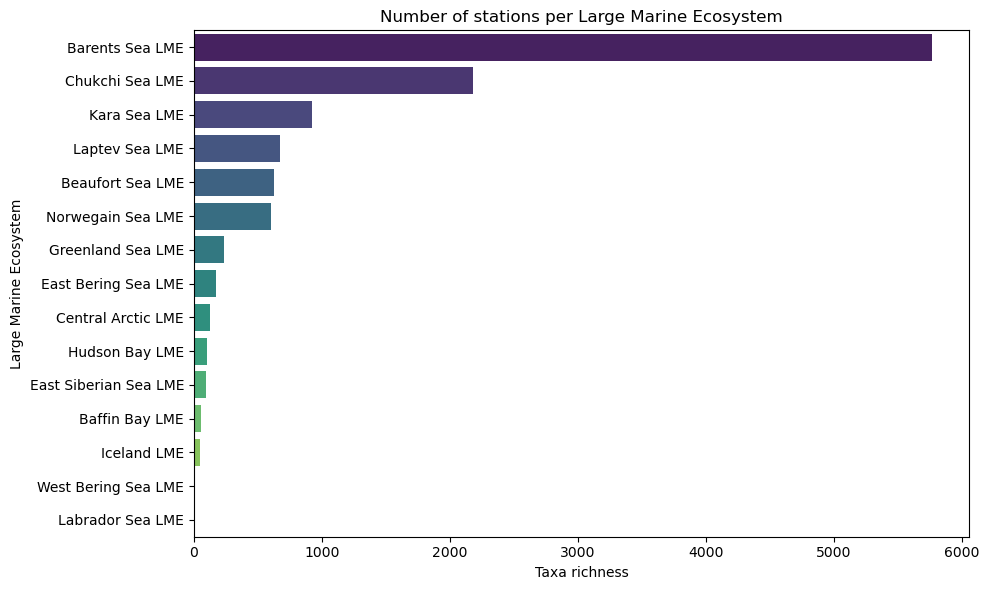

In [85]:
# Make barplot
count_df = pd.read_excel('deviceID_counts_per_LME.xlsx', engine='calamine')
plot_df = count_df.head(15)

plt.figure(figsize=(10,6))
sns.barplot(data=plot_df,
            x='Unique_DeviceID_Count',
            y='LME',
            hue='LME',      # use y variable for hue to satisfy API
            palette='viridis',
            legend=False)
plt.xlabel('Taxa richness')
plt.ylabel('Large Marine Ecosystem')
plt.title('Number of stations per Large Marine Ecosystem')
plt.tight_layout()
plt.savefig("stations_per_LME.png", dpi=150, bbox_inches="tight", facecolor="white") 
plt.show()

In [86]:
# Add LME column to biota_water 
# -----------------------------  
# 1. Load the two workbooks  
# -----------------------------  
# If your sheet of interest is not the first one, replace 0 with the sheet name  
device_df = pd.read_excel("device_water_with_LME.xlsx", sheet_name=0)  
biota_df  = pd.read_excel("biota_water.xlsx",            sheet_name=0)  
  
# -----------------------------  
# 2. Build the lookup table that holds DeviceID and LME_NAME  
# -----------------------------  
lme_lookup = (  
    device_df[["DeviceID", "LME"]]  # keep only what we need  
    .drop_duplicates()                   # prevent accidental duplicates  
)  
  
# -----------------------------  
# 3. Merge into the biota data  
# -----------------------------  
biota_merged = biota_df.merge(  
    lme_lookup,  
    on="DeviceID",         # join key  
    how="left"             # keep every biota record even if no match  
)  
  
# -----------------------------  
# 4. Quick sanity-check  
# -----------------------------  
display(biota_merged.head())  # Jupyter will show the first 5 rows  
  
# -----------------------------  
# 5. Save the result  
# -----------------------------  
output_file = "biota_water_with_LME.xlsx"  
biota_merged.to_excel(output_file, index=False)  
print("Merged file written to:", output_file)  

,CruiseID,StationID,DeviceID,SampleID,SubSampleID,SubsetID,BiotaID,Cruise,Station,Device,...,PresenceAbsence,SumWet,SumDry,SumAFDW,Stage,SieveFraction,SubTotalFactor,Specification,Remark,LME
0,96,879,1000,1001,1001,1266,33334,zin_sp22_1980,5600,5600,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Laptev Sea LME
1,1051,9807,10000,10001,10001,10266,77009,Hydrographic Expeditionffff,903,1,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Barents Sea LME
2,1051,9807,10000,10001,10001,10266,77008,Hydrographic Expeditionffff,903,1,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Barents Sea LME
3,1051,9808,10001,10002,10002,10267,77010,Hydrographic Expeditionffff,904,1,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Barents Sea LME
4,1051,9808,10001,10002,10002,10267,77011,Hydrographic Expeditionffff,904,1,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Barents Sea LME


Merged file written to: biota_water_with_LME.xlsx


In [88]:
# ────────────────────────────────────────────────────────────────  
# Count distinct AphiaId (Accepted) per LME_NAME  
# ────────────────────────────────────────────────────────────────  
# 1. Load the merged dataset  
df = pd.read_excel("biota_water_with_LME.xlsx", sheet_name=0)  
  
# 2. Group-by LME_NAME, count unique accepted Aphia IDs  
lme_counts = (  
    df.groupby("LME")["AphiaId (Accepted)"]  
      .nunique(dropna=True)             # dropna=True excludes  counts  
      .reset_index()  
      .rename(columns={"AphiaId (Accepted)": "Unique_AphiaId_Count"})  
      .sort_values("Unique_AphiaId_Count", ascending=False)  
)  
  
# 3. Display the result in-notebook  
display(lme_counts)  
  
# 4. Save to Excel (optional)  
lme_counts.to_excel("unique_aphia_per_LME.xlsx", index=False)  
print("Summary saved to unique_aphia_per_LME.xlsx")  

,LME,Unique_AphiaId_Count
1,Barents Sea LME,2728
15,Norwegain Sea LME,1838
2,Beaufort Sea LME,1156
4,Chukchi Sea LME,1135
13,Laptev Sea LME,979
11,Kara Sea LME,665
0,Baffin Bay LME,663
8,Greenland Sea LME,621
9,Hudson Bay LME,446
3,Central Arctic LME,243


Summary saved to unique_aphia_per_LME.xlsx


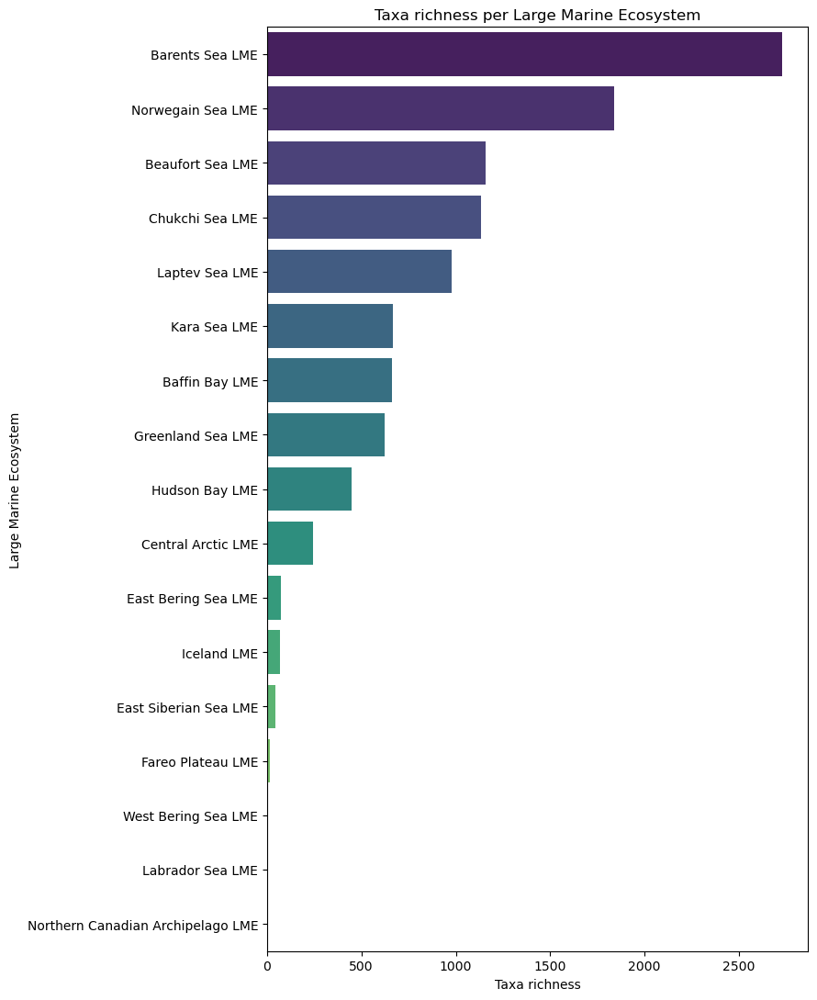

In [89]:
# Load the merged data  
df = pd.read_excel("biota_water_with_LME.xlsx", sheet_name=0)  
  
# Group by LME and count unique accepted Aphia IDs  
lme_counts = (  
    df.groupby("LME")["AphiaId (Accepted)"]  
      .nunique(dropna=True)  
      .reset_index()  
      .rename(columns={"AphiaId (Accepted)": "Unique_AphiaId_Count"})  
      .sort_values("Unique_AphiaId_Count", ascending=False)   # ← sort descending  
)  
  
# Horizontal bar-plot (large values at top)  
plt.figure(figsize=(9,11))
ax = sns.barplot(
    data=lme_counts,
    y='LME',
    x='Unique_AphiaId_Count',
    hue='LME',    # set hue same as y
    dodge=False,
     palette='viridis',
    legend=False       # no legend needed
)
ax.set_xlabel('Taxa richness')
ax.set_ylabel('Large Marine Ecosystem')
ax.set_title('Taxa richness per Large Marine Ecosystem')
plt.tight_layout()
plt.savefig("taxa_per_LME.png", dpi=150, bbox_inches="tight", facecolor="white") 
plt.show()

In [91]:
# Load pre-aggregated station counts per LME
count_df = pd.read_excel('deviceID_counts_per_LME.xlsx', engine='calamine')

# Keep only required columns and ensure expected names
stations_df = count_df.rename(columns={'Unique_DeviceID_Count': 'Unique_DeviceID_Count', 'LME': 'LME'})[['LME', 'Unique_DeviceID_Count']]

print(stations_df.head())
print('Loaded station counts')

                LME  Unique_DeviceID_Count
0   Barents Sea LME                   5766
1   Chukchi Sea LME                   2180
2      Kara Sea LME                    926
3    Laptev Sea LME                    673
4  Beaufort Sea LME                    627
Loaded station counts


In [92]:
# Load merged biota + LME data and compute taxa richness (unique accepted Aphia IDs) per LME
biota_df = pd.read_excel('biota_water_with_LME.xlsx', sheet_name=0, engine='calamine')

richness_df = (
    biota_df.groupby('LME')['AphiaId (Accepted)']
    .nunique(dropna=True)
    .reset_index()
    .rename(columns={'AphiaId (Accepted)': 'Unique_AphiaId_Count'})
)

print(richness_df.head())
print('Computed taxa richness per LME')

                  LME  Unique_AphiaId_Count
0      Baffin Bay LME                   663
1     Barents Sea LME                  2728
2    Beaufort Sea LME                  1156
3  Central Arctic LME                   243
4     Chukchi Sea LME                  1135
Computed taxa richness per LME


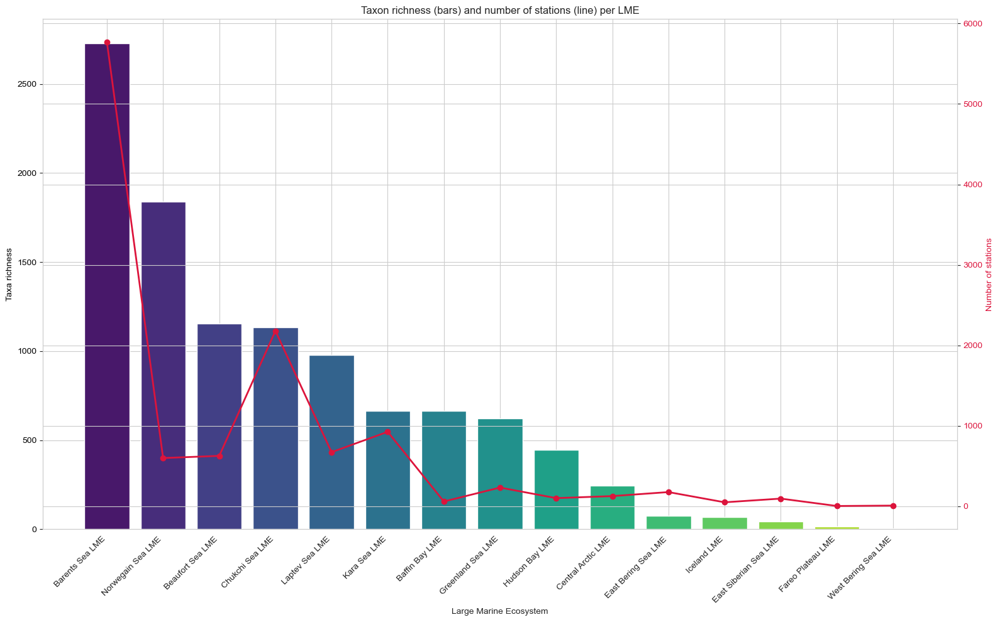

Created twin-axis plot


<Figure size 640x480 with 0 Axes>

In [93]:
# Merge on LME_NAME
merged = richness_df.merge(stations_df, on='LME', how='inner')

# Order by taxa richness and select top 15
merged = merged.sort_values('Unique_AphiaId_Count', ascending=False).head(15)

# Preserve order for plotting
merged['LME'] = pd.Categorical(merged['LME'], categories=merged['LME'], ordered=True)

# Plot: bars = taxa richness (left y), line = number of stations (right y)
sns.set_style('whitegrid')
fig, ax1 = plt.subplots(figsize=(16, 10))

# Bars for taxa richness
bar_colors = sns.color_palette('viridis', n_colors=len(merged))
ax1.bar(merged['LME'], merged['Unique_AphiaId_Count'], color=bar_colors)
ax1.set_ylabel('Taxa richness', color='black')
ax1.tick_params(axis='y', labelcolor='black')

# Line for number of stations
ax2 = ax1.twinx()
ax2.plot(merged['LME'], merged['Unique_DeviceID_Count'], color='crimson', marker='o', linewidth=2)
ax2.set_ylabel('Number of stations', color='crimson')
ax2.tick_params(axis='y', labelcolor='crimson')

# Shared x-axis formatting
ax1.set_xlabel('Large Marine Ecosystem')
ax1.set_title('Taxon richness (bars) and number of stations (line) per LME')
ax1.set_xticks(range(len(merged['LME'])))
ax1.set_xticklabels(list(merged['LME']))
plt.setp(ax1.get_xticklabels(), rotation=45, ha='right')
plt.xticks(ha='right')
plt.tight_layout()
plt.show()
plt.savefig("taxa_vs_stations_per_LME.png", dpi=150, bbox_inches="tight", facecolor="white") 

print('Created twin-axis plot')

### Number of records per LME

### Visualizations of mean taxa richness per LME

In [96]:
# Mean taxa richness per station in each LME

# 1. Read the Excel file  
file_path = "biota_water_with_LME.xlsx"          
df = pd.read_excel(file_path)  
  
# 2. Check that the key columns are present  
needed = ["AphiaId (Accepted)", "DeviceID", "LME"]  
missing = [c for c in needed if c not in df.columns]  
if missing:  
    raise ValueError("Missing columns: " + ", ".join(missing))  
  
# 3. Count unique AphiaIds per DeviceID inside each LME  
counts = (  
    df.groupby(["LME", "DeviceID"])["AphiaId (Accepted)"]  
      .nunique()  
      .reset_index(name="unique_aphia_per_device")  
)  
  
# 4. Mean of those counts per LME  
mean_per_lme = (  
    counts.groupby("LME")["unique_aphia_per_device"]  
          .mean()  
          .sort_values(ascending=False)              # optional: sort for prettier plot  
          .reset_index()  
)  
  
display(mean_per_lme.head())        # quick preview  

,LME,unique_aphia_per_device
0,Baffin Bay LME,72.166667
1,Norwegain Sea LME,57.698333
2,Chukchi Sea LME,33.133486
3,Beaufort Sea LME,21.108453
4,Central Arctic LME,18.102362


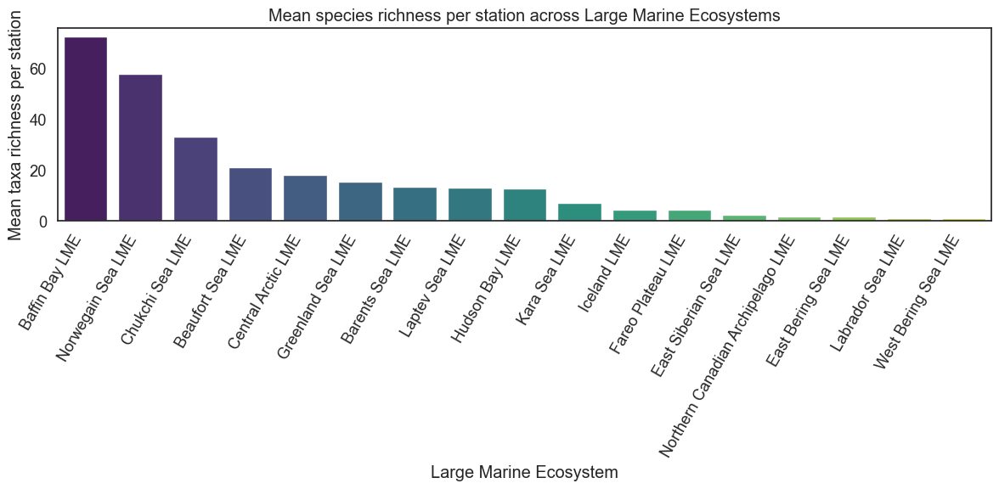

In [97]:
# Barplot of mean unique AphiaIds per station and LME
import matplotlib.pyplot as plt  
import seaborn as sns  

plt.figure(figsize=(12, 6))  
  
sns.barplot(  
    data=mean_per_lme,  
    x="LME",  
    y="unique_aphia_per_device",  
    hue="LME",          # map each bar to its own hue  
    palette="viridis",       # full Viridis palette  
    dodge=False,             # keep bars single, not side-by-side  
    legend=False             # suppress redundant legend  
)  
  
plt.xticks(rotation=60, ha="right")  
plt.ylabel("Mean taxa richness per station")  
plt.xlabel("Large Marine Ecosystem")  
plt.title("Mean species richness per station across Large Marine Ecosystems")  
plt.tight_layout() 
plt.savefig("mean_taxa_per_LME.png", dpi=150, bbox_inches="tight", facecolor="white") 
plt.show()  

,LME,mean_unique_aphia_per_device,unique_device_count
0,Baffin Bay LME,72.166667,60
1,Norwegain Sea LME,57.698333,600
2,Chukchi Sea LME,33.133486,2180
3,Beaufort Sea LME,21.108453,627
4,Central Arctic LME,18.102362,127


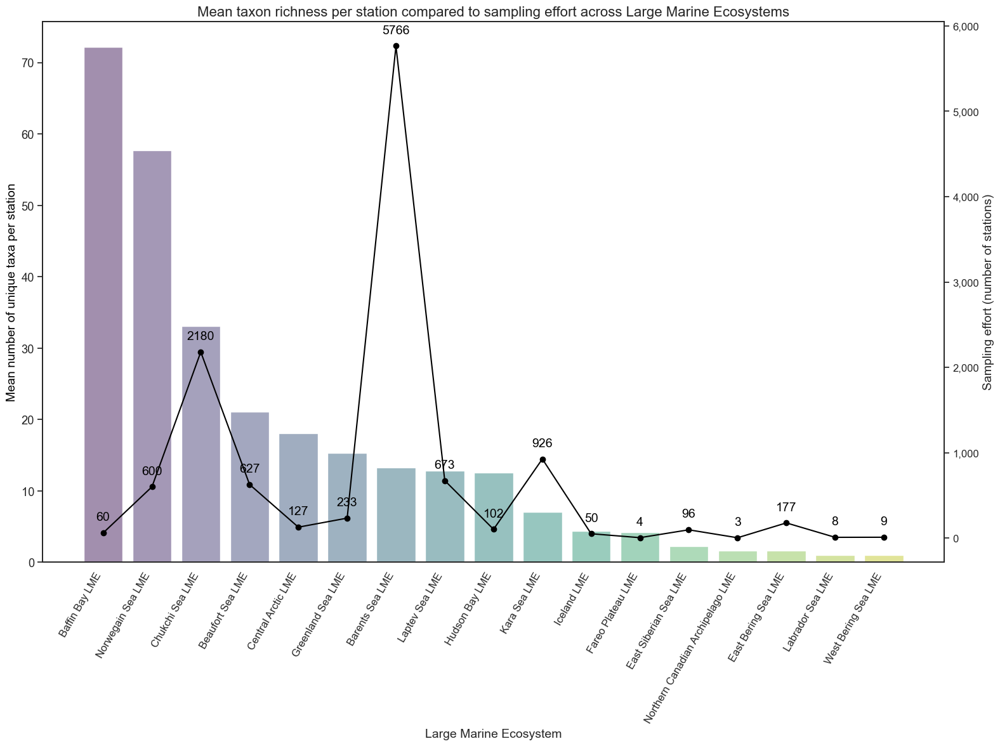

In [98]:
# -------------------------------------------------------------------  
# 1.  Load data (skip if 'df' already exists in memory)  
# -------------------------------------------------------------------  
try:  
    df  
except NameError:  
    file_path = "biota_water_with_LME.xlsx"  
    df = pd.read_excel(file_path)  
  
# -------------------------------------------------------------------  
# 2.  Build summary table: mean richness & sampling effort per LME  
# -------------------------------------------------------------------  
counts = (  
    df.groupby(["LME", "DeviceID"])["AphiaId (Accepted)"]  
      .nunique()  
      .reset_index(name="unique_aphia_per_device")  
)  
mean_per_lme = (  
    counts.groupby("LME")["unique_aphia_per_device"]  
          .mean()  
          .reset_index(name="mean_unique_aphia_per_device")  
)  
effort = (  
    df.groupby("LME")["DeviceID"]  
      .nunique()  
      .reset_index(name="unique_device_count")  
)  
combined = (  
    mean_per_lme  
      .merge(effort, on="LME")  
      .sort_values("mean_unique_aphia_per_device", ascending=False)  
      .reset_index(drop=True)  
)  
  
display(combined.head())          # quick peek at the summary table  
  
# -------------------------------------------------------------------  
# 3.  Build a lightened Viridis palette (each colour blended 50 % with white)  
# -------------------------------------------------------------------  
# lightened viridis palette (already computed)
base_palette = sns.color_palette('viridis', n_colors=len(combined))
light_palette = [(0.5*r+0.5,0.5*g+0.5,0.5*b+0.5) for r,g,b in base_palette]
# map palette to LME order
palette_dict = {lme: light_palette[i] for i,lme in enumerate(combined['LME'])}

sns.set(style='white', font_scale=1.2)
plt.figure(figsize=(16,12))
ax = sns.barplot(data=combined, x='LME', y='mean_unique_aphia_per_device', hue='LME', palette=palette_dict, dodge=False, legend=False)
ax.set_xlabel('Large Marine Ecosystem', fontsize=14)
ax.set_ylabel('Mean number of unique taxa per station', color='black', fontsize=14)
plt.setp(ax.get_xticklabels(), rotation=60, ha='right', fontsize=12)
ax.set_title('Mean taxon richness per station compared to sampling effort across Large Marine Ecosystems', fontsize=16)

ax2 = ax.twinx()
ax2.plot(ax.get_xticks(), combined['unique_device_count'], color='black', marker='o', linestyle='-')
ax2.set_ylabel('Sampling effort (number of stations)', fontsize=14)

fmt = FuncFormatter(lambda x, pos: '{:,.0f}'.format(x))
ax.yaxis.set_major_formatter(fmt)
ax2.yaxis.set_major_formatter(fmt)

max_eff = combined['unique_device_count'].max()
for x,y in zip(ax.get_xticks(), combined['unique_device_count']):
    ax2.text(x, y+max_eff*0.02, str(int(y)), ha='center', va='bottom', fontsize=14, color='black')

ax.grid(False)
ax2.grid(False)
ax2.tick_params(axis='y', labelsize=12)
plt.tight_layout()
plt.savefig("mean_taxa_sampling_per_LME.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

### Visualization of taxa overlap between LMEs

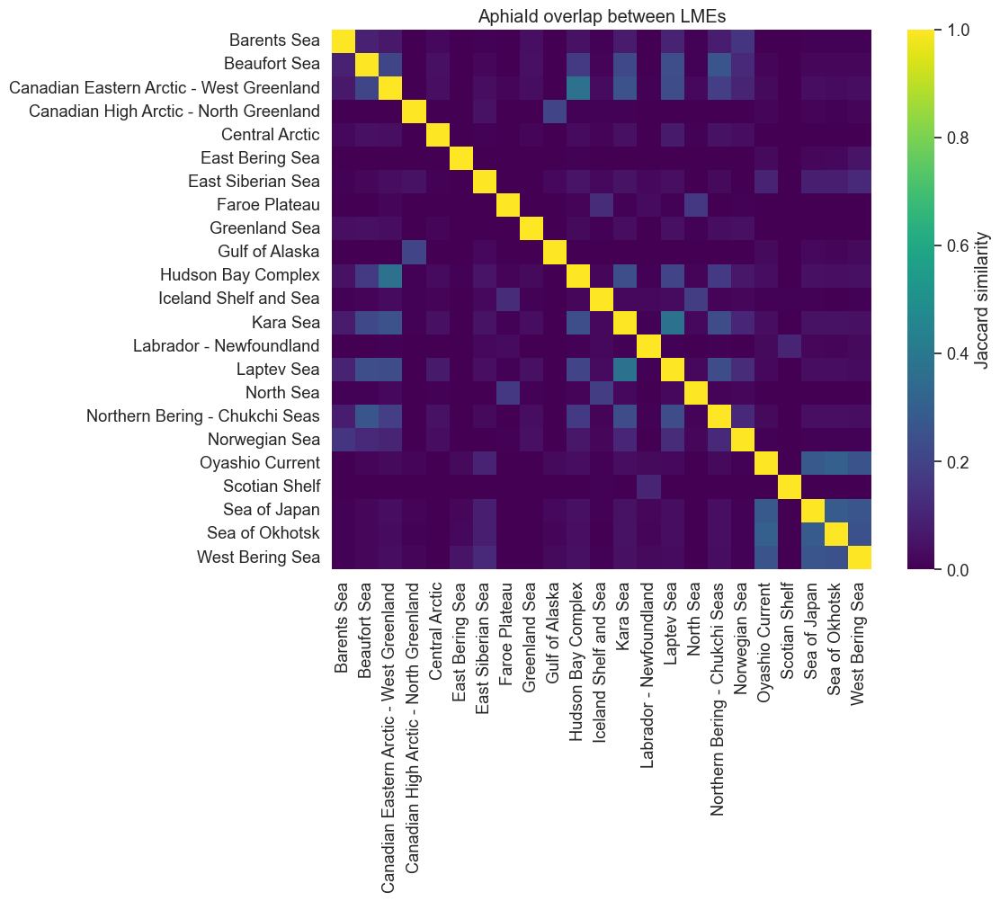

In [80]:
# 1. Load data  
df = pd.read_excel("biota_water_with_LME.xlsx")  
  
# 2. Build set of AphiaIds per LME  
lme_sets = df.groupby("LME_NAME")["AphiaId (Accepted)"].apply(set)  
  
# 3. Jaccard similarity matrix  
lmes = lme_sets.index.tolist()  
n     = len(lmes)  
jac   = np.zeros((n, n))  
for i in range(n):  
    for j in range(n):  
        inter = len(lme_sets.iloc[i] & lme_sets.iloc[j])  
        union = len(lme_sets.iloc[i] | lme_sets.iloc[j])  
        jac[i, j] = inter / union if union else 0  
  
sim_df = pd.DataFrame(jac, index=lmes, columns=lmes)  
  
# 4. Heat-map  
plt.figure(figsize=(12, 10))  
sns.heatmap(sim_df, cmap="viridis", square=True,  
            cbar_kws={"label": "Jaccard similarity"})  
plt.title("AphiaId overlap between LMEs")  
plt.tight_layout()  
plt.savefig("overlap_LME.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()  

# Gear

### Split into coarser gear types

Add the coarser gear categories to the Device sheet

In [119]:
# Read Device sheet from original.xlsx and device_water.xlsx
orig_device_df = pd.read_excel('original.xlsx', sheet_name='Device', engine='calamine')
water_df = pd.read_excel('device_water.xlsx', engine='calamine')

# Keep only DeviceID and Gear columns from original Device sheet
gear_df = orig_device_df[['DeviceID', 'Gear']]

# Merge on DeviceID
merged_df = water_df.merge(gear_df, on='DeviceID', how='left')

# Save to new Excel file
output_filename = 'device_water_with_gear.xlsx'
merged_df.to_excel(output_filename, index=False)

# Show head of merged dataframe to user
print(merged_df.head())
print('Merged dataframe saved to ' + output_filename)

   CruiseID  StationID  DeviceID        Cruise Station Device  \
0        22        532       633  rusalca_2004      R6      1   
1        22        533       634  rusalca_2004     R10      1   
2        22        534       635  rusalca_2004     R11      1   
3        22        535       636  rusalca_2004     R13      1   
4        22        536       637  rusalca_2004     R15      1   

                      Project TaxonomicResolution TaxonomicCoverage   Realm  \
0  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   
1  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   
2  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   
3  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   
4  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   

                                               Title  \
0  Biomass of megabenthic organisms collected fro...   
1  Biomass of megabent

In [120]:
# Load existing merged file (with Gear column) 
merged_df = pd.read_excel('device_water_with_gear.xlsx', engine='calamine')

# Load Gear sheet from original.xlsx
gear_sheet_df = pd.read_excel('original.xlsx', sheet_name='Gear', engine='calamine')

# Keep relevant columns: Name and Category
gear_category_df = gear_sheet_df[['Name', 'Category']].drop_duplicates()

# Merge on Gear (merged_df) and Name (gear_category_df)
final_df = merged_df.merge(gear_category_df, left_on='Gear', right_on='Name', how='left')

# Drop the redundant Name column after merge
final_df = final_df.drop(columns=['Name'])

# Save to new Excel file
output_filename = 'device_water_with_gear.xlsx'
final_df.to_excel(output_filename, index=False)

# Show head of the final dataframe
print(final_df.head())
print('Updated dataframe with Category saved to ' + output_filename)

   CruiseID  StationID  DeviceID        Cruise Station Device  \
0        22        532       633  rusalca_2004      R6      1   
1        22        533       634  rusalca_2004     R10      1   
2        22        534       635  rusalca_2004     R11      1   
3        22        535       636  rusalca_2004     R13      1   
4        22        536       637  rusalca_2004     R15      1   

                      Project TaxonomicResolution TaxonomicCoverage   Realm  \
0  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   
1  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   
2  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   
3  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   
4  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   

   ...                                           Keywords   DateStart  \
0  ...  Arctic; Chukchi Sea; Bering Sea; megabenthos; ...  20

### Visualizations of records per gear type

In [121]:
# 1) One-time unified color map for the three gears  
# -------------------------------------------------  
gear_order   = ['trawl', 'grab', 'video']          
base_colors  = sns.color_palette('bone', n_colors=len(gear_order))  
gear2color   = dict(zip(gear_order, base_colors))  
# -------------------------------------------------  

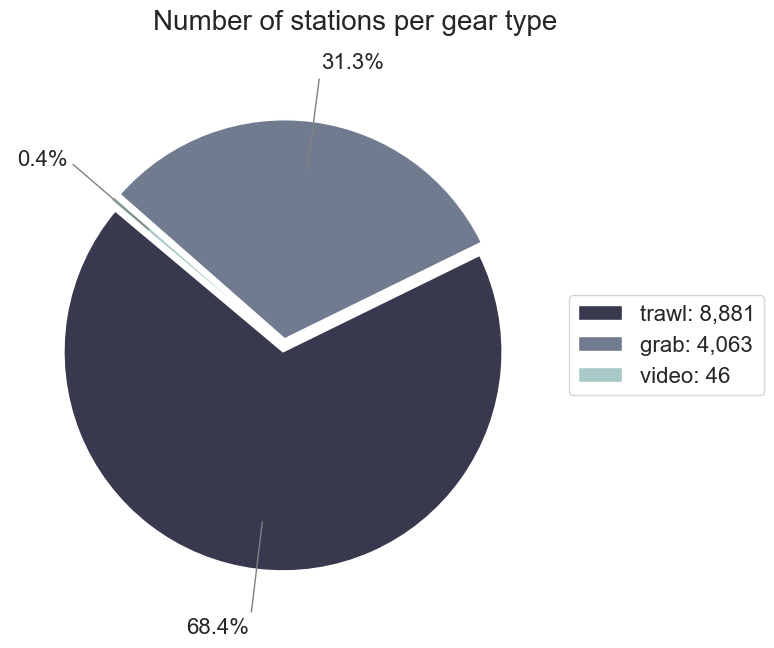

Category
trawl    8881
grab     4063
video      46
Name: DeviceID, dtype: int64


In [122]:
 # ----------------------  FIRST PIE  ----------------------  
df_devgear = pd.read_excel('device_water_with_gear.xlsx', sheet_name='Sheet1', engine='calamine')  
  
dev_col = next((c for c in ['DeviceID','deviceid','deviceId','device_id'] if c in df_devgear.columns), df_devgear.columns[0])  
cat_col = 'Category' if 'Category' in df_devgear.columns else df_devgear.columns[1]  
  
counts_device_cat = (df_devgear.dropna(subset=[dev_col])  
                                .groupby(cat_col)[dev_col]  
                                .nunique()  
                                .reindex(gear_order)           # keeps order consistent  
                                .fillna(0))  
  
explode = [0.03]*len(counts_device_cat)  
colors  = counts_device_cat.index.map(gear2color)  
  
plt.figure(figsize=(8,8))  
wedges,_ = plt.pie(counts_device_cat.values,  
                   labels=[""]*len(counts_device_cat),  
                   startangle=140,  
                   colors=colors,  
                   explode=explode,  
                   wedgeprops=dict(linewidth=1, edgecolor='white'))  
  
total = counts_device_cat.sum()  
for i,w in enumerate(wedges):  
    ang=(w.theta2+w.theta1)/2  
    x,y=np.cos(np.deg2rad(ang)),np.sin(np.deg2rad(ang))  
    ha='left' if x>0 else 'right'  
    pct=counts_device_cat.values[i]/total*100  
    plt.annotate('{:.1f}%'.format(pct),  
                 xy=(x*0.8,y*0.8), xytext=(x*1.3,y*1.3),  
                 ha=ha,va='center',  
                 arrowprops=dict(arrowstyle='-',color='gray',  
                                 connectionstyle='angle,angleA=0,angleB='+str(ang)))  
plt.title('Number of stations per gear type',loc='right',pad=30,fontsize=20)  
plt.legend(wedges,[f'{g}: {int(v):,}' for g,v in counts_device_cat.items()],  
           loc='center left',bbox_to_anchor=(1,0.5))  
plt.tight_layout()  
plt.savefig("station_gear.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()  

# show head of counts
print(counts_device_cat.head())

Nr of unique AphiaId per gear category

In [123]:
# Load source with Category
device_cat_df = pd.read_excel('device_water_with_gear.xlsx', engine='calamine')
cat_lookup = device_cat_df[['DeviceID', 'Category']].drop_duplicates()

# Load biota_water.xlsx
biota_df = pd.read_excel('biota_water.xlsx', engine='calamine')

# Merge on DeviceID
merged_biota = biota_df.merge(cat_lookup, on='DeviceID', how='left')

# Save result
output_file = 'biota_water_with_gear.xlsx'
merged_biota.to_excel(output_file, index=False)

# Show preview
print(merged_biota.head())
print('Merged file saved to ' + output_file)

   CruiseID  StationID  DeviceID  SampleID  SubSampleID  SubsetID  BiotaID  \
0        96        879      1000      1001         1001      1266    33334   
1      1051       9807     10000     10001        10001     10266    77009   
2      1051       9807     10000     10001        10001     10266    77008   
3      1051       9808     10001     10002        10002     10267    77010   
4      1051       9808     10001     10002        10002     10267    77011   

                        Cruise Station Device  ... PresenceAbsence SumWet  \
0                zin_sp22_1980    5600   5600  ...             1.0    NaN   
1  Hydrographic Expeditionffff     903      1  ...             1.0    NaN   
2  Hydrographic Expeditionffff     903      1  ...             1.0    NaN   
3  Hydrographic Expeditionffff     904      1  ...             1.0    NaN   
4  Hydrographic Expeditionffff     904      1  ...             1.0    NaN   

  SumDry  SumAFDW  Stage SieveFraction SubTotalFactor  Specification

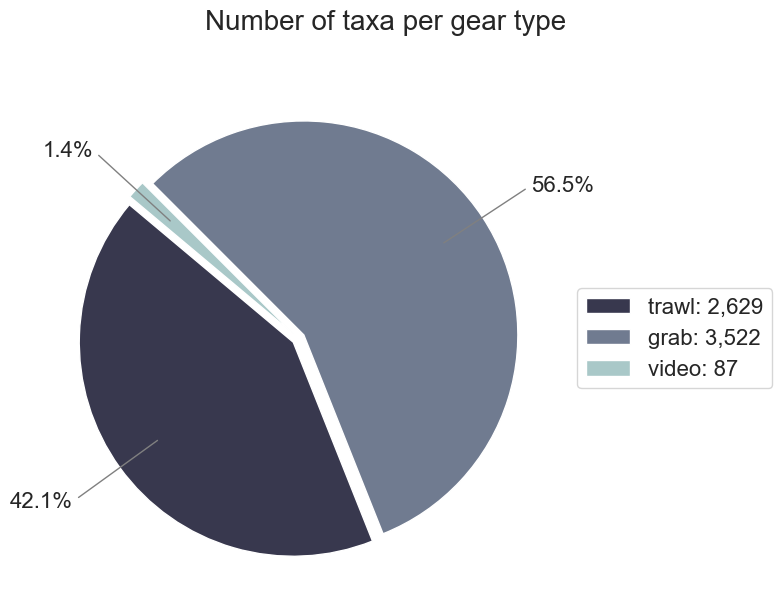

Category
trawl    2629
grab     3522
video      87
Name: AphiaId (Accepted), dtype: int64


In [125]:
df_gear = pd.read_excel('biota_water_with_gear.xlsx', sheet_name='Sheet1', engine='calamine')  
  
aphia_col     = 'AphiaId (Accepted)' if 'AphiaId (Accepted)' in df_gear.columns else df_gear.columns[0]  
category_col  = 'Category' if 'Category' in df_gear.columns else df_gear.columns[1]  
  
counts_cat = (df_gear.dropna(subset=[aphia_col])  
                       .groupby(category_col)[aphia_col]  
                       .nunique()  
                       .reindex(gear_order)  
                       .fillna(0))  
  
explode = [0.03]*len(counts_cat)  
colors  = counts_cat.index.map(gear2color)  
  
plt.figure(figsize=(8,8))  
wedges,_ = plt.pie(counts_cat.values,  
                   labels=[""]*len(counts_cat),  
                   startangle=140,  
                   colors=colors,  
                   explode=explode,  
                   wedgeprops=dict(linewidth=1, edgecolor='white'))  
  
total = counts_cat.sum()  
for i,w in enumerate(wedges):  
    ang=(w.theta2+w.theta1)/2  
    x,y=np.cos(np.deg2rad(ang)),np.sin(np.deg2rad(ang))  
    ha='left' if x>0 else 'right'  
    pct=counts_cat.values[i]/total*100  
    plt.annotate('{:.1f}%'.format(pct),  
                 xy=(x*0.8,y*0.8), xytext=(x*1.3,y*1.3),  
                 ha=ha,va='center',  
                 arrowprops=dict(arrowstyle='-',color='gray',  
                                 connectionstyle='angle,angleA=0,angleB='+str(ang)))  
plt.title('Number of taxa per gear type',loc='right',pad=30,fontsize=20)  
plt.legend(wedges,[f'{g}: {int(v):,}' for g,v in counts_cat.items()],  
           loc='center left',bbox_to_anchor=(1,0.5))  
plt.tight_layout()
plt.savefig("taxa_gear.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

print(counts_cat.head())

# Size categories

### Divide all into megabenthos/macrobenthos/meiobenthos

In [86]:
# List the unique taxonomic coverage categories 
df_dw = pd.read_excel('device_water_with_gear.xlsx', engine='calamine')
unique_tax_cov = sorted(df_dw['TaxonomicCoverage'].dropna().unique())
unique_df = pd.DataFrame({'TaxonomicCoverage': unique_tax_cov})
print(unique_df)

                TaxonomicCoverage
0                         Cumacea
1                      Epibenthos
2                            Fish
3                         Isopoda
4                    Macrobenthos
5   Macrobenthos (no polychaetes)
6     Macrofauna and foraminifera
7                     Megabenthos
8    Megabenthos (no polychaetes)
9                       Meiofauna
10                       Nematoda
11                     Peracarida
12                    Polychaetes
13                            all
14                   macrobenthos


In [87]:
# 1 ▸ Load the original dataset  
file_in  = 'device_water_with_gear.xlsx'          
df = pd.read_excel(file_in)  
  
# 2 ▸ Define the mapping from old labels → new consolidated categories  
mapping = {  
    'Cumacea'                         : 'Macrobenthos',  
    'Epibenthos'                      : 'Megabenthos',  
    'Fish'                            : 'Megabenthos',  
    'Isopoda'                         : 'Macrobenthos',  
    'Macrobenthos (no polychaetes)'   : 'Macrobenthos',  
    'Macrofauna and foraminifera'     : 'Macrobenthos',  
    'Megabenthos (no polychaetes)'    : 'Megabenthos',  
    'Meiofauna'                       : 'Meiobenthos',  
    'Nematoda'                        : 'Meiobenthos',  
    'Peracarida'                      : 'Macrobenthos',  
    'Polychaetes'                     : 'Macrobenthos',  
    'All'                             : 'Uncertain',  
    'all'                             : 'Uncertain',  
    'macrobenthos'                    : 'Macrobenthos'  
}  
  
# 3 ▸ Apply the mapping  
df['TaxonomicCoverage'] = df['TaxonomicCoverage'].replace(mapping)  
  
# 4 ▸ Save the harmonized file  
file_out = 'device_water_with_size.xlsx'  
df.to_excel(file_out, index=False)  
print('Harmonized file written to:', file_out)  
  
# 5 ▸ Display the resulting unique categories for a quick check  
unique_categories = sorted(df['TaxonomicCoverage'].dropna().unique())  
print('New unique TaxonomicCoverage values:', unique_categories)  
  
# (Optional) show as a neat table  
disp.display(pd.DataFrame({'TaxonomicCoverage': unique_categories}))  

Harmonized file written to: device_water_with_size.xlsx
New unique TaxonomicCoverage values: ['Macrobenthos', 'Megabenthos', 'Meiobenthos', 'Uncertain']


,TaxonomicCoverage
0,Macrobenthos
1,Megabenthos
2,Meiobenthos
3,Uncertain


In [88]:
# Enter Megabenthos where gear = trawl and current TaxonomicCoverage entry = Uncertain
# 1 ▸ Load the original size-class file  
file_in  = 'device_water_with_size.xlsx'     # adjust path if needed  
df = pd.read_excel(file_in)  
  
# 2 ▸ Build a mask:  
#     - Gear column contains the substring 'trawl' (case-insensitive)  
#     - TaxonomicCoverage is exactly 'Uncertain'  
mask = df['Gear'].str.contains('trawl', case=True, na=False) & \
       (df['TaxonomicCoverage'] == 'Uncertain')  
  
# 3 ▸ Update those rows  
df.loc[mask, 'TaxonomicCoverage'] = 'Megabenthos'  
  
# 4 ▸ Save to a new file  
file_out = 'device_water_with_size.xlsx'  
df.to_excel(file_out, index=False)  
print('Saved:', file_out)  
  
# 5 ▸ Show a quick before/after sample and the count of fixes  
fixed = df.loc[mask, ['DeviceID', 'Gear', 'TaxonomicCoverage']]  
print('Rows changed:', len(fixed))  
display(fixed.head())  

Saved: device_water_with_size.xlsx
Rows changed: 523


,DeviceID,Gear,TaxonomicCoverage
10864,20745,Beam trawl,Megabenthos
10865,20746,Beam trawl,Megabenthos
10866,20747,Beam trawl,Megabenthos
10867,20748,Beam trawl,Megabenthos
10868,20749,Beam trawl,Megabenthos


Use gear type to infer size class

In [89]:
# List unique gear entries
df_gear = pd.read_excel('device_water_with_gear.xlsx', engine='calamine')
unique_gears = sorted(df_gear['Gear'].dropna().unique())
unique_gear_df = pd.DataFrame({'Gear': unique_gears})
print(unique_gear_df)
print('Total unique gears:', len(unique_gears))

                                       Gear
0                             Agassiz trawl
1                     Agassiz trawl generic
2                              Agassiztrawl
3                                        BC
4             BC (Ocean Instruments BX-650)
5                             Beam Trawl 3m
6                                Beam trawl
7                 Benthic lander (20x20 cm)
8                      Bolshoi drag generic
9                       Box corer (Reineck)
10                            Brenke Sledge
11                           Campelen trawl
12                            CliSAP Sledge
13                                      GKG
14                           Giant box grab
15                       Haps corer generic
16                            Large VV grab
17                                   MC-800
18                                       MG
19                  MUC (6cm core diameter)
20                               Multicorer
21                             O

In [90]:
# Checking whether my manually prepared conversion file has all the necessary gear categories 
# Load device gears
dev_df = pd.read_excel('device_water_with_gear.xlsx', engine='calamine')
dev_gears = set(dev_df['Gear'].dropna().unique())

# Load unique gear list
gear_list_df = pd.read_excel('unique_gear_list.xlsx', engine='calamine')
# Standardize column name
gear_list_df.columns = [c.strip() for c in gear_list_df.columns]
list_gears = set(gear_list_df['Gear'].dropna().unique())

# Identify missing gears
missing_gears = sorted(dev_gears - list_gears)
missing_df = pd.DataFrame({'MissingGear': missing_gears})
print('Total missing gears:', len(missing_gears))

Total missing gears: 0


Update unique_gear_list if necessary

Check the discrepancy between the size class columns and manually go through dataset names, titles and keywords where there are uncertainties

In [91]:
# Load harmonized device data
harm_df = pd.read_excel('device_water_with_size.xlsx', engine='calamine')

# Load gear list with size class info
gear_info_df = pd.read_excel('unique_gear_list.xlsx', engine='calamine')

# Clean column names (strip whitespace)
gear_info_df.columns = [c.strip() for c in gear_info_df.columns]

# Ensure expected column exists
print('Columns in gear info file:', gear_info_df.columns.tolist())

# Merge
merged_df = harm_df.merge(gear_info_df[['Gear', 'Gear-based size class']], on='Gear', how='left')

# Save result
output_file = 'device_water_with_size.xlsx'
merged_df.to_excel(output_file, index=False)

# Preview
print(merged_df.head())
print('Merged dataset saved to ' + output_file)

Columns in gear info file: ['Gear', 'Category', 'Gear-based size class', 'Ecological category']
   CruiseID  StationID  DeviceID        Cruise Station Device  \
0        22        532       633  rusalca_2004      R6      1   
1        22        533       634  rusalca_2004     R10      1   
2        22        534       635  rusalca_2004     R11      1   
3        22        535       636  rusalca_2004     R13      1   
4        22        536       637  rusalca_2004     R15      1   

                      Project TaxonomicResolution TaxonomicCoverage   Realm  \
0  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   
1  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   
2  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   
3  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   
4  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   

   ...   DateStart LatStart LonStart  

In [92]:
# 1 ▸ Load the latest device sheet (with gear size class already merged)  
file_in  = 'device_water_with_size.xlsx' 
df = pd.read_excel(file_in)  
  
# 2 ▸ Keep only rows where TaxonomicCoverage is 'Uncertain'  
#     AND that value does not match the Gear-based size class  
mask = (df['TaxonomicCoverage'] == 'Uncertain') & \
       (df['TaxonomicCoverage'] != df['Gear-based size class'])  
mismatch_df = df.loc[mask]  
  
# 3 ▸ Columns to keep  
cols = ['DeviceID',  
        'Project',  
        'Title',  
        'Keywords',  
        'Gear',  
        'TaxonomicCoverage',  
        'Gear-based size class']  
result_df = mismatch_df[cols]  
  
# 4 ▸ Save to a new Excel file  
file_out = 'device_water_uncertain_size.xlsx'  
result_df.to_excel(file_out, index=False)  
print('Saved:', file_out)  
  
# 5 ▸ Quick sanity-check: show first few rows and the total count  
disp.display(result_df.head())    
print('Total mismatched rows:', len(result_df))

Saved: device_water_uncertain_size.xlsx


,DeviceID,Project,Title,Keywords,Gear,TaxonomicCoverage,Gear-based size class
11271,21152,MAREANO Grab,MAREANO - Base-line mapping of fauna obtained ...,"Baseline studies, Ecological baseline studies,...",Large VV grab,Uncertain,Macrobenthos
11272,21153,MAREANO Grab,MAREANO - Base-line mapping of fauna obtained ...,"Baseline studies, Ecological baseline studies,...",Large VV grab,Uncertain,Macrobenthos
11273,21154,MAREANO Grab,MAREANO - Base-line mapping of fauna obtained ...,"Baseline studies, Ecological baseline studies,...",Large VV grab,Uncertain,Macrobenthos
11274,21155,MAREANO Grab,MAREANO - Base-line mapping of fauna obtained ...,"Baseline studies, Ecological baseline studies,...",Large VV grab,Uncertain,Macrobenthos
11275,21156,MAREANO Grab,MAREANO - Base-line mapping of fauna obtained ...,"Baseline studies, Ecological baseline studies,...",Large VV grab,Uncertain,Macrobenthos


Total mismatched rows: 1315


Manually double check whether the gear-based size class can be used to replace Uncertain. Check against Project, Title, Keywords, Gear and what taxa have been sampled (check this in the Biota sheet). If yes, run the cells below. If no, make manual changes in the unique_gear_list and rerun all cells in this section. 

In [93]:
# Load dataset
df = pd.read_excel('device_water_with_size.xlsx', engine='calamine')

# Create mask for Uncertain entries
mask_uncertain = df['TaxonomicCoverage'] == 'Uncertain'
replacement_count = mask_uncertain.sum()

# Perform replacement using corresponding Gear-based size class values
df.loc[mask_uncertain, 'TaxonomicCoverage'] = df.loc[mask_uncertain, 'Gear-based size class']

# Save updated file
output_file = 'device_water_with_size.xlsx'
df.to_excel(output_file, index=False)

# Preview changed rows
preview = df.loc[mask_uncertain, ['DeviceID', 'Gear', 'Gear-based size class', 'TaxonomicCoverage']].head()
print(preview)
print('Replacements made:', replacement_count)
print('Updated file saved to', output_file)

       DeviceID           Gear Gear-based size class TaxonomicCoverage
11271     21152  Large VV grab          Macrobenthos      Macrobenthos
11272     21153  Large VV grab          Macrobenthos      Macrobenthos
11273     21154  Large VV grab          Macrobenthos      Macrobenthos
11274     21155  Large VV grab          Macrobenthos      Macrobenthos
11275     21156  Large VV grab          Macrobenthos      Macrobenthos
Replacements made: 1315
Updated file saved to device_water_with_size.xlsx


In [94]:
# Display the resulting unique categories for a quick check  
unique_categories = sorted(df['TaxonomicCoverage'].dropna().unique())  
print('Unique TaxonomicCoverage values:', unique_categories)  

Unique TaxonomicCoverage values: ['Macrobenthos', 'Megabenthos', 'Meiobenthos']


### Visualizations of records per size class

In [73]:
# ------------------------------------------------------------------  
# 1) Build ONE shared colour dictionary for all size-classes  
# ------------------------------------------------------------------  
# – Read both files once to see which classes exist in total  
sizes = pd.read_excel('device_water_with_size.xlsx',  
                        sheet_name='Sheet1', engine='calamine')['TaxonomicCoverage'].dropna().unique()  
  
size_order = ['Macrobenthos', 'Megabenthos', 'Meiobenthos']  
base_palette = sns.color_palette('bone', n_colors=len(size_order))  
size2colour = dict(zip(size_order, base_palette))  

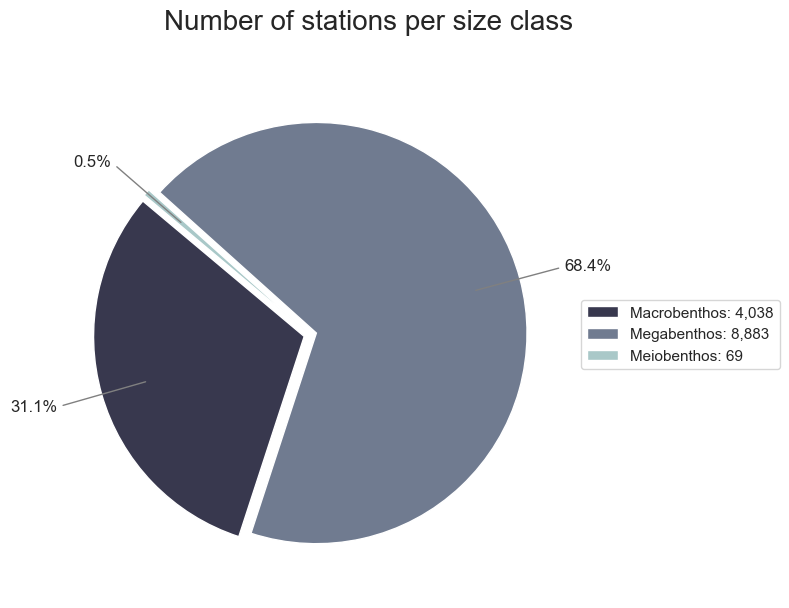

TaxonomicCoverage
Macrobenthos    4038
Megabenthos     8883
Meiobenthos       69
Name: DeviceID, dtype: int64


In [74]:
df_dev = pd.read_excel('device_water_with_size.xlsx', sheet_name='Sheet1', engine='calamine')  
  
device_col  = next((c for c in ['DeviceID','deviceid','deviceId','device_id'] if c in df_dev.columns), df_dev.columns[0])  
cover_col   = 'TaxonomicCoverage' if 'TaxonomicCoverage' in df_dev.columns else df_dev.columns[1]  
  
counts_dev = (df_dev.dropna(subset=[device_col])  
                      .groupby(cover_col)[device_col]  
                      .nunique()  
                      .reindex(size_order)        # keeps order  
                      .fillna(0))  
  
explode = [0.03]*len(counts_dev)  
colours = counts_dev.index.map(size2colour)  
  
plt.figure(figsize=(8,8))  
wedges,_ = plt.pie(counts_dev.values, labels=['']*len(counts_dev), startangle=140,  
                   colors=colours, explode=explode,  
                   wedgeprops={'linewidth':1,'edgecolor':'white'})  
  
total = counts_dev.sum()  
for i,w in enumerate(wedges):  
    ang=(w.theta2+w.theta1)/2  
    x,y=np.cos(np.deg2rad(ang)),np.sin(np.deg2rad(ang))  
    pct=counts_dev.values[i]/total*100  
    ha='left' if x>0 else 'right'  
    plt.annotate('{:.1f}%'.format(pct),  
                 xy=(x*0.8,y*0.8), xytext=(x*1.25,y*1.25),  
                 ha=ha, va='center',  
                 arrowprops=dict(arrowstyle='-',color='gray',  
                                 connectionstyle='angle,angleA=0,angleB='+str(ang)))  
plt.title('Number of stations per size class', loc='right', pad=30, fontsize=20)  
plt.legend(wedges, [f'{s}: {int(v):,}' for s,v in counts_dev.items()],  
           loc='center left', bbox_to_anchor=(1,0.5))  
plt.tight_layout()  
plt.savefig("station_size.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

print(counts_dev.head())

Pie chart instead

Add to Biota sheet

In [96]:
# 1 ▸ Load the two source files  
biota_file   = 'biota_water.xlsx'  
device_file  = 'device_water_with_size.xlsx'  
  
biota_df  = pd.read_excel(biota_file)        # biota records  
device_df = pd.read_excel(device_file)       # devices with final size-class label  
  
# 2 ▸ Clean column names (strip whitespace) – keeps joins robust  
biota_df.columns  = [c.strip() for c in biota_df.columns]  
device_df.columns = [c.strip() for c in device_df.columns]  
  
# 3 ▸ Take only the columns we need from the device sheet  
device_subset = device_df[['DeviceID', 'TaxonomicCoverage']].drop_duplicates()  
  
# 4 ▸ Merge on DeviceID  
merged_df = biota_df.merge(device_subset, on='DeviceID', how='left')  
  
# 5 ▸ Save the enriched biota table  
out_file = 'biota_water_with_size.xlsx'  
merged_df.to_excel(out_file, index=False)  
print('Saved →', out_file)  
  
# 6 ▸ Quick inspection  
disp.display(merged_df.head())           
print('Rows total:', len(merged_df))  
print('TaxonomicCoverage filled:', merged_df["TaxonomicCoverage"].notna().sum())  

Saved → biota_water_with_size.xlsx


,CruiseID,StationID,DeviceID,SampleID,SubSampleID,SubsetID,BiotaID,Cruise,Station,Device,...,PresenceAbsence,SumWet,SumDry,SumAFDW,Stage,SieveFraction,SubTotalFactor,Specification,Remark,TaxonomicCoverage
0,96,879,1000,1001,1001,1266,33334,zin_sp22_1980,5600,5600,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Megabenthos
1,1051,9807,10000,10001,10001,10266,77009,Hydrographic Expeditionffff,903,1,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Macrobenthos
2,1051,9807,10000,10001,10001,10266,77008,Hydrographic Expeditionffff,903,1,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Macrobenthos
3,1051,9808,10001,10002,10002,10267,77010,Hydrographic Expeditionffff,904,1,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Macrobenthos
4,1051,9808,10001,10002,10002,10267,77011,Hydrographic Expeditionffff,904,1,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Macrobenthos


Rows total: 247300
TaxonomicCoverage filled: 247300


In [97]:
# Display the resulting unique categories for a quick check  
unique_categories = sorted(df['TaxonomicCoverage'].dropna().unique())  
print('Unique TaxonomicCoverage values:', unique_categories)  

Unique TaxonomicCoverage values: ['Macrobenthos', 'Megabenthos', 'Meiobenthos']


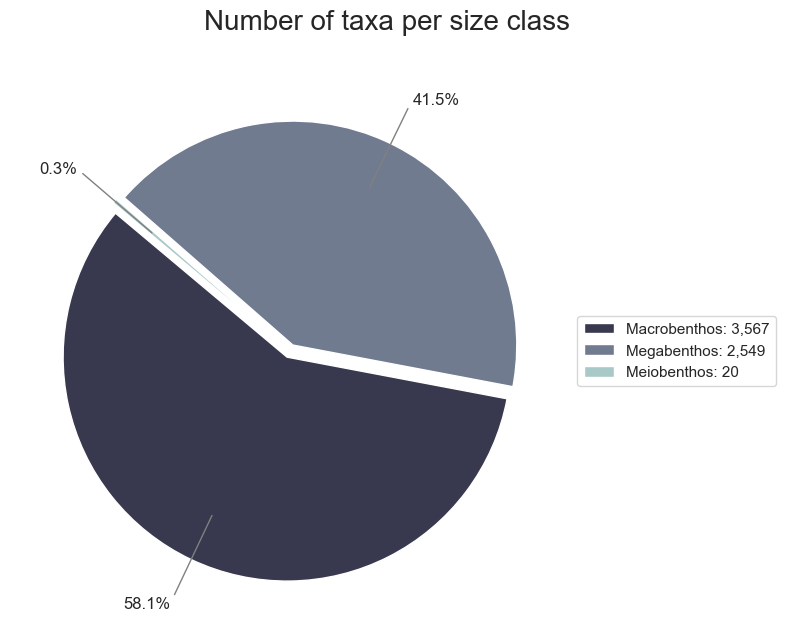

TaxonomicCoverage
Macrobenthos    3567
Megabenthos     2549
Meiobenthos       20
Name: AphiaId (Accepted), dtype: int64


In [75]:
# 2. Load the data  
df = pd.read_excel('biota_water_with_size.xlsx', sheet_name='Sheet1', engine='calamine')  
  
aphia_col   = 'AphiaId (Accepted)' if 'AphiaId (Accepted)' in df.columns else df.columns[0]  
cover_col   = 'TaxonomicCoverage'   if 'TaxonomicCoverage'   in df.columns else df.columns[1]  
  
counts = (df.dropna(subset=[aphia_col])  
            .groupby(cover_col)[aphia_col]  
            .nunique()  
            .reindex(size_order)  
            .fillna(0))  
  
explode = [0.03]*len(counts)  
colours = counts.index.map(size2colour)  
  
plt.figure(figsize=(8,8))  
wedges,_ = plt.pie(counts.values, labels=['']*len(counts), startangle=140,  
                   colors=colours, explode=explode,  
                   wedgeprops={'linewidth':1,'edgecolor':'white'})  
  
total = counts.sum()  
for i,w in enumerate(wedges):  
    ang=(w.theta2+w.theta1)/2  
    x,y=np.cos(np.deg2rad(ang)),np.sin(np.deg2rad(ang))  
    pct=counts.values[i]/total*100  
    ha='left' if x>0 else 'right'  
    plt.annotate('{:.1f}%'.format(pct),  
                 xy=(x*0.8,y*0.8), xytext=(x*1.25,y*1.25),  
                 ha=ha, va='center',  
                 arrowprops=dict(arrowstyle='-',color='gray',  
                                 connectionstyle='angle,angleA=0,angleB='+str(ang)))  
plt.title('Number of taxa per size class', loc='right', pad=30, fontsize=20)  
plt.legend(wedges, [f'{s}: {int(v):,}' for s,v in counts.items()],  
           loc='center left', bbox_to_anchor=(1,0.5))  
plt.tight_layout()  
plt.savefig("taxa_size.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

print(counts.head())

### Visualizations of size class vs LME

Nr of stations and unique AphiaId per size category in the different LME:s

In [99]:
# Add LME to device_water_with_size
# Read all sheets (assuming single sheet in each file) using engine='calamine' for speed
size_df = pd.read_excel('device_water_with_size.xlsx', engine='calamine')
lme_df = pd.read_excel('device_water_with_LME.xlsx', engine='calamine')

# Merge on DeviceID (case-sensitive); ensure column exists in both
merged_df = size_df.merge(lme_df[['DeviceID', 'LME_NAME']], on='DeviceID', how='left')

# Save to new Excel file
output_filename = 'device_water_with_size_LME.xlsx'
merged_df.to_excel(output_filename, index=False)

# Display head of merged dataframe
print(merged_df.head())
print('Merged file saved as:', output_filename)

   CruiseID  StationID  DeviceID        Cruise Station Device  \
0        22        532       633  rusalca_2004      R6      1   
1        22        533       634  rusalca_2004     R10      1   
2        22        534       635  rusalca_2004     R11      1   
3        22        535       636  rusalca_2004     R13      1   
4        22        536       637  rusalca_2004     R15      1   

                      Project TaxonomicResolution TaxonomicCoverage   Realm  \
0  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   
1  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   
2  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   
3  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   
4  Megabenthos Bluhm and Iken             species       Megabenthos  Arctic   

   ... LatStart LonStart ibcao_bathy  elevation_bathy      bathy  \
0  ...    65.68  -168.30  -47.609608              -47 -47.609608  

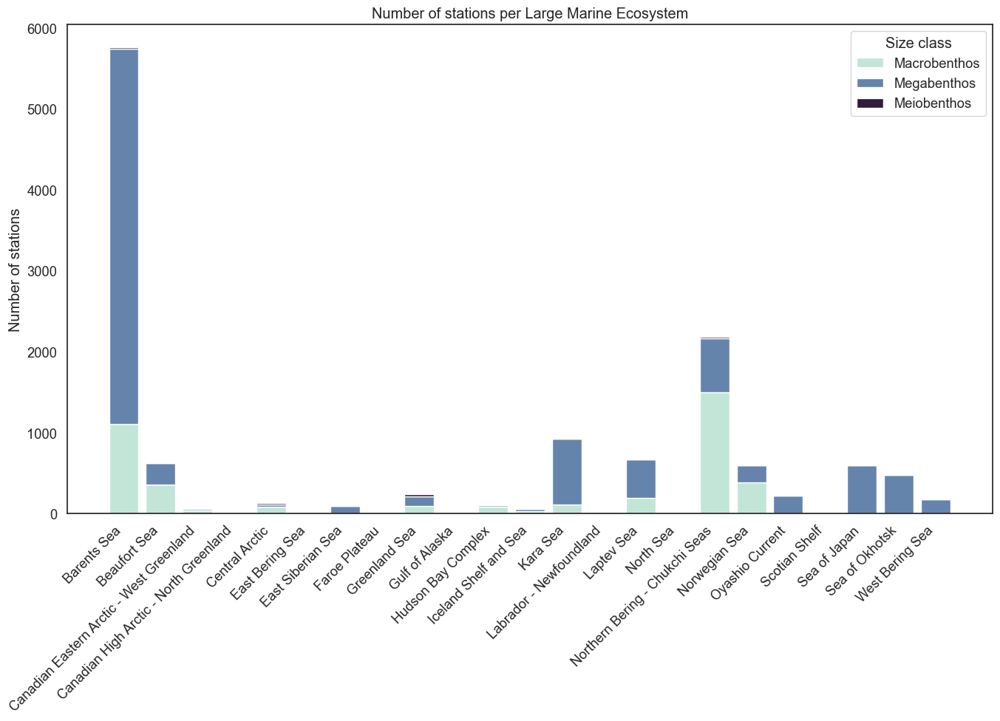

In [100]:
# 1. Load the merged file with LME_NAME  
merged_df = pd.read_excel('device_water_with_size_LME.xlsx')  
  
# 2. Count unique DeviceID by LME and TaxonomicCoverage  
agg_df = (  
    merged_df.groupby(['LME_NAME', 'TaxonomicCoverage'])['DeviceID']  
    .nunique()  
    .reset_index(name='DeviceCount')  
)  
  
# 3. Pivot so each TaxonomicCoverage is its own column  
pivot_df = (  
    agg_df.pivot(index='LME_NAME', columns='TaxonomicCoverage', values='DeviceCount')  
    .fillna(0)  
)  
  
# 4. Build cubehelix colour list  
n_categories = pivot_df.shape[1]  
cmap = sns.cubehelix_palette(start=.5, rot=-.5, as_cmap=True)  
colors = [cmap(x) for x in np.linspace(0, 1, n_categories)]  
  
# 5. Stacked barplot  
fig, ax = plt.subplots(figsize=(14, 10))  
bottom = np.zeros(len(pivot_df))  
for colour, column in zip(colors, pivot_df.columns):  
    ax.bar(pivot_df.index, pivot_df[column], bottom=bottom,  
           label=column, color=colour)  
    bottom += pivot_df[column].values  
  
ax.set_ylabel('Number of stations')  
ax.set_xlabel(None)  
ax.set_title('Number of stations per Large Marine Ecosystem')  
plt.xticks(rotation=45, ha='right')  
ax.legend(title='Size class', loc='upper right')  
plt.tight_layout()  
plt.savefig("station_size_LME.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()  

In [101]:
size_biota_df = pd.read_excel('biota_water_with_size.xlsx', engine='calamine')
lme_biota_df = pd.read_excel('biota_water_with_LME.xlsx', engine='calamine')

merged_biota_df = size_biota_df.merge(lme_biota_df[['DeviceID', 'LME_NAME']], on='DeviceID', how='left')

csv_file = 'biota_water_with_size_LME.csv'
merged_biota_df.to_csv(csv_file, index=False)

print(merged_biota_df.head())
print('Merged file saved as:', csv_file)

   CruiseID  StationID  DeviceID  SampleID  SubSampleID  SubsetID  BiotaID  \
0        96        879      1000      1001         1001      1266    33334   
1      1051       9807     10000     10001        10001     10266    77009   
2      1051       9807     10000     10001        10001     10266    77009   
3      1051       9807     10000     10001        10001     10266    77008   
4      1051       9807     10000     10001        10001     10266    77008   

                        Cruise Station Device  ... SumWet SumDry SumAFDW  \
0                zin_sp22_1980    5600   5600  ...    NaN    NaN     NaN   
1  Hydrographic Expeditionffff     903      1  ...    NaN    NaN     NaN   
2  Hydrographic Expeditionffff     903      1  ...    NaN    NaN     NaN   
3  Hydrographic Expeditionffff     903      1  ...    NaN    NaN     NaN   
4  Hydrographic Expeditionffff     903      1  ...    NaN    NaN     NaN   

   Stage  SieveFraction SubTotalFactor Specification  Remark  \
0    NaN  

In [102]:
csv_path = 'biota_water_with_size_LME.csv' 
  
# 1 ── Identify the accepted AphiaID column name  
sample_cols = pd.read_csv(csv_path, nrows=5, low_memory=False).columns  
aphia_col = [c for c in sample_cols if 'aphiaid' in c.lower() and 'accepted' in c.lower()][0]  
  
# 2 ── Prepare aggregation containers  
use_cols = ['LME_NAME', 'TaxonomicCoverage', aphia_col]  
unique_sets = {}                                  # {(lme, coverage): set_of_ids}  
  
# 3 ── Stream through the big file in 2-million-row chunks  
for chunk in pd.read_csv(csv_path,  
                         usecols=use_cols,  
                         chunksize=2_000_000,  
                         low_memory=False):  
    # remove NAs early  
    chunk = chunk.dropna(subset=[aphia_col, 'LME_NAME', 'TaxonomicCoverage'])  
    for (lme, cov), sub in chunk.groupby(['LME_NAME', 'TaxonomicCoverage']):  
        key = (lme, cov)  
        if key not in unique_sets:  
            unique_sets[key] = set()  
        unique_sets[key].update(sub[aphia_col].unique())  
  
# 4 ── Convert sets → counts → tidy DataFrame  
records = [{'LME_NAME': k[0],  
            'TaxonomicCoverage': k[1],  
            'UniqueAphiaID': len(v)}  
           for k, v in unique_sets.items()]  
agg_df = pd.DataFrame(records)  
  
# 5 ── Reshape for stacked plotting  
pivot_df = (agg_df  
            .pivot(index='LME_NAME',  
                   columns='TaxonomicCoverage',  
                   values='UniqueAphiaID')  
            .fillna(0)  
            .astype(int))  

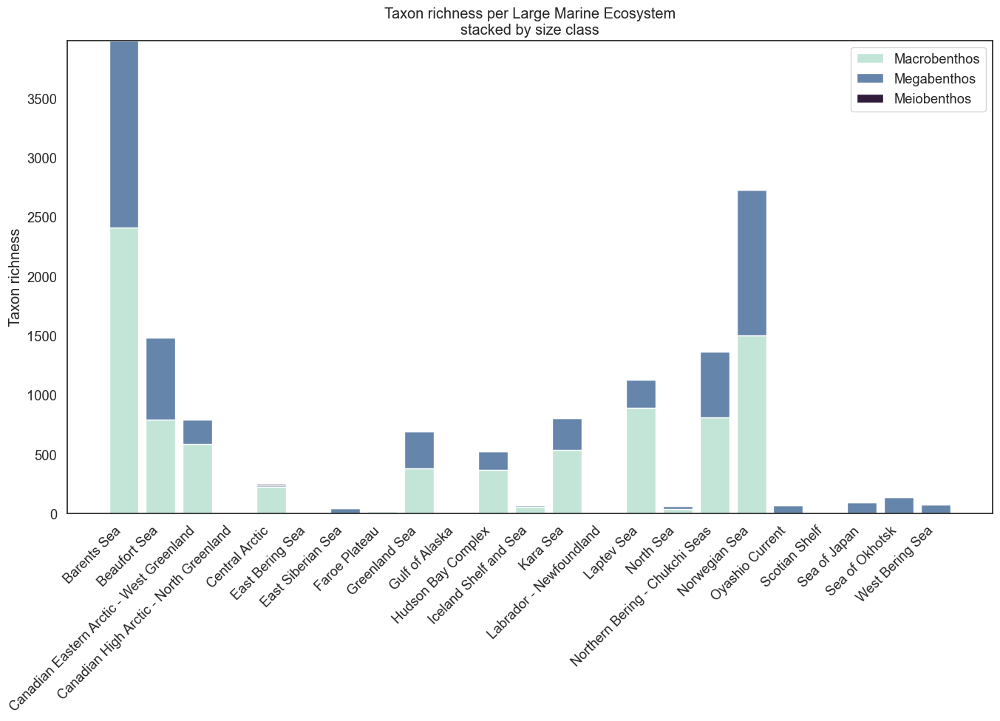

In [103]:
# 6 ── Build the stacked bar-plot  
palette = sns.cubehelix_palette(start=.5, rot=-.5,  
                                n_colors=pivot_df.shape[1])  
fig, ax = plt.subplots(figsize=(14, 10))  
  
bottom = np.zeros(len(pivot_df))  
for colour, col in zip(palette, pivot_df.columns):  
    ax.bar(pivot_df.index,  
           pivot_df[col],  
           bottom=bottom,  
           label=col,  
           color=colour)  
    bottom += pivot_df[col].values  
  
ax.set_ylabel('Taxon richness')  
ax.set_xlabel(None)  
ax.set_title('Taxon richness per Large Marine Ecosystem\nstacked by size class')  
plt.xticks(rotation=45, ha='right')  
ax.legend(title=None,  
          loc='upper right')  
plt.tight_layout()  
plt.savefig("taxa_size_LME.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()  

# Geomorphology 

Manual repair (Repair geometry) of Shelf_Classification shapefile in ArcGIS to get rid of empty ring (coordinate list of size 0 or 1) (only needed once)

### Spatial join with Harris' geomorphological features:  

In [104]:
# helper: drop rings < 4 points and invalid geometries  
def clean_poly(g):  
    if g is None: return None  
    try: g = make_valid(g)  
    except Exception: return None  
    if g.is_empty or not g.is_valid: return None  
    if g.geom_type == "Polygon":  
        return g if len(g.exterior.coords) >= 4 else None  
    if g.geom_type == "MultiPolygon":  
        parts = [p for p in g.geoms if len(p.exterior.coords) >= 4]  
        if not parts: return None  
        return MultiPolygon(parts) if len(parts) > 1 else parts[0]  
    return None  
  
# 1 ▸ device points  
df  = pd.read_excel("device_water_mini.xlsx")  
pts = gpd.GeoDataFrame(  
    df,  
    geometry=[Point(xy) for xy in zip(df["LonStart"], df["LatStart"])],  
    crs="EPSG:4326",  
)  
print("Device rows:", len(pts))  
  
# 2 ▸ shapefiles in Geo/  
shp_dir = pathlib.Path("Geo")  
shps    = sorted(shp_dir.glob("*.shp"))  
print("Found", len(shps), "shapefiles in Geo/")  
  
joined = pts.copy()  
  
for shp in shps:  
    name = shp.stem  
    print("•", name)  
    raw = gpd.read_file(shp)  
    prop_cols = [c for c in raw.columns if c.lower() in ["class", "geomorphic"]]  
  
    # clean layer  
    records = []  
    for _, row in tqdm(raw.iterrows(), total=len(raw), leave=False):  
        geom = clean_poly(row.geometry)  
        if geom is None: continue  
        rec  = {name + "_" + c: row[c] for c in prop_cols}  
        rec["geometry"] = geom  
        records.append(rec)  
  
    if not records:  
        print("  ↳ skipped (no valid polygons)"); continue  
  
    layer = gpd.GeoDataFrame(records, crs=raw.crs).to_crs("EPSG:4326")  
    joined = gpd.sjoin(joined, layer, how="left", predicate="intersects").drop(columns="index_right")  
  
# 3 ▸ reorder columns  
order = [  
    "Hadal", "Abyss", "Slope", "Shelf", "Abyssal_Classification", "Shelf_Classification",  
    "Plateaus", "Terraces", "Trenches", "Rises", "Fans", "Spreading_ridges", "Ridges",  
    "Troughs", "Rift_valleys", "Shelf_valleys", "Glacial_troughs", "Sills",  
    "Bridges", "Seamounts", "Guyots", "Canyons", "Escarpments", "Basins"  
]  
  
# build full ordered list: point columns first, then *_Class/_Geomorphic in order  
base_cols   = [c for c in joined.columns if c not in joined.geometry.name and not any(c.startswith(x + "_") for x in order)]  
ordered_cols = base_cols.copy()  
for feat in order:  
    ordered_cols.extend([c for c in joined.columns if c.startswith(feat + "_")])  
  
joined = joined[ordered_cols + [joined.geometry.name]]  
  
# 4 ▸ save + preview  
out_xlsx = "device_water_geo.xlsx"  
joined.drop(columns="geometry").to_excel(out_xlsx, index=False)  
print("✓ saved to", out_xlsx)  
print(joined.drop(columns='geometry').head())  

Device rows: 12773
Found 24 shapefiles in Geo/
• Abyss


• Abyssal_Classification


• Basins


• Bridges


• Canyons


• Escarpments


... (15 outputs left out)

• Terraces


• Trenches


• Troughs


✓ saved to device_water_geo.xlsx
   DeviceID  LatStart  LonStart Hadal_Geomorphic Abyss_Geomorphic  \
0       633     65.68   -168.30              NaN              NaN   
1       634     66.00   -169.62              NaN              NaN   
2       635     66.93   -170.99              NaN              NaN   
3       636     67.43   -169.64              NaN              NaN   
4       637     67.87   -168.32              NaN              NaN   

  Slope_Geomorphic Shelf_Geomorphic Shelf_Classification_Class  \
0              NaN            Shelf                     medium   
1              NaN            Shelf                     medium   
2              NaN            Shelf                        low   
3              NaN            Shelf                        low   
4              NaN            Shelf                     medium   

  Shelf_Classification_Geomorphic Shelf_valleys_Geomorphic  ...  \
0                           Shelf                      NaN  ...   
1                    

In [105]:
xlsx = 'device_water_geo.xlsx'                 
geo  = pd.read_excel(xlsx, sheet_name='Sheet1')  
display(geo.head())  

,DeviceID,LatStart,LonStart,Hadal_Geomorphic,Abyss_Geomorphic,Slope_Geomorphic,Shelf_Geomorphic,Shelf_Classification_Class,Shelf_Classification_Geomorphic,Shelf_valleys_Geomorphic,...,Rift_valleys_Geomorphic,Shelf_valleys_Geomorphic.1,Glacial_troughs_Geomorphic,Sills_Geomorphic,Bridges_Geomorphic,Seamounts_Geomorphic,Guyots_Geomorphic,Canyons_Geomorphic,Escarpments_Geomorphic,Basins_Geomorphic
0,633,65.68,-168.30,NaN,NaN,NaN,Shelf,medium,Shelf,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,634,66.00,-169.62,NaN,NaN,NaN,Shelf,medium,Shelf,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,635,66.93,-170.99,NaN,NaN,NaN,Shelf,low,Shelf,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,636,67.43,-169.64,NaN,NaN,NaN,Shelf,low,Shelf,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,637,67.87,-168.32,NaN,NaN,NaN,Shelf,medium,Shelf,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Merge into overarching categories

Check unique combinations of geo categories: 

In [106]:
df = pd.read_excel('device_water_geo.xlsx')
# columns D (index 3) to AD (index 29) inclusive
cols = df.columns[3:32]
subset = df[cols]
print('Selected columns:', list(cols))
# drop duplicates keep unique combos
unique_combos = subset.drop_duplicates().reset_index(drop=True)
print('Unique combinations count:', len(unique_combos))
# save to file for download
outfile = 'unique_geo_combinations.xlsx'
unique_combos.to_excel(outfile, index=False)
print('Saved to', outfile)

Selected columns: ['Hadal_Geomorphic', 'Abyss_Geomorphic', 'Slope_Geomorphic', 'Shelf_Geomorphic', 'Shelf_Classification_Class', 'Shelf_Classification_Geomorphic', 'Shelf_valleys_Geomorphic', 'Abyssal_Classification_Class', 'Abyssal_Classification_Geomorphic', 'Shelf_Classification_Class.1', 'Shelf_Classification_Geomorphic.1', 'Plateaus_Geomorphic', 'Terraces_Geomorphic', 'Trenches_Geomorphic', 'Rises_Geomorphic', 'Fans_Geomorphic', 'Spreading_ridges_Geomorphic', 'Ridges_Geomorphic', 'Troughs_Geomorphic', 'Rift_valleys_Geomorphic', 'Shelf_valleys_Geomorphic.1', 'Glacial_troughs_Geomorphic', 'Sills_Geomorphic', 'Bridges_Geomorphic', 'Seamounts_Geomorphic', 'Guyots_Geomorphic', 'Canyons_Geomorphic', 'Escarpments_Geomorphic', 'Basins_Geomorphic']
Unique combinations count: 103
Saved to unique_geo_combinations.xlsx


Spatial join with Yesson's seamounts and knolls (base area)?? Has not been done in this step, should maybe be done in the final version? Files first have to be repaired in ArcGIS 

Merge into 7 main categories

In [16]:
input_file = "device_water_geo.xlsx"   
df_geo = pd.read_excel(input_file)  
  
print("Rows:", len(df_geo))  
df_geo.head()          # quick peek  

# 2. Create the target column and initialize with empty strings  
df_geo["Geo_category"] = ""  

# 3.1  Shelf + high  ➜  Low topography shelf  
mask = (  
    df_geo["Shelf_Geomorphic"].str.contains("Shelf", case=False, na=False)  
    & df_geo["Shelf_Classification_Class"].str.contains("high", case=False, na=False)  
)  
df_geo.loc[mask, "Geo_category"] = "Deep shelf"  
  
# 3.2  Shelf + medium  ➜  Medium topography shelf  
mask = (  
    df_geo["Shelf_Geomorphic"].str.contains("Shelf", case=False, na=False)  
    & df_geo["Shelf_Classification_Class"].str.contains("medium", case=False, na=False)  
    & (df_geo["Geo_category"] == "")  
)  
df_geo.loc[mask, "Geo_category"] = "Medium shelf"  
  
# 3.3  Shelf + low  ➜  High topography shelf  
mask = (  
    df_geo["Shelf_Geomorphic"].str.contains("Shelf", case=False, na=False)  
    & df_geo["Shelf_Classification_Class"].str.contains("low", case=False, na=False)  
    & (df_geo["Geo_category"] == "")  
)  
df_geo.loc[mask, "Geo_category"] = "Shallow shelf"  
  
# 3.4  Slope  ➜  Slope  
mask = (  
    df_geo["Slope_Geomorphic"].str.contains("Slope", case=False, na=False)  
    & (df_geo["Geo_category"] == "")  
)  
df_geo.loc[mask, "Geo_category"] = "Slope"  
  
# 3.5  Ridges_Geomorphic with “Ridge”  ➜  Ridges  
mask = (  
    df_geo["Ridges_Geomorphic"].str.contains("Ridge", case=False, na=False)  
    & (df_geo["Geo_category"] == "")  
)  
df_geo.loc[mask, "Geo_category"] = "Ridges"  
  
# 3.6  Spreading_ridges_Geomorphic with “Spreading Ridge”  ➜  Ridges  
mask = (  
    df_geo["Spreading_ridges_Geomorphic"].str.contains("Spreading Ridge", case=False, na=False)  
    & (df_geo["Geo_category"] == "")  
)  
df_geo.loc[mask, "Geo_category"] = "Ridges"  
  
# 3.7  Rift_valleys_Geomorphic with “Rift Valley”  ➜  Ridges  
mask = (  
    df_geo["Rift_valleys_Geomorphic"].str.contains("Rift Valley", case=False, na=False)  
    & (df_geo["Geo_category"] == "")  
)  
df_geo.loc[mask, "Geo_category"] = "Ridges"  
  
# 3.8  Abyssal_Classification_Class with “Hills” or “Mountains”  ➜  High topography abyss  
mask = (  
    df_geo["Abyssal_Classification_Class"].str.contains("Hills|Mountains", case=False, na=False)  
    & (df_geo["Geo_category"] == "")  
)  
df_geo.loc[mask, "Geo_category"] = "Abyssal mountains and hills"  
  
# 3.9  Seamounts_Geomorphic with “Seamount”  ➜  High topography abyss  
mask = (  
    df_geo["Seamounts_Geomorphic"].str.contains("Seamount", case=False, na=False)  
    & (df_geo["Geo_category"] == "")  
)  
df_geo.loc[mask, "Geo_category"] = "Abyssal mountains and hills"  
  
# 3.10  Abyssal_Classification_Class with “Plains”  ➜  Low topography abyss  
mask = (  
    df_geo["Abyssal_Classification_Class"].str.contains("Plains", case=False, na=False)  
    & (df_geo["Geo_category"] == "")  
)  
df_geo.loc[mask, "Geo_category"] = "Abyssal plains"  
  
# 3.11  Hadal_Geomorphic with “Hadal”  ➜  Low topography abyss  
mask = (  
    df_geo["Hadal_Geomorphic"].str.contains("Hadal", case=False, na=False)  
    & (df_geo["Geo_category"] == "")  
)  
df_geo.loc[mask, "Geo_category"] = "Abyssal plains"  

# Save as excel
output_file = "device_water_geo_collapsed.xlsx"  
df_geo.to_excel(output_file, index=False)  
  
print("Saved new file:", output_file)  

Rows: 12773
Saved new file: device_water_geo_collapsed.xlsx


Visualize cateogorization 

In [17]:
detail_file = "device_water_geo.xlsx"  
df = pd.read_excel(detail_file)  
  
# ───────────────────────────────────────────────  
# Helper to apply a rule and remember it  
# ───────────────────────────────────────────────  
def apply_rule(mask, new_cat, rule_name):  
    """  
    If mask is True *and* Geo_category is still empty,  
    set Geo_category and record which rule fired.  
    """  
    untouched = df["Geo_category"] == ""  
    df.loc[mask & untouched, "Geo_category"] = new_cat  
    df.loc[mask & (df["Geo_category"] == new_cat), "Source_rule"] = rule_name  
    
 # Initialise the two working columns  
df["Geo_category"] = ""  
df["Source_rule"] = ""  

# ───────────────────────────────────────────────  
# All classification rules  
# ───────────────────────────────────────────────  
apply_rule(  
    df["Shelf_Geomorphic"].str.contains("Shelf", case=False, na=False)  
    & df["Shelf_Classification_Class"].str.contains("high", case=False, na=False),  
    "Deep shelf",  
    "Shelf high relief",  
)  
  
apply_rule(  
    df["Shelf_Geomorphic"].str.contains("Shelf", case=False, na=False)  
    & df["Shelf_Classification_Class"].str.contains("medium", case=False, na=False),  
    "Medium shelf",  
    "Shelf medium relief",  
)  
  
apply_rule(  
    df["Shelf_Geomorphic"].str.contains("Shelf", case=False, na=False)  
    & df["Shelf_Classification_Class"].str.contains("low", case=False, na=False),  
    "Shallow shelf",  
    "Shelf low relief",  
)  
  
apply_rule(  
    df["Slope_Geomorphic"].str.contains("Slope", case=False, na=False),  
    "Slope",  
    "Slope",  
)  
  
apply_rule(  
    df["Ridges_Geomorphic"].str.contains("Ridge", case=False, na=False),  
    "Ridges",  
    "Ridges",  
)  
apply_rule(  
    df["Spreading_ridges_Geomorphic"].str.contains("Spreading Ridge", case=False, na=False),  
    "Ridges",  
    "Spreading ridge",  
)  
apply_rule(  
    df["Rift_valleys_Geomorphic"].str.contains("Rift Valley", case=False, na=False),  
    "Ridges",  
    "Rift valley",  
)  
  
apply_rule(  
    df["Abyssal_Classification_Class"].str.contains("Hills|Mountains", case=False, na=False),  
    "Abyssal mountains and hills",  
    "Abyss hills/mountains",  
)  
apply_rule(  
    df["Seamounts_Geomorphic"].str.contains("Seamount", case=False, na=False),  
    "Abyssal mountains and hills",  
    "Seamount",  
)  
  
apply_rule(  
    df["Abyssal_Classification_Class"].str.contains("Plains", case=False, na=False),  
    "Abyssal plains",  
    "Abyss plains",  
)  
apply_rule(  
    df["Hadal_Geomorphic"].str.contains("Hadal", case=False, na=False),  
    "Abyssal plains",  
    "Hadal",  
)  
  
# Anything still blank is unmatched  
df["Geo_category"] = df["Geo_category"].replace("", None)  

# ───────────────────────────────────────────────  
# Summary table  
# ───────────────────────────────────────────────  
summary = (  
    df.groupby(["Geo_category", "Source_rule"])  
      .size()  
      .reset_index(name="Count")  
      .sort_values(["Geo_category", "Count"], ascending=[True, False])  
)  
  
print(summary.head(20))   # head for brevity  

                   Geo_category            Source_rule  Count
0   Abyssal mountains and hills  Abyss hills/mountains    247
1   Abyssal mountains and hills               Seamount      1
2                Abyssal plains           Abyss plains     96
3                Abyssal plains                  Hadal      1
4                    Deep shelf      Shelf high relief   2299
5                  Medium shelf    Shelf medium relief   4800
7                        Ridges            Rift valley     13
6                        Ridges                 Ridges     11
8                        Ridges        Spreading ridge      6
9                 Shallow shelf       Shelf low relief   4252
10                        Slope                  Slope    782


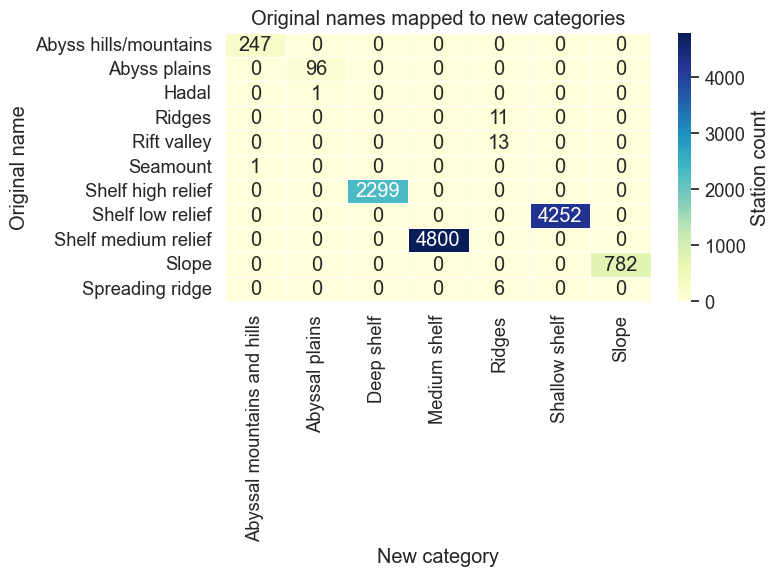

Saved summary to geo_rule_mapping_summary.xlsx


In [18]:
# ───────────────────────────────────────────────  
# Heat-map of rule → overarching category  
# ───────────────────────────────────────────────  
pivot = summary.pivot(index="Source_rule",  
                      columns="Geo_category",  
                      values="Count").fillna(0)  
  
plt.figure(figsize=(8, 6))  
sns.heatmap(  
    pivot,  
    annot=True,  
    fmt="g",  
    cmap="YlGnBu",  
    linewidths=0.5,  
    cbar_kws={"label": "Station count"},  
)  
plt.title("Original names mapped to new categories")  
plt.ylabel("Original name")  
plt.xlabel("New category")  
plt.tight_layout()  
plt.savefig("map_geo_categories.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()  

# ───────────────────────────────────────────────  
# Save the table for reference  
# ───────────────────────────────────────────────  
summary.to_excel("geo_rule_mapping_summary.xlsx", index=False)  
print("Saved summary to geo_rule_mapping_summary.xlsx")  

Delete unnecessary columns: 

In [19]:
# Load existing collapsed file 
input_file = 'device_water_geo_collapsed.xlsx'
df_geo = pd.read_excel(input_file)

# Retain only desired columns
keep_cols = ['DeviceID', 'LatStart', 'LonStart', 'Geo_category']
df_geo = df_geo[keep_cols]

# Save to a new file
output_file = 'device_water_geo_final.xlsx'
df_geo.to_excel(output_file, index=False)

# Show head for confirmation
print(df_geo.head())
print('Saved file as', output_file)

   DeviceID  LatStart  LonStart   Geo_category
0       633     65.68   -168.30   Medium shelf
1       634     66.00   -169.62   Medium shelf
2       635     66.93   -170.99  Shallow shelf
3       636     67.43   -169.64  Shallow shelf
4       637     67.87   -168.32   Medium shelf
Saved file as device_water_geo_final.xlsx


In [20]:
# Calculate nr of rows that are lacking a geo category

df = pd.read_excel('device_water_geo_final.xlsx')

missing_mask = df['Geo_category'].isna() | (df['Geo_category'].str.strip() == '')
missing_count = missing_mask.sum()
print('Missing rows count:', missing_count)

Missing rows count: 265


Inspect in ArcGIS.  
Missing values: points that are on/too close to land to be included in the Harris polygons

### Visualizations

                        Geo_category  DeviceID_count
6                      Shallow shelf            4252
3                       Medium shelf            4800
2                         Deep shelf            2299
7                              Slope             782
5                             Ridges              30
0        Abyssal mountains and hills             248
1                     Abyssal plains              97
4  Outside geomorphological coverage             265


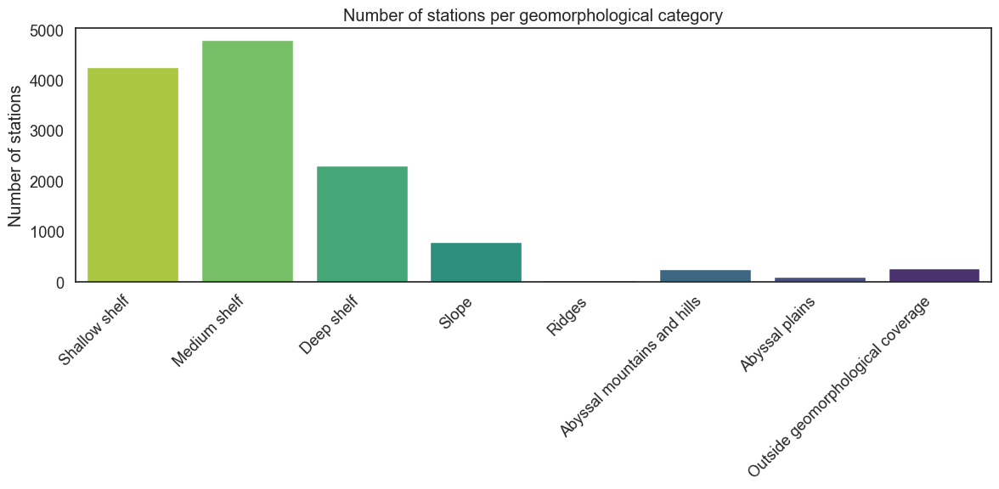

In [26]:
# Load merged data
merged_df = pd.read_excel('device_water_geo_final.xlsx')

# Fill missing category label
merged_df['Geo_category'] = merged_df['Geo_category'].fillna('Outside geomorphological coverage')

# Count unique DeviceID per category
count_df = (
    merged_df.groupby('Geo_category')['DeviceID']
    .nunique()
    .reset_index()
)
count_df.columns = ['Geo_category', 'DeviceID_count']

# Desired order
order = [
    'Shallow shelf',
    'Medium shelf',
    'Deep shelf',
    'Slope',
    'Ridges',
    'Abyssal mountains and hills',
    'Abyssal plains',
    'Outside geomorphological coverage'
]

# Apply categorical ordering then sort
count_df['Geo_category'] = pd.Categorical(count_df['Geo_category'], categories=order, ordered=True)
ordered_df = count_df.sort_values('Geo_category')

print(ordered_df)

# Plot
plt.figure(figsize=(12,6))
clr = sns.color_palette('viridis_r', n_colors=len(order))

sns.barplot(
    data=ordered_df,
    x='Geo_category',
    y='DeviceID_count',
    hue='Geo_category',
    legend=False,
    palette=clr
)
plt.xticks(rotation=45, ha='right')
plt.ylabel('Number of stations')
plt.xlabel(None)
plt.title('Number of stations per geomorphological category')
plt.tight_layout()
plt.savefig("stations_geo.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

In [22]:
# Add Geo_category column to biota_water_mini

# Load datasets
biota_mini = pd.read_excel('biota_water_mini.xlsx')
geo_final = pd.read_excel('device_water_geo_final.xlsx')

# Perform left merge to keep all biota rows
merged = biota_mini.merge(geo_final[['DeviceID', 'Geo_category']], on='DeviceID', how='left')

# Quick summary of missing categories
missing_geo = merged['Geo_category'].isna().sum()

# Show first few rows
print('Preview of merged data:')
print(merged.head())
print('Number of rows lacking Geo_category:', missing_geo)

# Save merged file
output_file = 'biota_water_geo.xlsx'
merged.to_excel(output_file, index=False)
print('Saved merged file as', output_file)

Preview of merged data:
   DeviceID  SampleID  SubSampleID  SubsetID  BiotaID  AphiaId (Accepted)  \
0      1000      1001         1001      1266    33334            123815.0   
1     10000     10001        10001     10266    77009            110470.0   
2     10000     10001        10001     10266    77008            110524.0   
3     10001     10002        10002     10267    77010            110478.0   
4     10001     10002        10002     10267    77011            139015.0   

           ScientificName (Accepted)   Geo_category  
0                  Urasterias lincki  Shallow shelf  
1             Brachydiastylis resima  Shallow shelf  
2               Eudorella emarginata  Shallow shelf  
3                   Diastylis glabra  Shallow shelf  
4  Serripes (Serripes) groenlandicus  Shallow shelf  
Number of rows lacking Geo_category: 1789
Saved merged file as biota_water_geo.xlsx


Total taxa per geo category

                        Geo_category  Unique_AphiaId_count
6                      Shallow shelf                  2459
3                       Medium shelf                  3160
2                         Deep shelf                  2726
7                              Slope                  2059
5                             Ridges                   109
0        Abyssal mountains and hills                   567
1                     Abyssal plains                   377
4  Outside geomorphological coverage                   369


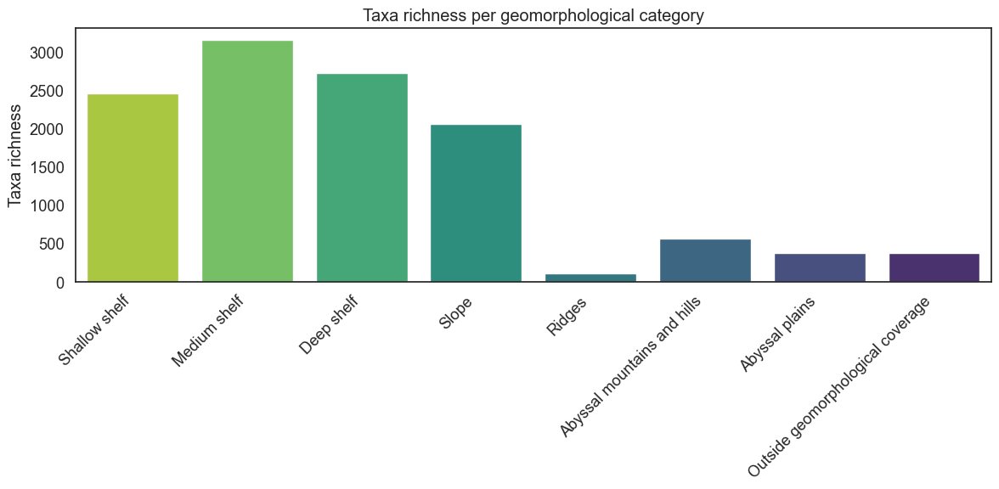

In [27]:
# Load merged data
merged_df = pd.read_excel('biota_water_geo.xlsx')

# Fill missing category label
merged_df['Geo_category'] = merged_df['Geo_category'].fillna('Outside geomorphological coverage')

# Count unique AphiaId per category
count_df = (
    merged_df.groupby('Geo_category')['AphiaId (Accepted)']
    .nunique()
    .reset_index()
)
count_df.columns = ['Geo_category', 'Unique_AphiaId_count']

# Desired order
order = [
    'Shallow shelf',
    'Medium shelf',
    'Deep shelf',
    'Slope',
    'Ridges',
    'Abyssal mountains and hills',
    'Abyssal plains',
    'Outside geomorphological coverage'
]

# Apply categorical ordering then sort
count_df['Geo_category'] = pd.Categorical(count_df['Geo_category'], categories=order, ordered=True)
ordered_df = count_df.sort_values('Geo_category')

print(ordered_df)

# Plot
plt.figure(figsize=(12,6))
clr = sns.color_palette('viridis_r', n_colors=len(order))

sns.barplot(
    data=ordered_df,
    x='Geo_category',
    y='Unique_AphiaId_count',
    hue='Geo_category',
    legend=False,
    palette=clr
)
plt.xticks(rotation=45, ha='right')
plt.ylabel('Taxa richness')
plt.xlabel(None)
plt.title('Taxa richness per geomorphological category')
plt.tight_layout()
plt.savefig("taxa_geo.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

Mean nr of taxa per geo category

                        Geo_category  Mean_unique_AphiaId_per_device
6                      Shallow shelf                       20.941910
3                       Medium shelf                       15.124167
2                         Deep shelf                       17.602001
7                              Slope                       24.566496
5                             Ridges                       16.100000
0        Abyssal mountains and hills                       10.520161
1                     Abyssal plains                       13.927835
4  Outside geomorphological coverage                        2.995851


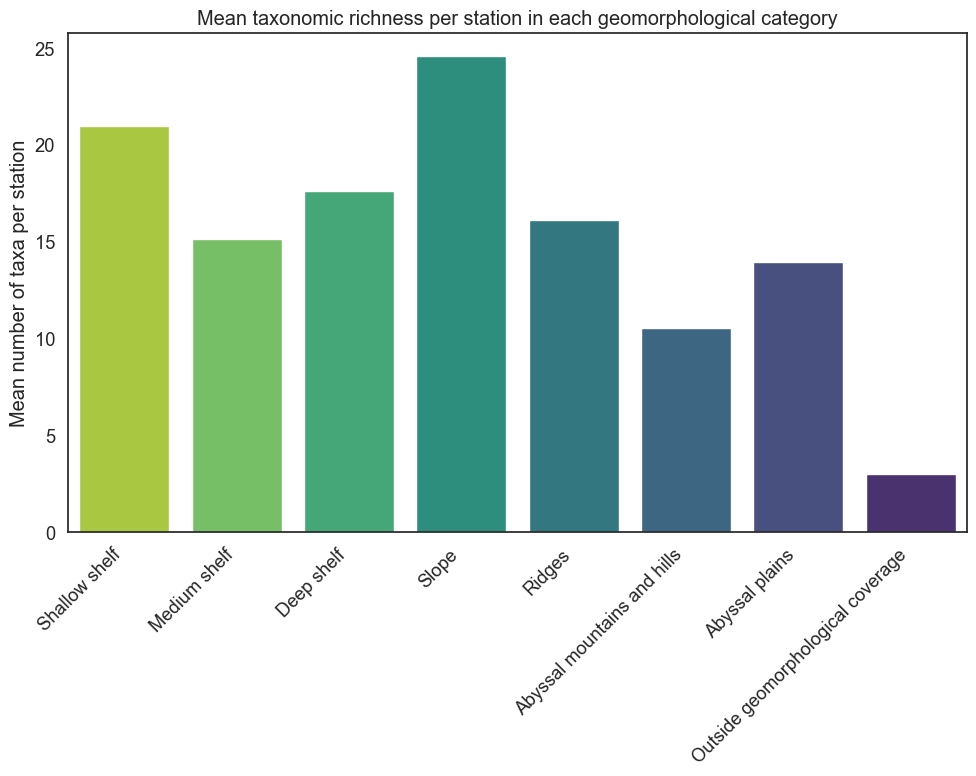

In [28]:
# Load merged mini with geo
df = pd.read_excel('biota_water_geo.xlsx')

# Fill NaN Geo_category
df['Geo_category'] = df['Geo_category'].fillna('Outside geomorphological coverage')

# Desired order
order = [
    'Shallow shelf',
    'Medium shelf',
    'Deep shelf',
    'Slope',
    'Ridges',
    'Abyssal mountains and hills',
    'Abyssal plains',
    'Outside geomorphological coverage'
]
# Count unique AphiaId per DeviceID
per_device = df.groupby(['Geo_category','DeviceID'])['AphiaId (Accepted)'].nunique().reset_index(name='Unique_AphiaId_per_device')

# Mean per Geo_category
mean_counts = per_device.groupby('Geo_category')['Unique_AphiaId_per_device'].mean().reset_index()
mean_counts.columns = ['Geo_category','Mean_unique_AphiaId_per_device']

# Apply order
mean_counts['Geo_category'] = pd.Categorical(mean_counts['Geo_category'], categories=order, ordered=True)
mean_counts = mean_counts.sort_values('Geo_category')

print(mean_counts)

# Barplot
plt.figure(figsize=(10,8))
colors = sns.color_palette('viridis_r', n_colors=len(order))
sns.barplot(data=mean_counts, x='Geo_category', y='Mean_unique_AphiaId_per_device', hue='Geo_category', palette=colors, legend=False)
plt.xticks(rotation=45, ha='right')
plt.ylabel('Mean number of taxa per station')
plt.xlabel(None)
plt.title('Mean taxonomic richness per station in each geomorphological category')
plt.tight_layout()
plt.savefig("mean_taxa_geo.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

## Comparison with Ramirez Llodra

In [4]:
ram_df = pd.read_excel('ramirezllodra.xlsx')
orig_station = pd.read_excel('device_water_mini.xlsx')

In [5]:
# What it does:
# - Coerces coordinate columns to numeric
# - Drops rows with missing coordinates
# - Uses a quick degree-window prefilter, then precise haversine distance
# - Flags coincident points within 100 meters
# - Shows counts and a small preview

# Ensure numeric and drop missing
ram = ram_df.copy()
ram['decimalLat'] = pd.to_numeric(ram['decimalLat'], errors='coerce')
ram['decimalLon'] = pd.to_numeric(ram['decimalLon'], errors='coerce')
ram = ram.dropna(subset=['decimalLat','decimalLon']).reset_index(drop=True)

orig = orig_station.copy()
orig['LatStart'] = pd.to_numeric(orig['LatStart'], errors='coerce')
orig['LonStart'] = pd.to_numeric(orig['LonStart'], errors='coerce')
orig = orig.dropna(subset=['LatStart','LonStart']).reset_index(drop=True)

# Pre-filter tolerance in degrees (~111 m per 0.001 degree near equator; good as a short-listing filter)
lat_tol = 0.001
lon_tol = 0.001

ram_lat = ram['decimalLat'].to_numpy()
ram_lon = ram['decimalLon'].to_numpy()
orig_lat = orig['LatStart'].to_numpy()
orig_lon = orig['LonStart'].to_numpy()

def haversine_m(lat1, lon1, lat2, lon2):
    R = 6371000.0
    dlat = np.radians(lat2 - lat1)
    dlon = np.radians(lon2 - lon1)
    a = np.sin(dlat/2.0)**2 + np.cos(np.radians(lat1)) * np.cos(np.radians(lat2)) * np.sin(dlon/2.0)**2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1-a))
    return R * c

coincide_flags = []
nearest_dist_m = []
for i in range(len(ram)):
    lat = ram_lat[i]
    lon = ram_lon[i]
    cand = (np.abs(orig_lat - lat) <= lat_tol) & (np.abs(orig_lon - lon) <= lon_tol)
    if not np.any(cand):
        coincide_flags.append(False)
        nearest_dist_m.append(float('inf'))
        continue
    dists = haversine_m(lat, lon, orig_lat[cand], orig_lon[cand])
    dmin = float(dists.min()) if dists.size > 0 else float('inf')
    nearest_dist_m.append(dmin)
    coincide_flags.append(dmin <= 100.0)

ram['nearest_station_dist_m'] = nearest_dist_m
ram['coincides_100m'] = coincide_flags

n_total = len(ram)
n_coincide = int(ram['coincides_100m'].sum())
n_noncoincide = int(n_total - n_coincide)

print(n_total)
print(n_coincide)
print(n_noncoincide)
print(ram[['decimalLat','decimalLon','nearest_station_dist_m','coincides_100m']].head())
print('Computed 100 m coincidence')

75404
10101
65303
   decimalLat  decimalLon  nearest_station_dist_m  coincides_100m
0   66.420000  -25.840000                     inf           False
1   67.600000  -22.390000                     inf           False
2   66.267887    6.288088                0.856752            True
3   70.676700 -141.720000                     inf           False
4   70.850000 -141.613000                     inf           False
Computed 100 m coincidence


In [6]:
# What it does:
# - Saves detailed per-record results
# - Creates and saves separate files for coincident and non-coincident subsets
# - Prints summaries and heads for quick verification

# Save detailed results for every Ramirez-Llodra row with coords
ram[['decimalLat','decimalLon','nearest_station_dist_m','coincides_100m']].to_csv('ramirezllodra_vs_original_100m.csv', index=False)

coincident = ram[ram['coincides_100m'] == True].copy()
noncoincident = ram[ram['coincides_100m'] == False].copy()

summary_counts = pd.DataFrame({
    'metric': ['total_ramirezllodra','coincide_within_100m','do_not_coincide_within_100m'],
    'value': [len(ram), len(coincident), len(noncoincident)]
})

summary_counts.to_csv('ramirezllodra_100m_counts_summary.csv', index=False)
coincident.to_csv('ramirezllodra_coincident_within_100m.csv', index=False)
noncoincident.to_csv('ramirezllodra_noncoincident_over_100m.csv', index=False)

print(summary_counts)
print(coincident[['decimalLat','decimalLon','nearest_station_dist_m','coincides_100m']].head())
print(noncoincident[['decimalLat','decimalLon','nearest_station_dist_m','coincides_100m']].head())
print('Saved summary and subsets')

                        metric  value
0          total_ramirezllodra  75404
1         coincide_within_100m  10101
2  do_not_coincide_within_100m  65303
    decimalLat  decimalLon  nearest_station_dist_m  coincides_100m
2    66.267887    6.288088                0.856752            True
25   68.288000   10.705000               13.986104            True
26   67.335000    8.647000               18.903138            True
27   67.595000    9.308000               33.472735            True
29   67.560000    8.584000               40.982773            True
   decimalLat  decimalLon  nearest_station_dist_m  coincides_100m
0     66.4200     -25.840                     inf           False
1     67.6000     -22.390                     inf           False
3     70.6767    -141.720                     inf           False
4     70.8500    -141.613                     inf           False
5     70.8800    -141.770                     inf           False
Saved summary and subsets


# Manuscript plots

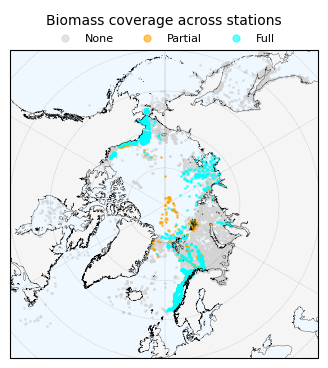

In [50]:
#| label: fig-map_biomass
#| fig-cap: "Biomass coverage among stations. "
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import os
# Ensure shapefile can be read even if .shx is missing
os.environ['SHAPE_RESTORE_SHX'] = 'YES'
# Load the data from device_water_with_biomass.xlsx
FILEPATH = 'device_water_with_biomass.xlsx'
df_station = pd.read_excel(FILEPATH, sheet_name='Sheet1')
# Replace blank cells in the 'Biomass coverage' column with 'none'
df_station['Biomass coverage'] = df_station['Biomass coverage'].fillna('none')
# Use LatStart and LonStart for coordinates
lat = df_station['LatStart'].copy()
lon = df_station['LonStart'].copy()
# Extract the Biomass coverage column
biomass_coverage = df_station['Biomass coverage'].copy()
# Create coordinates dataframe with Biomass coverage
coords = pd.DataFrame({
    'lat': pd.to_numeric(lat, errors='coerce'),
    'lon': pd.to_numeric(lon, errors='coerce'),
    'biomass_coverage': biomass_coverage
})
coords = coords.dropna()
# Filter to plausible lat/lon ranges
coords = coords[(coords['lat'] >= -90) & (coords['lat'] <= 90) &
                (coords['lon'] >= -180) & (coords['lon'] <= 180)]
# Define colors for each biomass coverage category
coverage_colors = {
    'full': 'aqua',
    'partial': 'orange',
    'none': 'lightgray'  # 'none' represents blank cells (formerly 'null')
}
# Map the colors to the Biomass coverage column
coords['color'] = coords['biomass_coverage'].map(coverage_colors)
# Define the drawing order (none -> partial -> full)
drawing_order = ['none', 'partial', 'full']
# Create the plot with smaller figure size
plt.figure(figsize=(4, 4))
proj = ccrs.NorthPolarStereo()
ax = plt.axes(projection=proj)
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor='whitesmoke')
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')
ax.coastlines(resolution='10m', linewidth=0.2, color='black')
ax.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')
# Plot the station points in the specified order
for coverage_type in drawing_order:
    subset = coords[coords['biomass_coverage'] == coverage_type]
    ax.scatter(subset['lon'].values, subset['lat'].values,
               s=1, color=coverage_colors[coverage_type], alpha=0.6,
               label=coverage_type.capitalize(),  # Capitalize the label
               transform=ccrs.PlateCarree())
# Add a legend
plt.legend(
    loc='upper center', 
    bbox_to_anchor=(0.5, 1.15),  # Move the legend outside the map frame
    title='Biomass coverage across stations', 
    fontsize=8, 
    ncol=3, 
    scatterpoints=1,  # Number of points in the legend marker
    markerscale=5,  # Scale factor for the size of the markers in the legend
    frameon=False
)

# Save and show the plot
plt.savefig("biomass_stations.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

In [40]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
# Load data
biota_df = pd.read_excel("biota_water.xlsx")
# Verify calculations and annotations
total_obs = len(biota_df)
with_wet = int(biota_df["SumWet"].notna().sum())
without_wet = int(total_obs - with_wet)
# Data for the plot
labels = ["Full", "None"]
counts_cat = [with_wet, without_wet]
colors = ["aqua", "lightgray"]


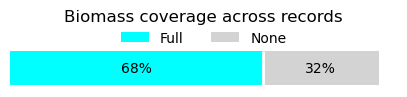

In [41]:
# Plot
plt.figure(figsize=(5, 2))  # Adjust the figure size
# Stacked horizontal bar
left_val = 0.0
for i, count in enumerate(counts_cat):
    # Draw each segment of the bar
    plt.barh(
        [0],  # Single bar at y=0
        [count],  # Bar width
        left=left_val,  # Start position of the bar
        color=colors[i],  # Color for the category
        edgecolor='none',  # No edge color
        linewidth=0,  # No border
    )
    # Add annotations (percentages)
    total_n = sum(counts_cat)
    pct = 0 if total_n == 0 else count / total_n * 100.0
    x_mid = left_val + count / 2.0  # Midpoint of the current segment
    plt.text(
        x_mid,
        0,  # Centered at y=0
        f'{pct:.0f}%',  # Percentage value
        ha='center',
        va='center',
        color='black',
        fontsize=10,
    )
    left_val += count  # Update the starting position for the next bar
# Small white gaps between segments
gap_left = 0.0
for count in counts_cat[:-1]:
    gap_left += count
    plt.vlines(gap_left, -0.4, 0.4, colors='white', linewidth=2)
# Style
plt.xticks([])  # Remove x-axis ticks and labels
plt.yticks([])  # Remove y-axis ticks
plt.title('Biomass coverage across records', pad=20, fontsize=12)  # Add a title with padding
plt.box(False)  # Remove the surrounding box
plt.grid(False)  # Ensure no gridlines are displayed
# Legend centered below the bar
legend_handles = [Patch(facecolor=colors[i], edgecolor='none', label=labels[i]) for i in range(len(labels))]
plt.legend(
    handles=legend_handles,
    loc='upper center',  # Position the legend at the top center
    bbox_to_anchor=(0.5, 1.8),  # Adjust the position (x, y) relative to the axes
    ncol=2,  # Number of columns in the legend
    frameon=False,  # Remove the legend box
    fontsize=10,
)
# Adjust spacing manually to prevent bar stretching
plt.subplots_adjust(top=0.3)  # Adjust the top margin to make space for the legend and title
plt.savefig('biomass_records.png', dpi=300, bbox_inches='tight', facecolor="white")
# Show the plot
plt.show()

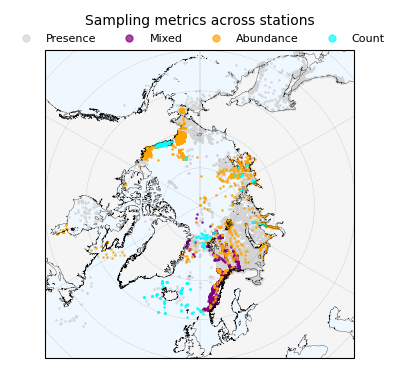

In [21]:
# Minimal polar map using device_water_with_metric.xlsx

import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Load
df = pd.read_excel('device_water_with_metric.xlsx')

# Normalize categories
df['metric_type_norm'] = df['metric_type'].astype(str).str.strip().str.lower()
map_to_cat = {
    'presenceabsence': 'presence',
    'presence_absence': 'presence',
    'presence': 'presence',
    'count': 'count',
    'abundance': 'abundance',
    'mixed': 'mixed'
}
df['metric_category'] = df['metric_type_norm'].map(map_to_cat).fillna('other')

# Coords filter
coords = df.rename(columns={'LatStart':'lat','LonStart':'lon'})[['lat','lon','metric_category']].dropna()
coords = coords[(coords['lat']>=-90)&(coords['lat']<=90)&(coords['lon']>=-180)&(coords['lon']<=180)]

# Plot
colors = {'presence':'lightgray','count':'aqua','abundance':'orange','mixed':'purple','other':'lightgray'}
draw_order = ['presence','mixed','abundance','count']

plt.figure(figsize=(4,4))
ax = plt.axes(projection=ccrs.NorthPolarStereo())
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor='whitesmoke')
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')
ax.coastlines(resolution='10m', linewidth=0.2, color='black')
ax.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')

for cat in draw_order:
    sub = coords[coords['metric_category']==cat]
    if len(sub)==0:
        continue
    ax.scatter(sub['lon'].values, sub['lat'].values, s=1,
               color=colors.get(cat,'lightgray'), alpha=0.7,
               label=cat.capitalize(), transform=ccrs.PlateCarree())

# Adjust legend position
plt.legend(
    loc='upper center',  # Position the legend at the top center
    bbox_to_anchor=(0.5, 1.15),  # Move the legend outside the map frame
    title='Sampling metrics across stations',
    fontsize=8,
    ncol=4,
    scatterpoints=1,
    markerscale=5,
    frameon=False
)

out_file = 'map_metrics.png'
plt.savefig(out_file, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

In [22]:
# Cell 1 — Load data and prepare percentages
import pandas as pd
# Load the Excel
biota_df = pd.read_excel('biota_water.xlsx', sheet_name=0)
# Rename PresenceAbsence -> Presence
rename_map = {}
for c in biota_df.columns:
    if str(c).strip().lower() == 'presenceabsence':
        rename_map[c] = 'Presence'
biota_df = biota_df.rename(columns=rename_map)
# Ensure numeric for metrics
for mcol in ['Count', 'Abundance', 'Presence']:
    if mcol in biota_df.columns:
        biota_df[mcol] = pd.to_numeric(biota_df[mcol], errors='coerce')
# Compute percentage of records where each metric is present (> 0)
n_rows = len(biota_df)
def pct_present(series):
    return float((series.fillna(0).astype(float) > 0).sum()) / float(n_rows) * 100.0 if n_rows > 0 else 0.0
pct_presence = pct_present(biota_df['Presence']) if 'Presence' in biota_df.columns else 0.0
pct_count = pct_present(biota_df['Count']) if 'Count' in biota_df.columns else 0.0
pct_abundance = pct_present(biota_df['Abundance']) if 'Abundance' in biota_df.columns else 0.0
plot_df = pd.DataFrame({
    'Metric': ['Presence', 'Count', 'Abundance'],
    'Percent': [pct_presence, pct_count, pct_abundance]
})
print(plot_df.head())

      Metric    Percent
0   Presence  27.074404
1      Count   5.517186
2  Abundance  67.376870


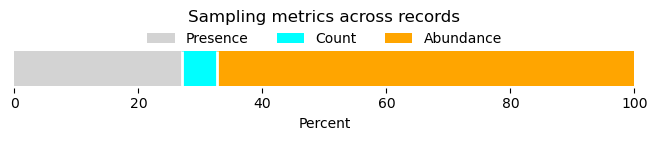

In [32]:
# Cell 2 — Plot stacked horizontal bar with legend below
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
order = ['Presence', 'Count', 'Abundance']
color_map = {'Presence': 'lightgray', 'Count': 'aqua', 'Abundance': 'orange'}
plt.figure(figsize=(8, 2))
# Stacked horizontal bar
left_val = 0.0
for m in order:
    val = float(plot_df.loc[plot_df['Metric'] == m, 'Percent'].values[0]) if m in list(plot_df['Metric']) else 0.0
    plt.barh([0], [val], left=left_val, color=color_map[m], edgecolor='none', linewidth=0)
    left_val += val
# Small white gaps between segments
gap_left = 0.0
for m in order[:-1]:
    gap_left += float(plot_df.loc[plot_df['Metric'] == m, 'Percent'].values[0])
    plt.vlines(gap_left, -0.4, 0.4, colors='white', linewidth=2)
# Style
plt.xlim(0, 100)
plt.yticks([])
plt.xlabel('Percent')
plt.title('Sampling metrics across records', pad=20)
plt.box(False)

# Legend centered below the bar
legend_handles = [Patch(facecolor=color_map[m], edgecolor='none', label=m) for m in order]
plt.legend(
    handles=legend_handles,
    loc='upper center',  # Position the legend at the top center
    bbox_to_anchor=(0.5, 1.8),  # Adjust the position (x, y) relative to the axes
    ncol=3,  # Number of columns in the legend
    frameon=False  # Remove the legend boxplt.tight_layout()
)
# Adjust spacing manually to prevent bar stretching
plt.subplots_adjust(top=0.3)  # Adjust the top
plt.savefig('metrics_records2.png', dpi=300, bbox_inches='tight', facecolor="white")
plt.show()

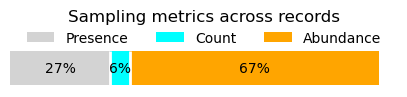

In [37]:
# Cell 2 — Plot stacked horizontal bar with legend below
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
order = ['Presence', 'Count', 'Abundance']
color_map = {'Presence': 'lightgray', 'Count': 'aqua', 'Abundance': 'orange'}
plt.figure(figsize=(5, 2))
# Stacked horizontal bar
left_val = 0.0
for m in order:
    val = float(plot_df.loc[plot_df['Metric'] == m, 'Percent'].values[0]) if m in list(plot_df['Metric']) else 0.0
    plt.barh([0], [val], left=left_val, color=color_map[m], edgecolor='none', linewidth=0)
    plt.text(left_val + val / 2, 0, f'{val:.0f}%', ha='center', va='center', color='black', fontsize=10)
    left_val += val
# Small white gaps between segments
gap_left = 0.0
for m in order[:-1]:
    gap_left += float(plot_df.loc[plot_df['Metric'] == m, 'Percent'].values[0])
    plt.vlines(gap_left, -0.4, 0.4, colors='white', linewidth=2)
# Style
plt.xticks([])  # Remove x-axis ticks and labels
plt.yticks([])  # Remove y-axis ticks
plt.title('Sampling metrics across records', pad=20, fontsize=12)
plt.box(False)  # Remove the surrounding box
plt.grid(False)  # Ensure no gridlines are displayed
# Legend centered below the bar
legend_handles = [Patch(facecolor=color_map[m], edgecolor='none', label=m) for m in order]
plt.legend(
    handles=legend_handles,
    loc='upper center',  # Position the legend at the top center
    bbox_to_anchor=(0.5, 1.8),  # Adjust the position (x, y) relative to the axes
    ncol=3,  # Number of columns in the legend
    frameon=False  # Remove the legend box
)
# Adjust spacing manually to prevent bar stretching
plt.subplots_adjust(top=0.3)  # Adjust the top margin to make space for the legend and title
plt.savefig('metrics_records.png', dpi=300, bbox_inches='tight', facecolor="white")
plt.show()

In [1]:
#| include: false
# 1) Load and Clean Dataset
# This section loads the dataset, parses dates, selects the species column, and prepares the data for further analysis.

import pandas as pd
# Load the dataset if not already in memory
try:
    df_dates
except NameError:
    df_dates = pd.read_excel('biota_water_with_datestart.xlsx')
# Create a copy of the dataset and parse dates
df_rt = df_dates.copy()
df_rt['DateStart'] = pd.to_datetime(df_rt['DateStart'], errors='coerce')  # Parse dates
# Select the species column
cand_cols = [c for c in df_rt.columns if 'ScientificName' in c and 'Accepted' in c]
sp_col = cand_cols[0] if len(cand_cols) > 0 else 'ScientificName (Accepted)'
# Drop rows with missing species or dates
rt = df_rt.dropna(subset=[sp_col, 'DateStart']).copy()
# Create a decade column
rt['decade'] = (rt['DateStart'].dt.year // 10) * 10
# Print the first few rows and dataset shape
print(rt[[sp_col, 'DateStart', 'decade']].head())
print(f"Dataset shape: {rt.shape}")

           ScientificName (Accepted)  DateStart  decade
0                  Urasterias lincki 1980-02-04    1980
1             Brachydiastylis resima 1927-07-04    1920
2               Eudorella emarginata 1927-07-04    1920
3                   Diastylis glabra 1927-07-04    1920
4  Serripes (Serripes) groenlandicus 1927-07-04    1920
Dataset shape: (232308, 33)


In [2]:
#| include: false
# 2) Compute Sample-Size-Based Rarefaction Per Decade
# This section computes the rarefaction curves for each decade, including mean and confidence intervals.

import numpy as np
from tqdm import tqdm
# Extract species and decade values
sp_series_vals = rt[sp_col].astype(str).values
dec_series_vals = rt['decade'].values
# Number of permutations
n_perm = 200
rng = np.random.default_rng(123)  # Random number generator for reproducibility
curves_list = []
# Loop through each decade
for decade_val in sorted(np.unique(dec_series_vals)):
    mask_dec = dec_series_vals == decade_val
    names_dec = sp_series_vals[mask_dec]
    n_records = len(names_dec)
    
    if n_records == 0:
        continue  # Skip if no records for the decade
    
    # Initialize an array to store accumulation curves
    accum = np.zeros((n_records, n_perm), dtype=np.int32)
    
    # Run permutations
    for p in range(n_perm):
        order = rng.permutation(n_records)  # Randomize record order
        seen = set()
        unique_count = 0
        
        for i, idx in enumerate(order):
            nm = names_dec[idx]
            if nm not in seen:
                seen.add(nm)
                unique_count += 1
            accum[i, p] = unique_count
    
    # Calculate mean and confidence intervals
    mean_curve = accum.mean(axis=1)
    ci_lo = np.percentile(accum, 2.5, axis=1)
    ci_hi = np.percentile(accum, 97.5, axis=1)
    
    # Create a DataFrame for the current decade
    df_curve = pd.DataFrame({
        'decade': int(decade_val),
        'records': np.arange(1, n_records + 1, dtype=int),
        'mean_unique_species': mean_curve,
        'ci_lower': ci_lo,
        'ci_upper': ci_hi
    })
    curves_list.append(df_curve)
# Combine all decades into a single DataFrame
rarefaction_decades = pd.concat(curves_list, ignore_index=True)
# Print results
print(rarefaction_decades.head())
print(rarefaction_decades.tail())
print(f"Rarefaction DataFrame shape: {rarefaction_decades.shape}")

   decade  records  mean_unique_species  ci_lower  ci_upper
0    1800        1                 1.00       1.0       1.0
1    1800        2                 1.64       1.0       2.0
2    1800        3                 2.00       2.0       2.0
3    1830        1                 1.00       1.0       1.0
4    1830        2                 2.00       2.0       2.0
        decade  records  mean_unique_species  ci_lower  ci_upper
232303    2020    12821             1239.915    1239.0    1240.0
232304    2020    12822             1239.930    1239.0    1240.0
232305    2020    12823             1239.950    1239.0    1240.0
232306    2020    12824             1239.965    1239.0    1240.0
232307    2020    12825             1240.000    1240.0    1240.0
Rarefaction DataFrame shape: (232308, 5)


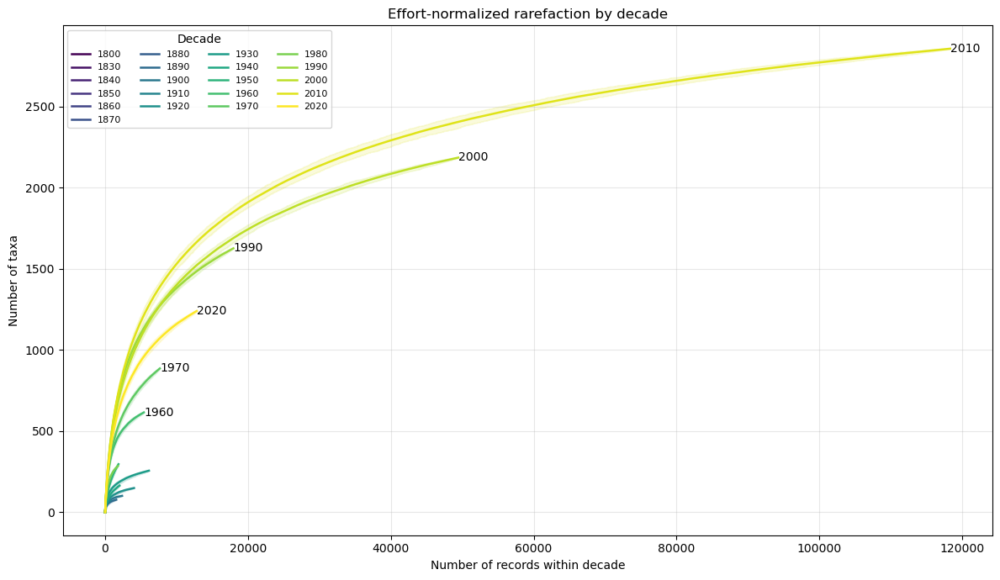

In [3]:
# 3) Plot Curves and Save CSVs
# This section saves the rarefaction data to CSV files and creates a plot with mean curves and confidence intervals for each decade.

import matplotlib.pyplot as plt
import numpy as np
# Save combined CSV
combined_csv = 'rarefaction_by_decade_combined.csv'
rarefaction_decades.to_csv(combined_csv, index=False)
# Save per-decade CSVs
per_decade_files = []
for d in sorted(rarefaction_decades['decade'].unique()):
    sub = rarefaction_decades[rarefaction_decades['decade'] == d]
    fn = f'rarefaction_decade_{int(d)}.csv'
    sub.to_csv(fn, index=False)
    per_decade_files.append(fn)
    
# Plot rarefaction curves
plt.figure(figsize=(12, 7))
decades_sorted = sorted(rarefaction_decades['decade'].unique())
colors = plt.cm.viridis(np.linspace(0, 1, len(decades_sorted)))
# Specify the decades to label
label_decades = [2010, 2000, 1990, 2020, 1970, 1960]
for color, d in zip(colors, decades_sorted):
    sub = rarefaction_decades[rarefaction_decades['decade'] == d]
    x = sub['records'].values
    y = sub['mean_unique_species'].values
    lo = sub['ci_lower'].values
    hi = sub['ci_upper'].values
    
    # Plot the line and confidence interval
    plt.plot(x, y, color=color, lw=1.8, label=str(int(d)))
    plt.fill_between(x, lo, hi, color=color, alpha=0.15)
    
    # Add labels for specific decades
    if d in label_decades:
        # Place the label at the last point of the curve
        plt.text(x[-1], y[-1], str(int(d)), color='black', fontsize=10, ha='left', va='center')
# Add plot labels and legend
plt.xlabel('Number of records within decade')
plt.ylabel('Number of taxa')
plt.title('Effort-normalized rarefaction by decade')
plt.legend(title='Decade', ncol=4, fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
# Save and show the plot
plot_file = 'effort_normalized_rarefaction_by_decade.png'
plt.savefig(plot_file, dpi=150)
plt.show()